## Modèles classiques : Random Forest, SVM et XGBoost

#### Objectif

Comparer l'ANN retenu à des modèles classiques réglés avec le même soin.

#### Principe directeur

Chaque modèle suit le même parcours que l'ANN : mêmes données, partitions, variables, graines et critères ; réglage des hyperparamètres, puis même menu de méthodes de rééquilibrage, avec la même règle de décision. Le test n'est utilisé qu'à l'évaluation finale.

### 1. Partie commune

#### 1.1 Importations

In [49]:
import os
import json
import time
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from sklearn.svm import SVC

from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix)
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import RandomOverSampler, SMOTE

import shap
import joblib
from sklearn.metrics import cohen_kappa_score, precision_recall_fscore_support
from imblearn.pipeline import Pipeline

import keras
from keras import layers
import tensorflow as tf

#### 1.2 Données et partitions

Variables et graines de l'ANN final (configuration F3 de l'expérience F) ; découpage identique à celui de l'expérience A.

In [2]:
# Préparation des données propres à partir du jeu brut (mêmes étapes que le notebook d'analyse exploratoire)
import geopandas as gpd
from shapely.wkt import loads

brut = pd.read_csv("Data_Yakro_New.csv").drop_duplicates()
gdf = gpd.GeoDataFrame(brut, geometry=brut["geometry"].astype(str).str.strip().apply(loads), crs="EPSG:32630")
gdf["x"], gdf["y"] = gdf.geometry.x, gdf.geometry.y
geo = gdf.to_crs(epsg=4326)
gdf["lon"], gdf["lat"] = geo.geometry.x, geo.geometry.y
gdf["class_name_origine"], gdf["Classes1_origine"] = gdf["class_name"], gdf["Classes1"]
code_classe = dict(zip(gdf["class_name"], gdf["Classes1"]))
for i, classe in {193: "Wetlands", 732: "Savannas"}.items():     # étiquettes corrigées (analyse exploratoire, 4.3.2)
    gdf.loc[gdf["id"] == i, "class_name"] = classe
    gdf.loc[gdf["id"] == i, "Classes1"] = code_classe[classe]
# NDWI2 et NDBI, redondants avec NDMI, sont écartés (analyse exploratoire, 3.2)
colonnes = (["id", "Classes1", "class_name", "Classes1_origine", "class_name_origine"]
            + [f"B{i}" for i in range(1, 11)] + ["NDVI", "EVI", "NDRE", "SAVI", "NDMI", "NDWI", "MSI", "BSI", "BI"]
            + ["x", "y", "lon", "lat"])
data = pd.DataFrame(gdf[colonnes]).reset_index(drop=True)

# Variables et graines de l'ANN final (configuration F3 de l'expérience F)
BANDES = [f"B{i}" for i in range(1, 11)]
INDICES = ["NDVI", "EVI", "NDRE", "SAVI", "NDMI", "NDWI", "MSI", "BSI", "BI"]
VARIABLES = BANDES + INDICES                    # F3 : 10 bandes + 9 indices
GRAINES = [0, 1, 2, 3, 4]
SEED_PARTITION = 42
encodeur = LabelEncoder()
y = encodeur.fit_transform(data["class_name"])
NOMS_CLASSES = list(encodeur.classes_)
N_CLASSES = len(NOMS_CLASSES)

# Même découpage 70 / 15 / 15 que l'expérience A (même code, même graine)
idx = np.arange(len(y))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED_PARTITION)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y[idx_temp], random_state=SEED_PARTITION)

# Standardisation apprise sur l'entraînement
X = data[VARIABLES].to_numpy(dtype="float32")
normaliseur = StandardScaler().fit(X[idx_train])
X_train, y_train = normaliseur.transform(X[idx_train]), y[idx_train]
X_val, y_val = normaliseur.transform(X[idx_val]), y[idx_val]

DOSSIER_FINAL = os.path.join("resultats", "modeles_finaux")
COULEURS_CLASSES = {nom: plt.get_cmap("tab10")(i) for i, nom in enumerate(sorted(NOMS_CLASSES))}
noms_courts = [n.split(" ")[0] for n in NOMS_CLASSES]
print(f"{len(VARIABLES)} variables | entraînement : {len(idx_train)} | validation : {len(idx_val)} | test (non utilisé) : {len(idx_test)}")

19 variables | entraînement : 700 | validation : 150 | test (non utilisé) : 150


#### 1.3 Fonctions communes

Métriques, évaluation sur la validation et bandes de chevauchement.

In [3]:
def calculer_metriques(y_vrai, y_pred):
    """Mêmes métriques que pour l'ANN."""
    return {
        "accuracy": accuracy_score(y_vrai, y_pred),
        "precision_macro": precision_score(y_vrai, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_pondere": f1_score(y_vrai, y_pred, average="weighted", zero_division=0),
        "mcc": matthews_corrcoef(y_vrai, y_pred),
    }


def evaluer(fabrique, graine, nom):
    """Entraîne un modèle (fabrique(graine) le crée) sur l'entraînement et l'évalue sur la validation."""
    modele = fabrique(graine)
    debut = time.perf_counter()
    modele.fit(X_train, y_train)
    duree = time.perf_counter() - debut
    pred_train, pred_val = modele.predict(X_train), modele.predict(X_val)
    m_train, m_val = calculer_metriques(y_train, pred_train), calculer_metriques(y_val, pred_val)
    ligne = {"config": nom, "graine": graine, "temps_s": duree,
             **{f"val_{k}": v for k, v in m_val.items()},
             "train_f1_macro": m_train["f1_macro"],
             "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"]}
    f1_classes = f1_score(y_val, pred_val, average=None, labels=range(N_CLASSES), zero_division=0)
    return ligne, f1_classes, pred_val


def bandes_chevauchement(df, configs, reference, titre, etiquette_ref):
    """Bandes moyenne ± écart-type sur les 5 critères, comparées à la référence (même code que pour l'ANN)."""
    criteres = [("val_f1_macro", "Macro-F1 val"), ("val_recall_macro", "Rappel macro val"),
                ("val_precision_macro", "Précision macro val"), ("val_accuracy", "Accuracy val\n(complément)"),
                ("ecart_f1_train_val", "Écart\nF1 train - val")]
    stats = df.groupby("config")[[c for c, _ in criteres]].agg(["mean", "std"]).loc[configs]
    fig, axes = plt.subplots(1, len(criteres), figsize=(24, 1.6 + 1.1 * len(configs)), sharey=True)
    y_pos = np.arange(len(configs))[::-1]
    for ax, (col, t) in zip(axes, criteres):
        m, s = stats[(col, "mean")], stats[(col, "std")].fillna(0)
        bas_ref, haut_ref = m[reference] - s[reference], m[reference] + s[reference]
        ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")
        for yi, cfg in zip(y_pos, configs):
            bas, haut = m[cfg] - s[cfg], m[cfg] + s[cfg]
            c = "#8a96a3" if cfg == reference else ("#2e5c8b" if bas <= haut_ref and haut >= bas_ref else "#c0392b")
            ax.plot([bas, haut], [yi, yi], color=c, lw=6, solid_capstyle="round")
            ax.plot(m[cfg], yi, "o", color="white", mec=c, mew=2.5, ms=10)
            ax.text(haut, yi, f"  {m[cfg]:.3f}", va="center", fontsize=11, color=c)
        ax.set_title(t, fontsize=13)
        ax.margins(x=0.35, y=0.3)
        ax.grid(axis="x", alpha=0.3)
    axes[0].set_yticks(y_pos, configs)
    axes[0].tick_params(axis="y", labelsize=12)
    legende = [Line2D([0], [0], color="#8a96a3", lw=6, label=etiquette_ref),
               Line2D([0], [0], color="#2e5c8b", lw=6, label="chevauchement : différence non nette"),
               Line2D([0], [0], color="#c0392b", lw=6, label="écart net")]
    fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.97), frameon=False, fontsize=12)
    fig.suptitle(titre, fontsize=15, y=1.06)
    plt.tight_layout(rect=[0, 0, 1, 0.88])
    plt.show()

#### 1.4 Référence ANN et blocs spatiaux

Résultats de l'ANN retenu et mêmes plis aléatoires et spatiaux.

In [4]:
# Mêmes blocs et mêmes plis que pour l'ANN (entraînement + validation)
idx_dev = np.concatenate([idx_train, idx_val])
y_dev = np.concatenate([y_train, y_val])
coords_dev = data.loc[idx_dev, ["x", "y"]].to_numpy()
blocs_dev = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(coords_dev)
PLIS = {"aléatoire": list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(idx_dev, y_dev)),
        "spatiale": list(GroupKFold(n_splits=5).split(idx_dev, y_dev, groups=blocs_dev))}


def validation_croisee(fabrique, nom, graine=0):
    """Validation croisée aléatoire et spatiale (5 plis chacune), avec la standardisation apprise dans chaque pli."""
    X_dev = data.loc[idx_dev, VARIABLES].to_numpy(dtype="float32")
    lignes = []
    for schema, plis in PLIS.items():
        for p, (i_app, i_test) in enumerate(plis):
            norm = StandardScaler().fit(X_dev[i_app])
            modele = fabrique(graine).fit(norm.transform(X_dev[i_app]), y_dev[i_app])
            pred = modele.predict(norm.transform(X_dev[i_test]))
            vrai = y_dev[i_test]
            lignes.append({"config": nom, "validation": schema, "pli": p,
                           "f1_macro": f1_score(vrai, pred, average="macro", zero_division=0),
                           "rappel_macro": recall_score(vrai, pred, average="macro", zero_division=0),
                           "accuracy": accuracy_score(vrai, pred)})
    return pd.DataFrame(lignes)


# Résultats de l'ANN retenu (F3, 5 graines) : même modèle, mêmes graines et même code que l'expérience F
REF_ANN = "ANN (référence)"
tf.get_logger().setLevel("ERROR")
COUCHES_ANN, ACTIVATION_ANN = [128, 64, 32], "gelu"     # ANN-3, GELU
LR_ANN, MOMENTUM_ANN = 0.01, 0.5                         # SGD + Momentum
TAILLE_LOT, EPOCHS_MAX, PATIENCE = 32, 200, 20           # arrêt anticipé seul


def construire_ann(n_entrees):
    """ANN-3 avec GELU et SGD + Momentum (configuration finale de l'expérience F)."""
    modele = keras.Sequential(name="ANN_3_F")
    modele.add(keras.Input(shape=(n_entrees,)))
    for n in COUCHES_ANN:
        modele.add(layers.Dense(n))
        modele.add(layers.Activation(ACTIVATION_ANN))
    modele.add(layers.Dense(N_CLASSES, activation="softmax"))
    modele.compile(optimizer=keras.optimizers.SGD(learning_rate=LR_ANN, momentum=MOMENTUM_ANN),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modele


def entrainer_ann(X_app, y_app, X_arret, y_arret, graine):
    """Entraîne l'ANN ; X_arret / y_arret servent à l'arrêt anticipé."""
    keras.utils.set_random_seed(graine)
    modele = construire_ann(X_app.shape[1])
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    debut = time.perf_counter()
    modele.fit(X_app, y_app, validation_data=(X_arret, y_arret), epochs=EPOCHS_MAX, batch_size=TAILLE_LOT,
               callbacks=[arret, keras.callbacks.TerminateOnNaN()], verbose=0)
    return modele, time.perf_counter() - debut


lignes_ann = []
for graine in GRAINES:
    modele, duree = entrainer_ann(X_train, y_train, X_val, y_val, graine)
    pred_train = modele.predict(X_train, verbose=0).argmax(axis=1)
    pred_val = modele.predict(X_val, verbose=0).argmax(axis=1)
    m_train, m_val = calculer_metriques(y_train, pred_train), calculer_metriques(y_val, pred_val)
    lignes_ann.append({"config": REF_ANN, "graine": graine, "temps_s": duree,
                       **{f"val_{k}": v for k, v in m_val.items()},
                       "train_f1_macro": m_train["f1_macro"],
                       "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"]})
ann = pd.DataFrame(lignes_ann)

# Validation croisée aléatoire et spatiale de l'ANN (graine 0) : 15 % de la partie apprentissage pour l'arrêt anticipé
X_dev_ann = data.loc[idx_dev, VARIABLES].to_numpy(dtype="float32")
lignes_vc = []
for schema, plis in PLIS.items():
    for p, (i_app, i_test) in enumerate(plis):
        norm = StandardScaler().fit(X_dev_ann[i_app])
        X_app, X_test = norm.transform(X_dev_ann[i_app]), norm.transform(X_dev_ann[i_test])
        y_app = y_dev[i_app]
        effectifs = np.bincount(y_app, minlength=N_CLASSES)
        strat = y_app if effectifs[effectifs > 0].min() >= 2 else None
        i_a, i_v = train_test_split(np.arange(len(i_app)), test_size=0.15, stratify=strat, random_state=0)
        modele, _ = entrainer_ann(X_app[i_a], y_app[i_a], X_app[i_v], y_app[i_v], 0)
        pred, vrai = modele.predict(X_test, verbose=0).argmax(axis=1), y_dev[i_test]
        lignes_vc.append({"config": REF_ANN, "validation": schema, "pli": p,
                          "f1_macro": f1_score(vrai, pred, average="macro", zero_division=0),
                          "rappel_macro": recall_score(vrai, pred, average="macro", zero_division=0),
                          "accuracy": accuracy_score(vrai, pred)})
ann_vc = pd.DataFrame(lignes_vc)

print(f"ANN de référence : Macro-F1 val = {ann['val_f1_macro'].mean():.3f} ± {ann['val_f1_macro'].std():.3f}")

ANN de référence : Macro-F1 val = 0.389 ± 0.041


### 2. Random Forest

#### 2.1 Recherche des hyperparamètres

18 combinaisons × 5 graines, 530 arbres, sans correction du déséquilibre. On retient le meilleur Macro-F1 moyen en validation.

In [5]:

GRILLE_RF = {
    "n_estimators": [530],
    "max_features": ["sqrt", 0.5],
    "min_samples_leaf": [1, 3, 5],
    "max_depth": [None, 10, 20],
}
combinaisons = [dict(zip(GRILLE_RF, v)) for v in product(*GRILLE_RF.values())]
print(f"{len(combinaisons)} combinaisons x {len(GRAINES)} graines = {len(combinaisons) * len(GRAINES)} entraînements")


def fabrique_rf(params):
    """Renvoie une fonction qui crée une forêt avec ces hyperparamètres et une graine donnée."""
    return lambda graine: RandomForestClassifier(**params, random_state=graine, n_jobs=-1)


grille_rf, PARAMS_GRILLE = [], {}
for params in combinaisons:
    nom = f"mf={params['max_features']} | leaf={params['min_samples_leaf']} | depth={params['max_depth']}"
    PARAMS_GRILLE[nom] = params
    for graine in GRAINES:
        ligne, _, _ = evaluer(fabrique_rf(params), graine, nom)
        grille_rf.append(ligne)
grille_rf = pd.DataFrame(grille_rf)

# Classement des combinaisons par Macro-F1 moyen en validation
recap_grille = (grille_rf.groupby("config")
                .agg(f1=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std"),
                     rappel=("val_recall_macro", "mean"), ecart=("ecart_f1_train_val", "mean"))
                .sort_values("f1", ascending=False))
display(recap_grille.round(3))

MEILLEUR_RF = recap_grille.index[0]
PARAMS_RF = PARAMS_GRILLE[MEILLEUR_RF]
print("Combinaison retenue :", MEILLEUR_RF, "->", PARAMS_RF)

18 combinaisons x 5 graines = 90 entraînements


,f1,f1_sd,rappel,ecart
config,,,,
mf=sqrt | leaf=1 | depth=20,0.386,0.035,0.374,0.614
mf=sqrt | leaf=1 | depth=None,0.384,0.038,0.372,0.616
mf=sqrt | leaf=1 | depth=10,0.378,0.043,0.365,0.449
mf=0.5 | leaf=1 | depth=20,0.376,0.017,0.375,0.624
mf=0.5 | leaf=1 | depth=None,0.375,0.018,0.374,0.625
mf=0.5 | leaf=3 | depth=None,0.359,0.007,0.360,0.353
mf=0.5 | leaf=3 | depth=20,0.359,0.007,0.360,0.353
mf=sqrt | leaf=3 | depth=None,0.359,0.006,0.358,0.327
mf=0.5 | leaf=5 | depth=20,0.359,0.006,0.359,0.248


Combinaison retenue : mf=sqrt | leaf=1 | depth=20 -> {'n_estimators': 530, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'max_depth': 20}


La recherche d’hyperparamètres (entraînement sur l’ensemble d’entraînement, choix sur la validation) retient une forêt de 530 arbres. À chaque question, chaque arbre choisit parmi 4 variables tirées au hasard sur les 19 (max_features = sqrt).Une feuille peut ne contenir qu’une observation (min_samples_leaf = 1), et la profondeur est limitée à 20 niveaux. Ces arbres très détaillés surapprendraient seuls, mais le vote de la forêt compense leurs excès.

#### 2.2 Résultats de la recherche

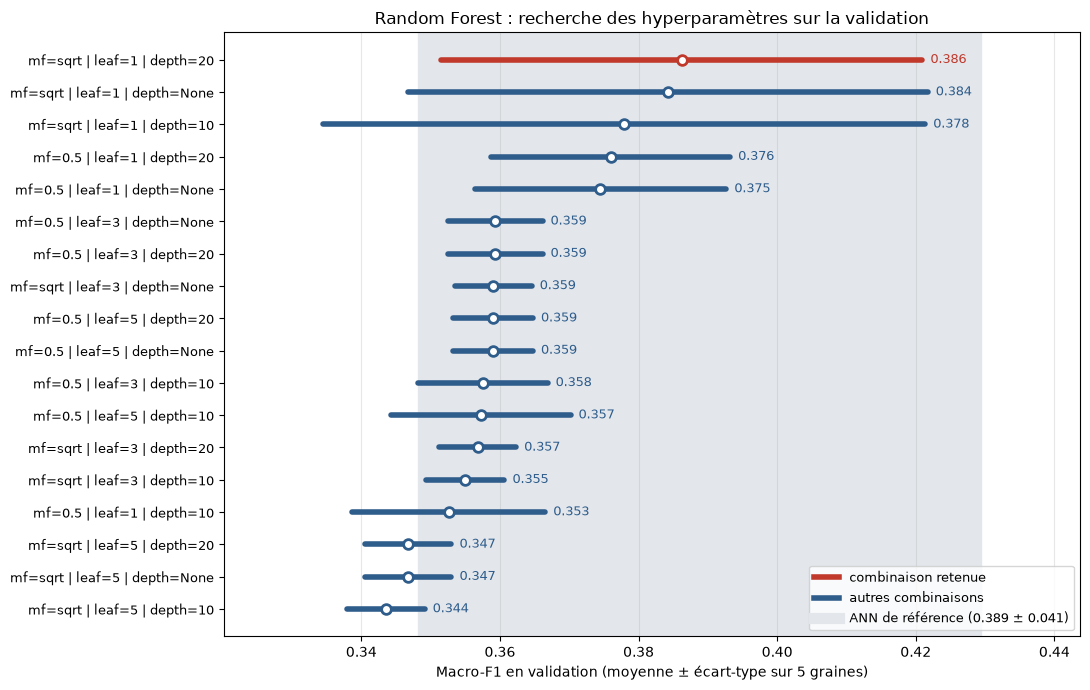

In [6]:
fig, ax = plt.subplots(figsize=(11, 7))
ordre = recap_grille.index[::-1]
for yi, cfg in enumerate(ordre):
    m, s = recap_grille.loc[cfg, "f1"], recap_grille.loc[cfg, "f1_sd"]
    c = "#c0392b" if cfg == MEILLEUR_RF else "#2e5c8b"
    ax.plot([m - s, m + s], [yi, yi], color=c, lw=4, solid_capstyle="round")
    ax.plot(m, yi, "o", color="white", mec=c, mew=2, ms=7)
    ax.text(m + s, yi, f"  {m:.3f}", va="center", fontsize=9, color=c)
m_ann, s_ann = ann["val_f1_macro"].mean(), ann["val_f1_macro"].std()
ax.axvspan(m_ann - s_ann, m_ann + s_ann, color="#e3e7ec", zorder=0)
ax.set_yticks(range(len(ordre)), ordre, fontsize=9)
ax.set_xlabel("Macro-F1 en validation (moyenne ± écart-type sur 5 graines)")
ax.margins(x=0.15)
ax.grid(axis="x", alpha=0.3)
ax.legend(handles=[Line2D([0], [0], color="#c0392b", lw=4, label="combinaison retenue"),
                   Line2D([0], [0], color="#2e5c8b", lw=4, label="autres combinaisons"),
                   Line2D([0], [0], color="#e3e7ec", lw=8, label=f"ANN de référence ({m_ann:.3f} ± {s_ann:.3f})")],
          loc="lower right", fontsize=9)
ax.set_title("Random Forest : recherche des hyperparamètres sur la validation")
plt.tight_layout()
plt.show()

Les combinaisons à feuilles plus grandes sont plus stables (écart-type d’environ 0,007), mais régulièrement moins bonnes (environ 0,359) : en simplifiant les arbres, elles renoncent à reconnaître les classes rares.

#### 2.3 Déséquilibre des classes

Mêmes méthodes que pour l'ANN : sans correction, poids de classe, suréchantillonnage, SMOTE.

In [7]:
# Même menu que pour l'ANN, appliqué à l'entraînement seulement
METHODES_DESEQ = ["Sans correction", "Poids de classe", "Suréchantillonnage", "SMOTE"]


class RFDeseq:
    """Random Forest + méthode de rééquilibrage, appliquée seulement aux données sur lesquelles on l'entraîne."""
    def __init__(self, methode, params, graine):
        self.methode, self.params, self.graine = methode, params, graine

    def fit(self, X, y):
        poids = None
        if self.methode == "Poids de classe":
            poids = "balanced"                                   # n / (K x n_k)
        elif self.methode == "Suréchantillonnage":
            X, y = RandomOverSampler(random_state=self.graine).fit_resample(X, y)
        elif self.methode == "SMOTE":
            effectifs = np.bincount(y)
            k = min(5, effectifs[effectifs > 0].min() - 1)         # k voisins : au plus la plus petite classe - 1
            echantillonneur = SMOTE(k_neighbors=k, random_state=self.graine) if k >= 1 else RandomOverSampler(random_state=self.graine)
            X, y = echantillonneur.fit_resample(X, y)
        self.foret_ = RandomForestClassifier(**self.params, class_weight=poids, random_state=self.graine, n_jobs=-1).fit(X, y)
        return self

    def predict(self, X):
        return self.foret_.predict(X)


resultats_deseq, rappels_deseq = [], {}
for methode in METHODES_DESEQ:
    for graine in GRAINES:
        ligne, _, pred = evaluer(lambda g: RFDeseq(methode, PARAMS_RF, g), graine, methode)
        resultats_deseq.append(ligne)
        rappels_deseq[(methode, graine)] = recall_score(y_val, pred, average=None, labels=range(N_CLASSES), zero_division=0)
    f1s = [r["val_f1_macro"] for r in resultats_deseq if r["config"] == methode]
    print(f"{methode:20s} | Macro-F1 val = {np.mean(f1s):.3f} ± {np.std(f1s, ddof=1):.3f}")
resultats_deseq = pd.DataFrame(resultats_deseq)

# Rappel par classe (moyenne sur 5 graines)
ordre_classes = np.argsort(np.bincount(y_train))[::-1]
rappel_classes = pd.DataFrame({m: np.mean([rappels_deseq[(m, g)] for g in GRAINES], axis=0)[ordre_classes]
                               for m in METHODES_DESEQ}, index=[noms_courts[k] for k in ordre_classes]).T


Sans correction      | Macro-F1 val = 0.386 ± 0.035
Poids de classe      | Macro-F1 val = 0.440 ± 0.004
Suréchantillonnage   | Macro-F1 val = 0.450 ± 0.012
SMOTE                | Macro-F1 val = 0.367 ± 0.017


Le suréchantillonnage donne le meilleur Macro-F1 en validation, synonime de meilleurs compromis entre la reconnaissance des classes et leur prediction 

#### 2.4 Choix de la méthode de rééquilibrage

On ne change que si le Macro-F1 progresse nettement par rapport à « Sans correction ».

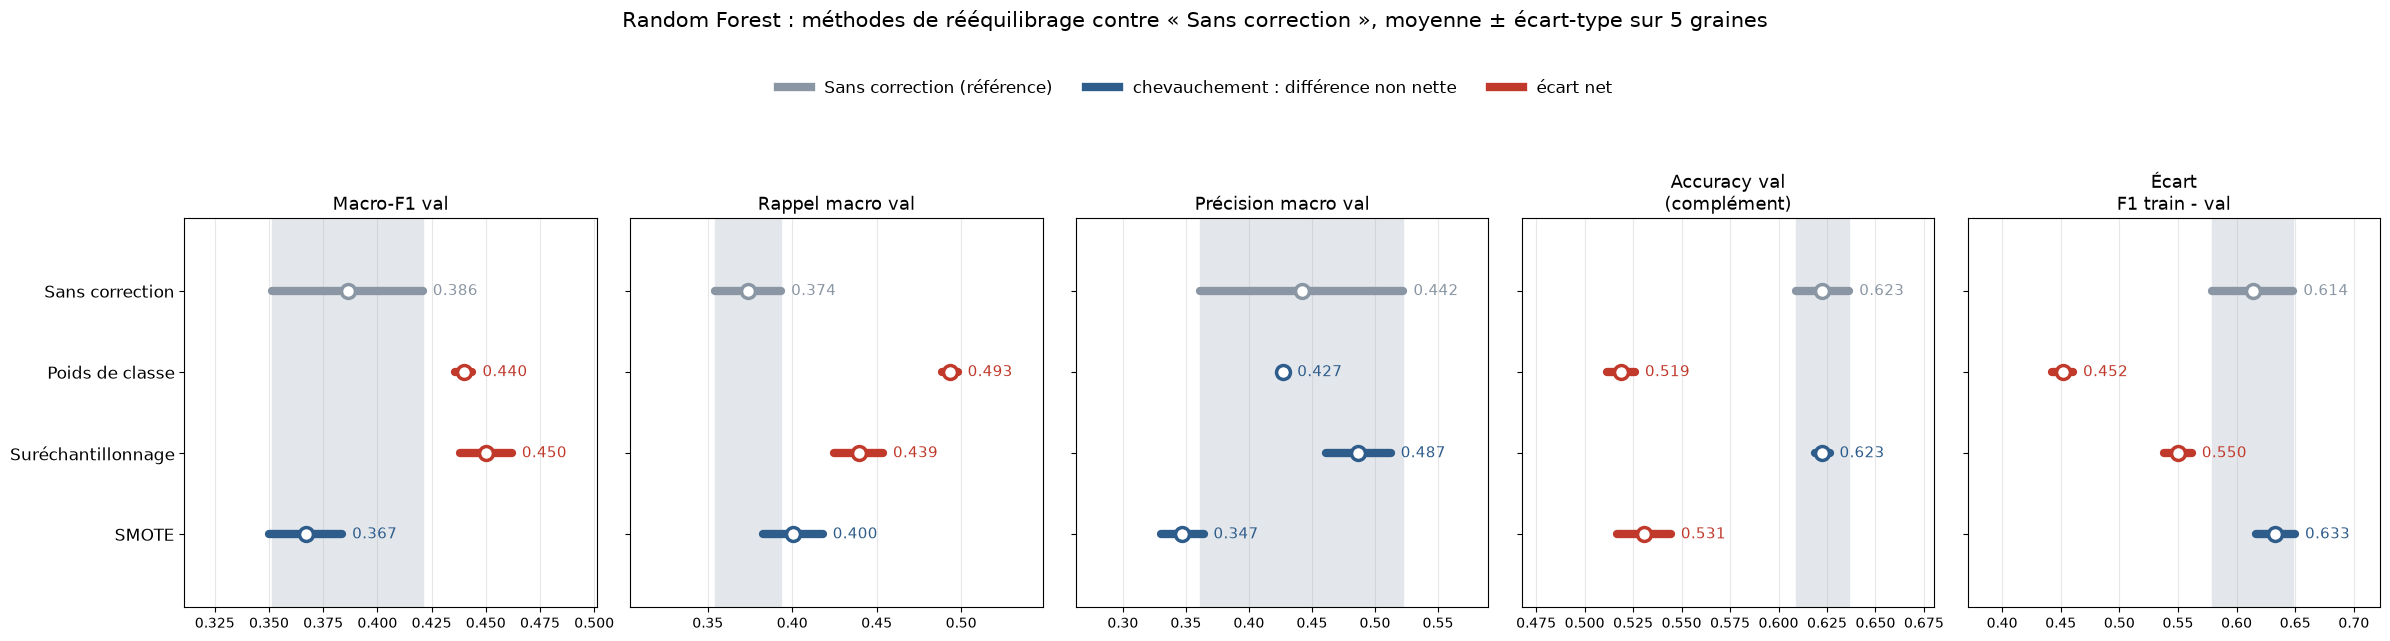

Méthodes avec un gain net de Macro-F1 : ['Poids de classe', 'Suréchantillonnage']
Méthode retenue sous reserve : Suréchantillonnage

Rappel par classe (moyenne sur 5 graines) :


,Rubber,Savannas,Coffee,Forest,Human,Wetlands,Water,Bare
Sans correction,0.84,0.07,0.41,0.23,0.33,0.10,1.0,0.0
Poids de classe,0.51,0.27,0.71,0.55,0.67,0.25,1.0,0.0
Suréchantillonnage,0.78,0.12,0.53,0.37,0.47,0.25,1.0,0.0
SMOTE,0.62,0.13,0.60,0.47,0.33,0.05,1.0,0.0


In [8]:
bandes_chevauchement(resultats_deseq, METHODES_DESEQ, "Sans correction",
                     "Random Forest : méthodes de rééquilibrage contre « Sans correction », moyenne ± écart-type sur 5 graines",
                     "Sans correction (référence)")

# Règle de l'ANN : on change seulement si le Macro-F1 progresse nettement
st = resultats_deseq.groupby("config")["val_f1_macro"].agg(["mean", "std"])
haut_ref = st.loc["Sans correction", "mean"] + st.loc["Sans correction", "std"]
nettes = [m for m in METHODES_DESEQ[1:] if st.loc[m, "mean"] - st.loc[m, "std"] > haut_ref]
METHODE_RF = max(nettes, key=lambda m: st.loc[m, "mean"]) if nettes else "Sans correction"
print("Méthodes avec un gain net de Macro-F1 :", nettes if nettes else "aucune")
print("Méthode retenue sous reserve :", METHODE_RF)

print("\nRappel par classe (moyenne sur 5 graines) :")

display(rappel_classes.round(2))

- le suréchantillonnage améliore nettement le Macro-F1 (0,450 contre 0,386) et le rappel macro (0,439 contre 0,374) sans faire baisser l’accuracy.Les classes minoritaires sont mieux reconnues (Coffee 0,53, Human 0,47, Forest 0,37, Wetlands 0,25) tandis que Rubber reste bien reconnu (0,78). L’eau est toujours parfaitement reconnue, mais Bare Soil jamais, et Savannas reste faible (0,12).

- Les poids de classe font aussi progresser le Macro-F1 (0,440), mais l’accuracy chute .
- SMOTE n’apporte aucun gain net. 

la forêt reconnaît mieux Coffee, Human, Wetlands et Savannas, au prix d’un Rubber (0,78 contre 0,90 avec ANN) et d’une Forest (0,37 contre 0,47 avec ANN) un peu en retrait. 
du fait qu'une forêt prédit presque parfaitement son entraînement, l'ecart train-val ne suffit donc pas à écarter un surapprentissage, que la validation croisée aléatoire et spatiale permettra de vérifier.

#### 2.5 Random Forest retenu


Réglages de RF.1 et suréchantillonnage  comparés à l’ANN de référence.

In [9]:
# Random Forest retenu (réglages de RF.1, rééquilibrage de RF.4) : 5 graines
NOM_RF = "Random Forest"
resultats_rf, f1_classes_rf, predictions_rf = [], {}, {}
for graine in GRAINES:
    ligne, f1c, pred = evaluer(lambda g: RFDeseq(METHODE_RF, PARAMS_RF, g), graine, NOM_RF)
    resultats_rf.append(ligne)
    f1_classes_rf[graine], predictions_rf[graine] = f1c, pred
resultats_rf = pd.DataFrame(resultats_rf)

# Tableau récapitulatif : ANN de référence contre Random Forest (moyenne ± écart-type sur 5 graines)
comparaison_rf = pd.concat([ann, resultats_rf], ignore_index=True)
cols = ["val_f1_macro", "val_recall_macro", "val_precision_macro", "val_mcc", "val_accuracy", "ecart_f1_train_val", "temps_s"]
recap_rf = comparaison_rf.groupby("config")[cols].agg(["mean", "std"]).loc[[REF_ANN, NOM_RF]]
tableau_rf = pd.DataFrame(index=recap_rf.index)
for c in cols:
    dec = 1 if c == "temps_s" else 3
    tableau_rf[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap_rf[(c, "mean")], recap_rf[(c, "std")])]


#### 2.6 Comparaison avec l'ANN

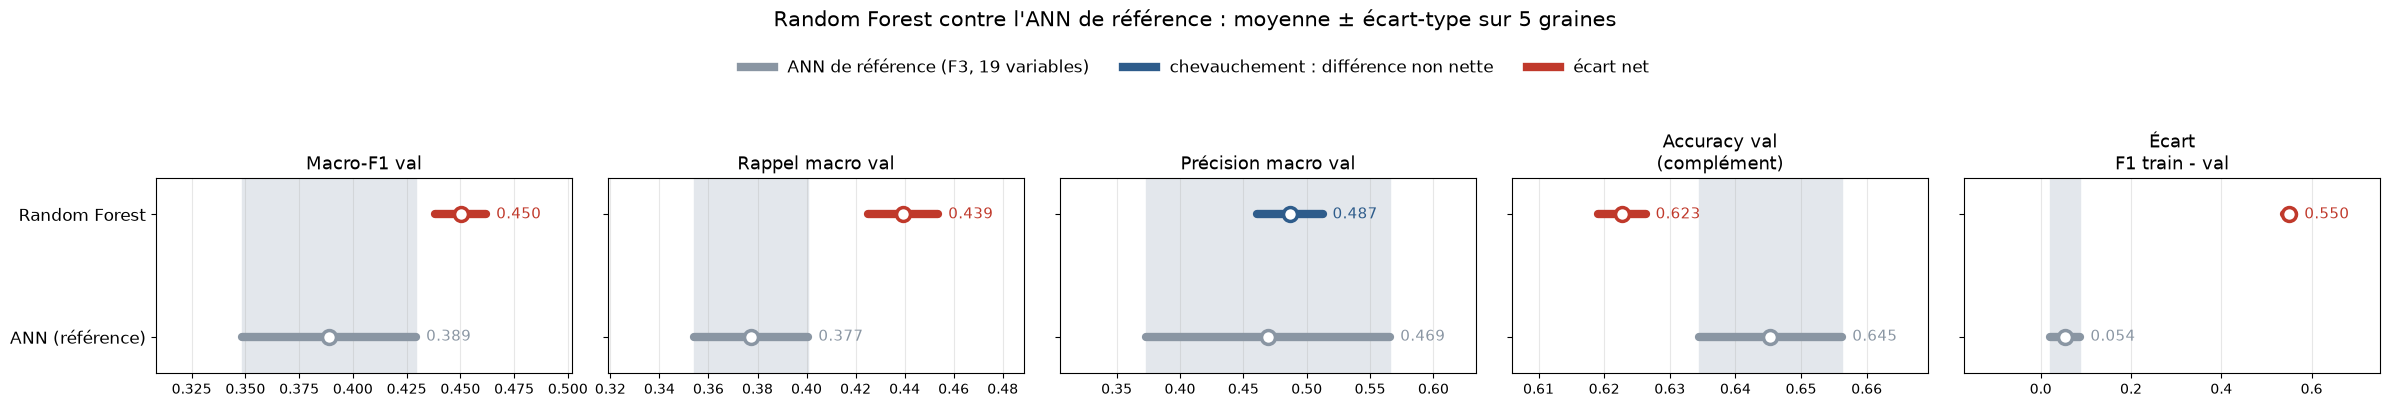

,val_f1_macro,val_recall_macro,val_precision_macro,val_mcc,val_accuracy,ecart_f1_train_val,temps_s
config,,,,,,,
ANN (référence),0.389 ± 0.041,0.377 ± 0.023,0.469 ± 0.097,0.330 ± 0.025,0.645 ± 0.011,0.054 ± 0.034,35.2 ± 3.4
Random Forest,0.450 ± 0.012,0.439 ± 0.014,0.487 ± 0.026,0.353 ± 0.013,0.623 ± 0.004,0.550 ± 0.012,3.4 ± 0.3


In [10]:
bandes_chevauchement(comparaison_rf, [NOM_RF, REF_ANN], REF_ANN,
                     "Random Forest contre l'ANN de référence : moyenne ± écart-type sur 5 graines",
                     "ANN de référence (F3, 19 variables)")

display(tableau_rf)

La forêt aléatoire, avec suréchantillonnage, se distingue nettement de l’ANN de référence : son Macro-F1  et son rappel macro présentent un écart net. Sa précision macro est un peu plus élevée en moyenne, mais les intervalles se chevauchent.
Il ressort donc que la forêt retrouve mieux les classes sans multiplier les fausses alarmes. Son accuracy est en revanche nettement plus basse car elle prédit un peu moins souvent Rubber, la classe majoritaire.

Ce résultat rejoint la littérature, selon laquelle les modèles à base d’arbres égalent ou dépassent souvent les réseaux de neurones sur des données tabulaires.

#### 2.7 F1 par classe et matrice de confusion

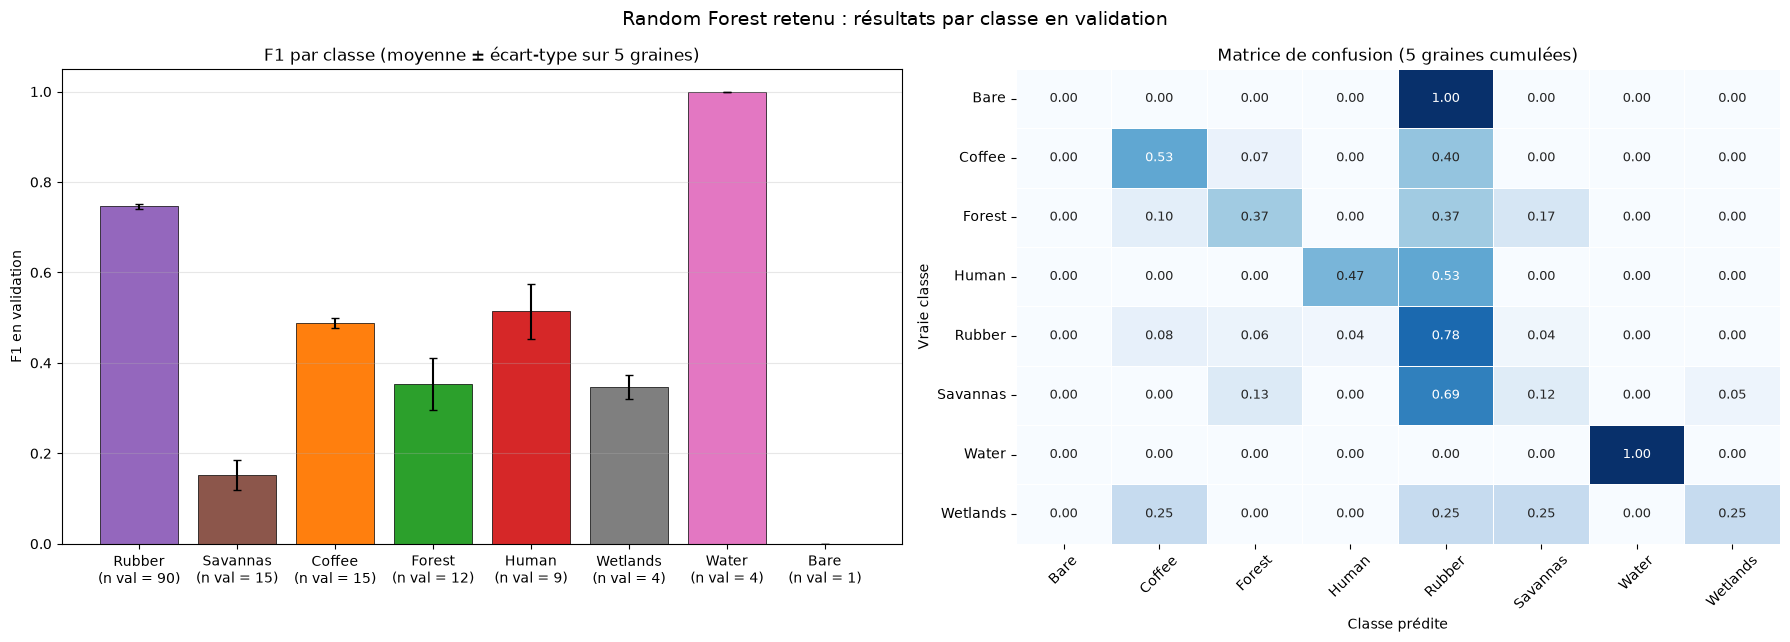

In [11]:
ordre_classes = np.argsort(np.bincount(y_train))[::-1]          # de la plus fréquente à la plus rare
f1s = np.array([f1_classes_rf[g] for g in GRAINES])[:, ordre_classes]

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].bar(range(N_CLASSES), f1s.mean(axis=0), yerr=f1s.std(axis=0), capsize=3,
            color=[COULEURS_CLASSES[NOMS_CLASSES[k]] for k in ordre_classes], edgecolor="black", lw=0.5)
axes[0].set_xticks(range(N_CLASSES), [f"{noms_courts[k]}\n(n val = {np.sum(y_val == k)})" for k in ordre_classes])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("F1 en validation")
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_title("F1 par classe (moyenne ± écart-type sur 5 graines)")

cm = sum(confusion_matrix(y_val, predictions_rf[g], labels=range(N_CLASSES)) for g in GRAINES)
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=noms_courts, yticklabels=noms_courts, annot_kws={"fontsize": 9},
            linewidths=0.5, linecolor="white", ax=axes[1])
axes[1].set_xlabel("Classe prédite")
axes[1].set_ylabel("Vraie classe")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)
axes[1].set_title("Matrice de confusion (5 graines cumulées)")
fig.suptitle("Random Forest retenu : résultats par classe en validation", fontsize=14)
plt.tight_layout()
plt.show()

Comme pour l’ANN, plusieurs classes restent confondues avec Rubber : Savannas (69 % de ses observations prédites Rubber), Human (53 %), Coffee (40 %) et Forest (37 %). Bare Soil, avec une seule observation en validation, est toujours classée Rubber.

Les classes minoritaires sont cependant mieux reconnues qu’avec l’ANN : Coffee (rappel de 0,53), Human (0,47) et Wetlands (0,25). 
Water reste parfaitement reconnue (F1 = 1,00), et Rubber garde un F1 élevé et très stable entre graines (environ 0,75). Forest se partage entre Rubber (37 %), Savannas (17 %) et Coffee (10 %).  les confusions entre classes végétales comme c'est le cas de wetland rejoignent la proximité de leurs signatures spectrales observée dans l’analyse exploratoire.

#### 2.8 Validation aléatoire et spatiale

f1_macro   rappel_macro       accuracy
config             validation                                             
ANN (référence)    aléatoire   0.361 ± 0.033  0.350 ± 0.026  0.641 ± 0.011
                   spatiale    0.288 ± 0.070  0.291 ± 0.074  0.636 ± 0.103
RF sans correction aléatoire   0.373 ± 0.071  0.353 ± 0.058  0.633 ± 0.043
                   spatiale    0.251 ± 0.085  0.252 ± 0.073  0.617 ± 0.106
Random Forest      aléatoire   0.416 ± 0.060  0.400 ± 0.055  0.604 ± 0.049
                   spatiale    0.333 ± 0.104  0.329 ± 0.101  0.601 ± 0.051

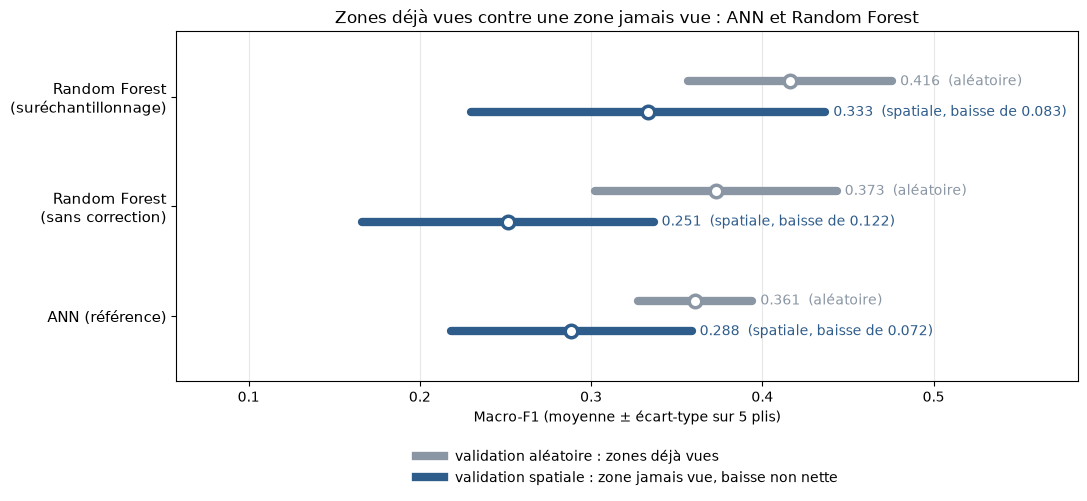

In [12]:
# On ajoute la forêt sans correction : si le suréchantillonnage faisait surapprendre, son gain disparaîtrait en spatial
NOM_RF_REF = "RF sans correction"
vc_rf = validation_croisee(lambda g: RFDeseq(METHODE_RF, PARAMS_RF, g), NOM_RF)
vc_rf_ref = validation_croisee(lambda g: RFDeseq("Sans correction", PARAMS_RF, g), NOM_RF_REF)
vc = pd.concat([ann_vc, vc_rf_ref, vc_rf], ignore_index=True)
recap_vc = vc.groupby(["config", "validation"])[["f1_macro", "rappel_macro", "accuracy"]].agg(["mean", "std"])
tableau_vc = pd.DataFrame(index=recap_vc.index)
for c in ["f1_macro", "rappel_macro", "accuracy"]:
    tableau_vc[c] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(recap_vc[(c, "mean")], recap_vc[(c, "std")])]
display(tableau_vc)

modeles_vc = [NOM_RF, NOM_RF_REF, REF_ANN]                       # de haut en bas : RF retenu, RF sans correction, ANN
etiquettes_vc = {NOM_RF: f"Random Forest\n({METHODE_RF.lower()})", NOM_RF_REF: "Random Forest\n(sans correction)", REF_ANN: "ANN (référence)"}
fig, ax = plt.subplots(figsize=(11, 5.2))
for yi, config in enumerate(modeles_vc[::-1]):
    m_a, s_a = recap_vc.loc[(config, "aléatoire"), ("f1_macro", "mean")], recap_vc.loc[(config, "aléatoire"), ("f1_macro", "std")]
    m_s, s_s = recap_vc.loc[(config, "spatiale"), ("f1_macro", "mean")], recap_vc.loc[(config, "spatiale"), ("f1_macro", "std")]
    c_s = "#c0392b" if (m_s + s_s < m_a - s_a) else "#2e5c8b"
    for m, s, c, dy, nom in [(m_a, s_a, "#8a96a3", 0.14, "aléatoire"), (m_s, s_s, c_s, -0.14, "spatiale")]:
        ax.plot([m - s, m + s], [yi + dy, yi + dy], color=c, lw=6, solid_capstyle="round")
        ax.plot(m, yi + dy, "o", color="white", mec=c, mew=2.5, ms=9)
        ax.text(m + s, yi + dy, f"  {m:.3f}  ({nom}, baisse de {m_a - m_s:.3f})" if nom == "spatiale" else f"  {m:.3f}  ({nom})",
                va="center", fontsize=10, color=c)
ax.set_yticks(range(len(modeles_vc)), [etiquettes_vc[c] for c in modeles_vc[::-1]], fontsize=11)
ax.set_xlabel("Macro-F1 (moyenne ± écart-type sur 5 plis)")
ax.margins(x=0.35, y=0.2)
ax.grid(axis="x", alpha=0.3)
ax.legend(handles=[Line2D([0], [0], color="#8a96a3", lw=6, label="validation aléatoire : zones déjà vues"),
                   Line2D([0], [0], color="#2e5c8b", lw=6, label="validation spatiale : zone jamais vue, baisse non nette"),],
          loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=1, frameon=False, fontsize=10)
ax.set_title("Zones déjà vues contre une zone jamais vue : ANN et Random Forest")
plt.tight_layout()
plt.show()

En validation spatiale, tous les modèles perdent en performance. Certaines classes sont concentrées dans une seule zone : l’eau, par exemple, se trouve presque entièrement dans le bloc 2. Quand ce bloc sert de test, les modèles n’ont presque jamais vu d’eau à l’entraînement et ne peuvent pas la reconnaître, ce qui fait baisser le Macro-F1. 
Quelle que soit la validation, la forêt suréchantillonnée reste en tête en moyenne (0,416 en aléatoire, 0,333 en spatial), même si les intervalles se chevauchent. Elle ne montre pas de signe de surapprentissage lié aux copies : son Macro-F1 baisse moins que celui de la forêt sans correction en zone nouvelle. L’ANN reste le plus stable d’une zone à l’autre (baisse de 0,072), mais à un niveau plus bas.

#### 2.9 Apercu de l'arbre

530 arbres ; profondeur réelle des 3 premiers : [16, 20, 16]


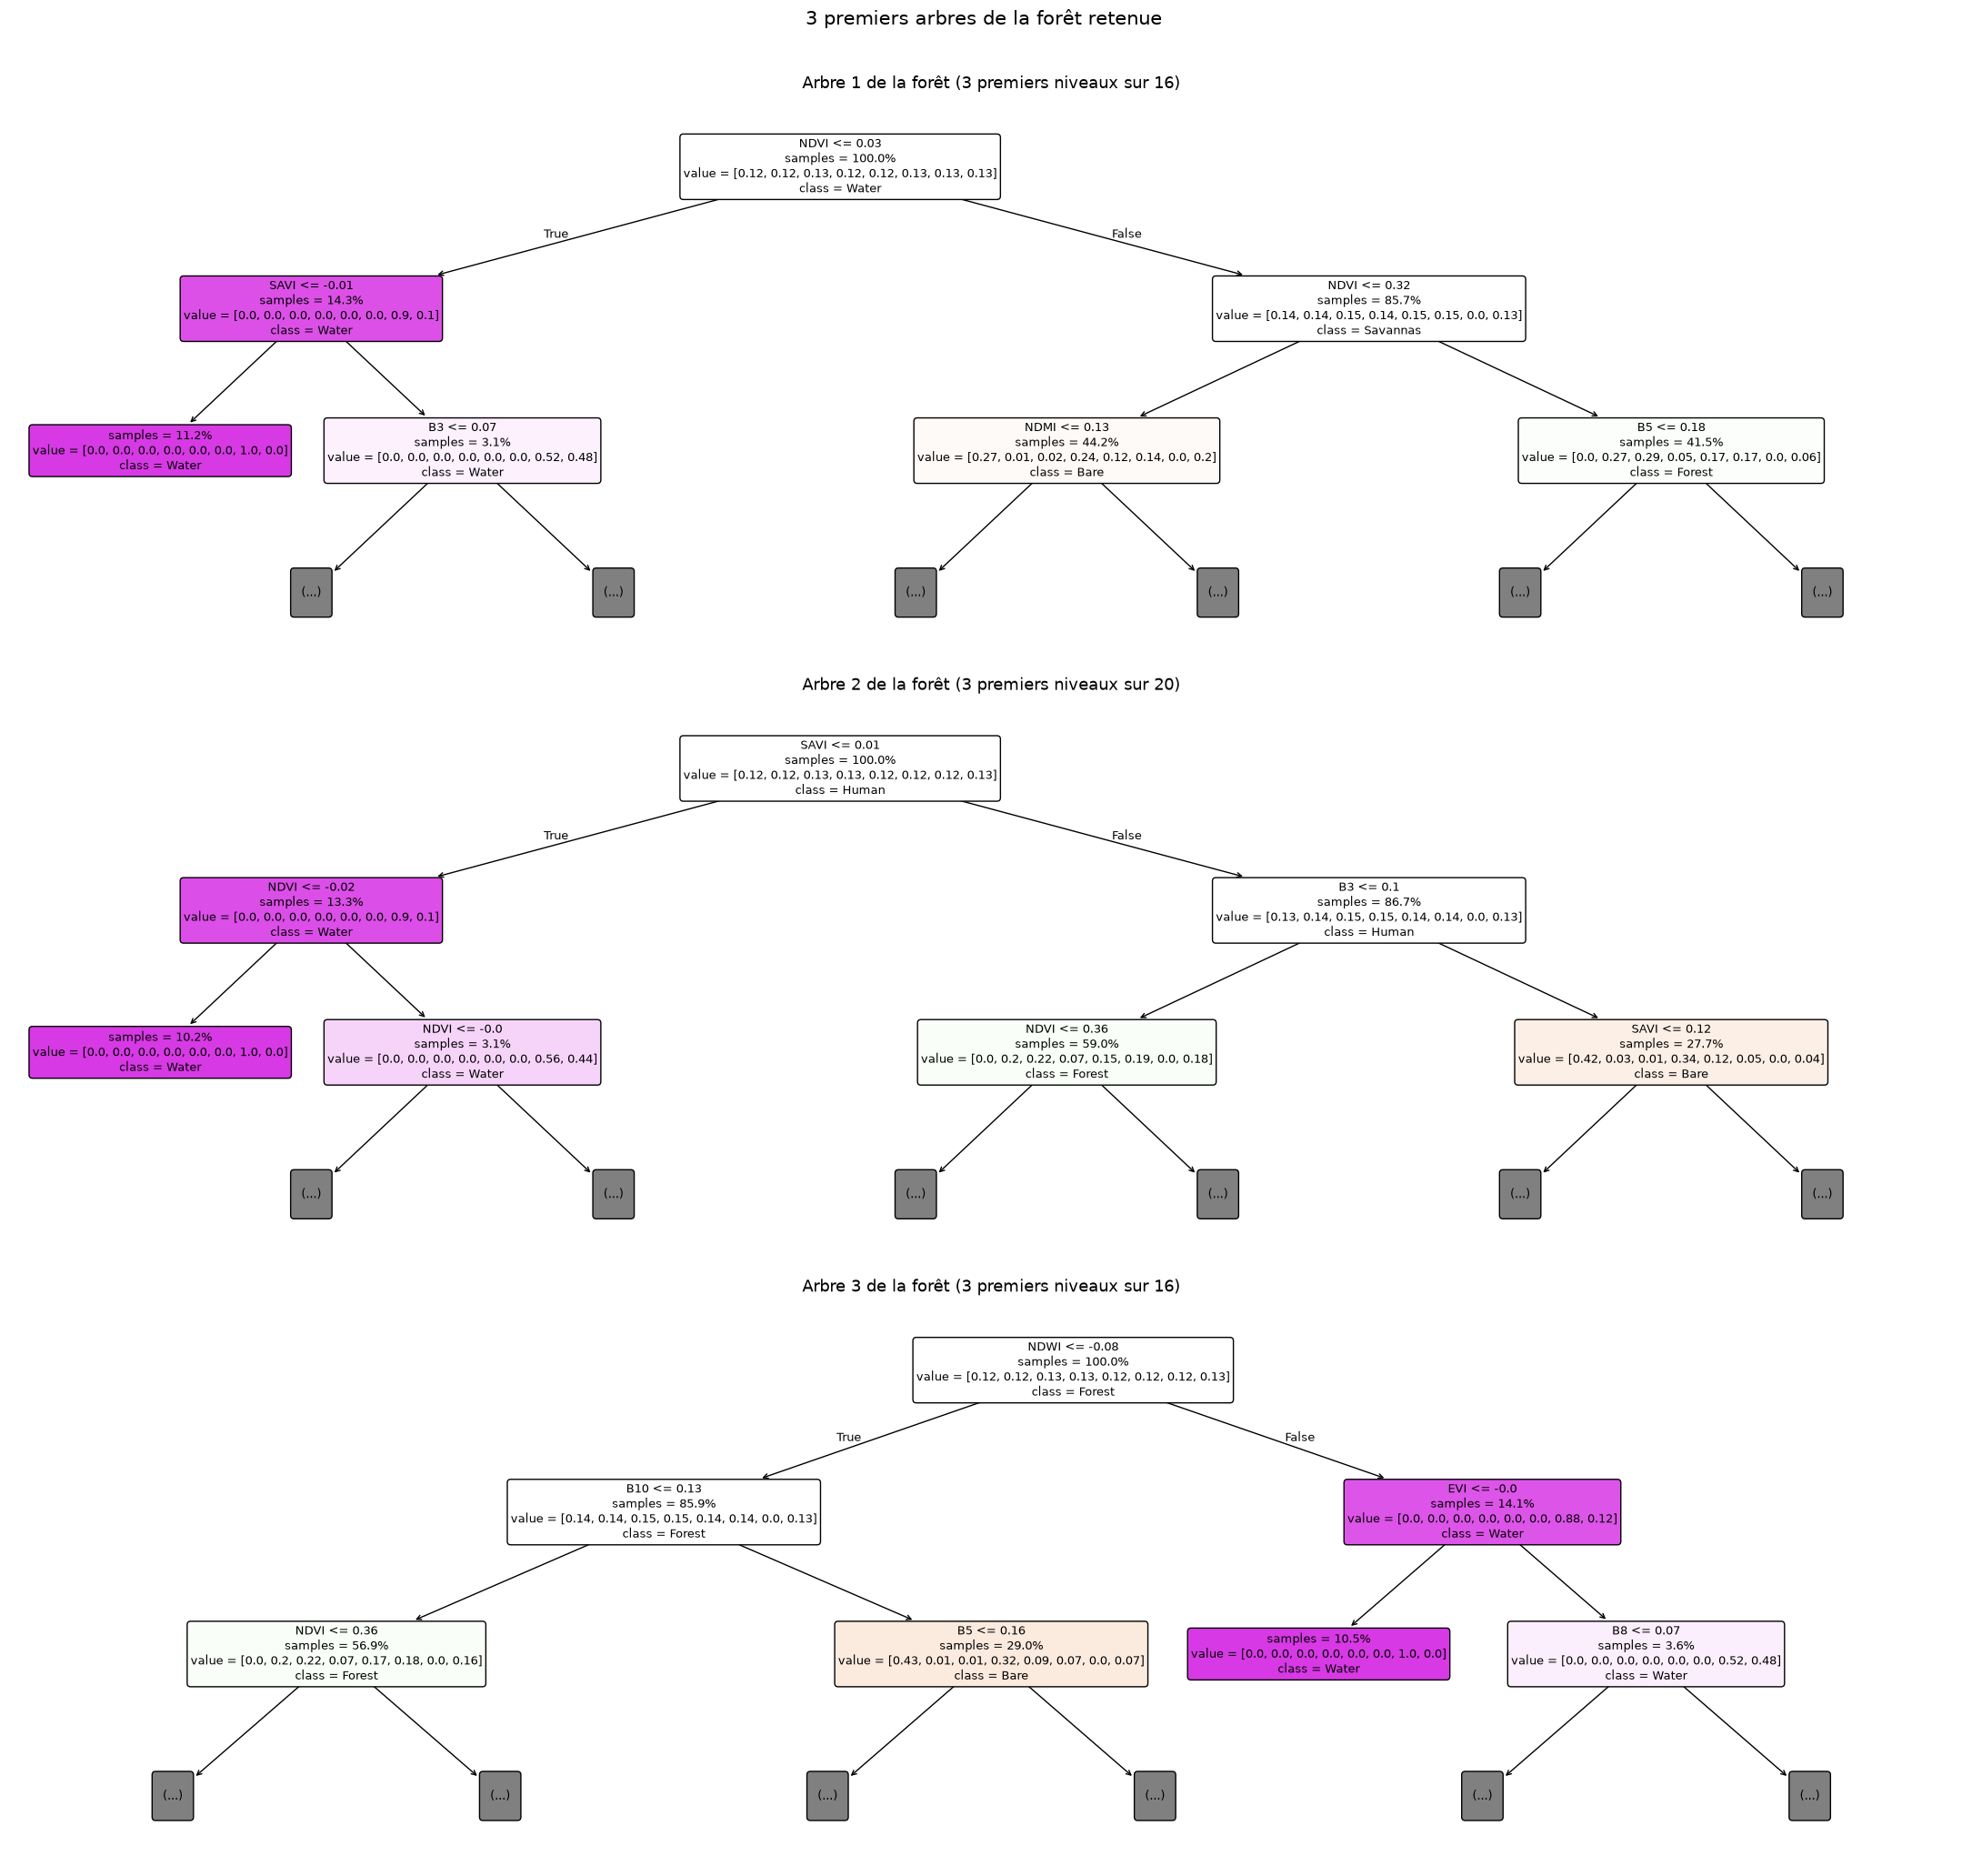

In [13]:

from sklearn.tree import plot_tree

X_brut_train = data.loc[idx_train, VARIABLES].to_numpy(dtype="float32")
foret_affichage = RFDeseq(METHODE_RF, PARAMS_RF, GRAINES[0]).fit(X_brut_train, y_train).foret_
print(f"{len(foret_affichage.estimators_)} arbres ; profondeur réelle des 3 premiers :",
      [a.get_depth() for a in foret_affichage.estimators_[:3]])

fig, axes = plt.subplots(3, 1, figsize=(22, 21))
for k, ax in enumerate(axes):
    plot_tree(foret_affichage.estimators_[k], max_depth=2, feature_names=VARIABLES, class_names=noms_courts,
              filled=True, rounded=True, impurity=False, proportion=True, precision=2, fontsize=9, ax=ax)
    ax.set_title(f"Arbre {k + 1} de la forêt (3 premiers niveaux sur {foret_affichage.estimators_[k].get_depth()})", fontsize=13)
fig.suptitle("3 premiers arbres de la forêt retenue ", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

sur 530 arbre qui composent la foret , Les trois  premiers arbres affichés commencent chacun par une question différente (NDVI, SAVI ou NDWI), signe que le tirage au hasard des observations et des variables rend les arbres de la forêt différents les uns des autres. Tous isolent pourtant l’eau dès les premiers niveaux, ce qui confirme qu’elle est la classe la plus facile à séparer.

#### 2.10 Configuration finale

In [14]:
# Configuration finale du Random Forest, figée avant le test final
def moyenne_ecart(serie):
    return {"moyenne": round(float(serie.mean()), 3), "ecart_type": round(float(serie.std()), 3)}

CONFIG_RF_FINAL = {
    "modele": "Random Forest",
    "hyperparametres": PARAMS_RF,
    "choix_hyperparametres": "meilleur Macro-F1 moyen en validation (5 graines) parmi la grille",
    "grille": {k: [str(x) for x in v] for k, v in GRILLE_RF.items()},
    "desequilibre": METHODE_RF,
    "desequilibre_application": "entraînement seulement (validation et test intacts)",
    "desequilibre_regle": "changement seulement si gain net de Macro-F1 sur « Sans correction » (même règle que l'ANN)",
    "variables": VARIABLES,
    "n_variables": len(VARIABLES),
    "standardisation": "StandardScaler appris sur l'entraînement (sans effet sur les arbres)",
    "graines": GRAINES,
    "seed_partition": SEED_PARTITION,
    "validation_fixe": {                                  # 5 graines, validation de 150 observations
        "f1_macro": moyenne_ecart(resultats_rf["val_f1_macro"]),
        "rappel_macro": moyenne_ecart(resultats_rf["val_recall_macro"]),
        "precision_macro": moyenne_ecart(resultats_rf["val_precision_macro"]),
        "accuracy": moyenne_ecart(resultats_rf["val_accuracy"]),
    },
    "validation_croisee_dev": {                           # 5 plis, entraînement + validation
        schema: {"f1_macro_moyenne": round(float(recap_vc.loc[(NOM_RF, schema), ("f1_macro", "mean")]), 3),
                 "f1_macro_ecart_type": round(float(recap_vc.loc[(NOM_RF, schema), ("f1_macro", "std")]), 3)}
        for schema in PLIS},
}

print(json.dumps({k: v for k, v in CONFIG_RF_FINAL.items() if k != "variables"}, ensure_ascii=False, indent=2, default=str))

{
  "modele": "Random Forest",
  "hyperparametres": {
    "n_estimators": 530,
    "max_features": "sqrt",
    "min_samples_leaf": 1,
    "max_depth": 20
  },
  "choix_hyperparametres": "meilleur Macro-F1 moyen en validation (5 graines) parmi la grille",
  "grille": {
    "n_estimators": [
      "530"
    ],
    "max_features": [
      "sqrt",
      "0.5"
    ],
    "min_samples_leaf": [
      "1",
      "3",
      "5"
    ],
    "max_depth": [
      "None",
      "10",
      "20"
    ]
  },
  "desequilibre": "Suréchantillonnage",
  "desequilibre_application": "entraînement seulement (validation et test intacts)",
  "desequilibre_regle": "changement seulement si gain net de Macro-F1 sur « Sans correction » (même règle que l'ANN)",
  "n_variables": 19,
  "standardisation": "StandardScaler appris sur l'entraînement (sans effet sur les arbres)",
  "graines": [
    0,
    1,
    2,
    3,
    4
  ],
  "seed_partition": 42,
  "validation_fixe": {
    "f1_macro": {
      "moyenne": 0.45,
   

#### 2.11 Synthese Random Forest 

Synthèse de Random Forest

La forêt retenue (530 arbres, max_features = sqrt, avec suréchantillonnage) dépasse nettement l’ANN en Macro-F1 (0,450 contre 0,389) et reconnaît mieux les classes minoritaires, au prix d’une accuracy un peu plus basse. Elle reste en tête en zone nouvelle (0,333 contre 0,288), sans surapprentissage lié au suréchantillonnage.

Limites: Les confusions avec Rubber persistent pour Savannas, Human, Coffee et Forest, et Bare Soil n’est jamais reconnue (une seule observation en validation). Comme pour l’ANN, la limite principale reste la proximité spectrale entre classes végétales, que ni le modèle ni le rééquilibrage ne peuvent lever.

La configuration de la forêt est figée en 2.10. Elle sera comparée au SVM et à XGBoost avec le même protocole, puis évaluée une seule fois sur le jeu de test.

### 3. SVM

#### 3.1 Préparation

contrairement au au deux premiers modeles, il nous sera pas necessaire ici de fixer des graines.

In [15]:


CRITERES_BOOT = {"val_f1_macro": lambda v, p: f1_score(v, p, average="macro", zero_division=0),
                 "val_recall_macro": lambda v, p: recall_score(v, p, average="macro", zero_division=0),
                 "val_precision_macro": lambda v, p: precision_score(v, p, average="macro", zero_division=0),
                 "val_accuracy": accuracy_score}


def ecarts_bootstrap(pred, n=500, graine=0):
    """Écart-type de chaque critère quand on rééchantillonne la validation avec remise."""
    rng = np.random.default_rng(graine)
    tirages = [rng.integers(0, len(y_val), len(y_val)) for _ in range(n)]
    return {c: np.std([f(y_val[t], pred[t]) for t in tirages], ddof=1) for c, f in CRITERES_BOOT.items()}


def bandes_avec_ecarts(df, configs, reference, titre, etiquette_ref, ecarts=None):
    """Bandes de chevauchement ; « ecarts » remplace l'écart-type entre graines quand il est nul (SVM)."""
    criteres = [("val_f1_macro", "Macro-F1 val"), ("val_recall_macro", "Rappel macro val"),
                ("val_precision_macro", "Précision macro val"), ("val_accuracy", "Accuracy val\n(complément)"),
                ("ecart_f1_train_val", "Écart\nF1 train - val")]
    stats = df.groupby("config")[[c for c, _ in criteres]].agg(["mean", "std"]).loc[configs]
    fig, axes = plt.subplots(1, len(criteres), figsize=(24, 1.6 + 1.1 * len(configs)), sharey=True)
    y_pos = np.arange(len(configs))[::-1]
    for ax, (col, t) in zip(axes, criteres):
        m, s = stats[(col, "mean")], stats[(col, "std")].fillna(0).copy()
        if ecarts is not None:
            for cfg in configs:
                if cfg in ecarts:
                    s[cfg] = max(s[cfg], ecarts[cfg].get(col if col != "ecart_f1_train_val" else "val_f1_macro", 0))
        bas_ref, haut_ref = m[reference] - s[reference], m[reference] + s[reference]
        ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")
        for yi, cfg in zip(y_pos, configs):
            bas, haut = m[cfg] - s[cfg], m[cfg] + s[cfg]
            c = "#8a96a3" if cfg == reference else ("#2e5c8b" if bas <= haut_ref and haut >= bas_ref else "#c0392b")
            ax.plot([bas, haut], [yi, yi], color=c, lw=6, solid_capstyle="round")
            ax.plot(m[cfg], yi, "o", color="white", mec=c, mew=2.5, ms=10)
            ax.text(haut, yi, f"  {m[cfg]:.3f}", va="center", fontsize=11, color=c)
        ax.set_title(t, fontsize=13)
        ax.margins(x=0.35, y=0.3)
        ax.grid(axis="x", alpha=0.3)
    axes[0].set_yticks(y_pos, configs)
    axes[0].tick_params(axis="y", labelsize=12)
    legende = [Line2D([0], [0], color="#8a96a3", lw=6, label=etiquette_ref),
               Line2D([0], [0], color="#2e5c8b", lw=6, label="chevauchement : différence non nette"),
               Line2D([0], [0], color="#c0392b", lw=6, label="écart net")]
    fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.97), frameon=False, fontsize=12)
    fig.suptitle(titre, fontsize=15, y=1.06)
    plt.tight_layout(rect=[0, 0, 1, 0.88])
    plt.show()
    return stats, s

#### 3.2 Recherche des hyperparamètres

 grace à l'analyse exploratoire, nous sommes en mesure de nous pencher dans cette section sur un Noyau RBF, 16 combinaisons de `C` et `gamma`, sans correction du déséquilibre pour debuter. 

In [16]:
# Noyau RBF ; C = tolérance aux erreurs, gamma = portée de l'influence d'un point
GRILLE_SVM = {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1, 1]}
combinaisons_svm = [dict(zip(GRILLE_SVM, v)) for v in product(*GRILLE_SVM.values())]
print(f"{len(combinaisons_svm)} combinaisons (une seule évaluation chacune : le SVM ne dépend pas de la graine)")

grille_svm, PARAMS_GRILLE_SVM = [], {}
for params in combinaisons_svm:
    nom = f"C={params['C']} | gamma={params['gamma']}"
    PARAMS_GRILLE_SVM[nom] = params
    ligne, _, _ = evaluer(lambda g: SVC(kernel="rbf", **params), GRAINES[0], nom)
    grille_svm.append({**ligne, "C": params["C"], "gamma": str(params["gamma"])})
grille_svm = pd.DataFrame(grille_svm).sort_values("val_f1_macro", ascending=False)
display(grille_svm[["config", "val_f1_macro", "val_recall_macro", "train_f1_macro", "ecart_f1_train_val"]].round(3))

MEILLEUR_SVM = grille_svm["config"].iloc[0]
PARAMS_SVM = PARAMS_GRILLE_SVM[MEILLEUR_SVM]
print("Combinaison retenue :", MEILLEUR_SVM, "->", PARAMS_SVM)

16 combinaisons (une seule évaluation chacune : le SVM ne dépend pas de la graine)


,config,val_f1_macro,val_recall_macro,train_f1_macro,ecart_f1_train_val
7,C=1 | gamma=1,0.377,0.352,0.627,0.250
14,C=100 | gamma=0.1,0.359,0.368,0.831,0.472
10,C=10 | gamma=0.1,0.359,0.353,0.554,0.195
12,C=100 | gamma=scale,0.335,0.333,0.660,0.325
13,C=100 | gamma=0.01,0.311,0.312,0.455,0.144
8,C=10 | gamma=scale,0.304,0.310,0.472,0.168
6,C=1 | gamma=0.1,0.292,0.299,0.426,0.134
15,C=100 | gamma=1,0.284,0.310,1.000,0.716
11,C=10 | gamma=1,0.282,0.305,0.992,0.710
4,C=1 | gamma=scale,0.278,0.290,0.353,0.076


Combinaison retenue : C=1 | gamma=1 -> {'C': 1, 'gamma': 1}


nous obtenons la combinaisons suivante comme meileur parametre pour son bon compromis ( macro F1 en validation) qui est le critere principale

#### 3.3 Résultats de la recherche

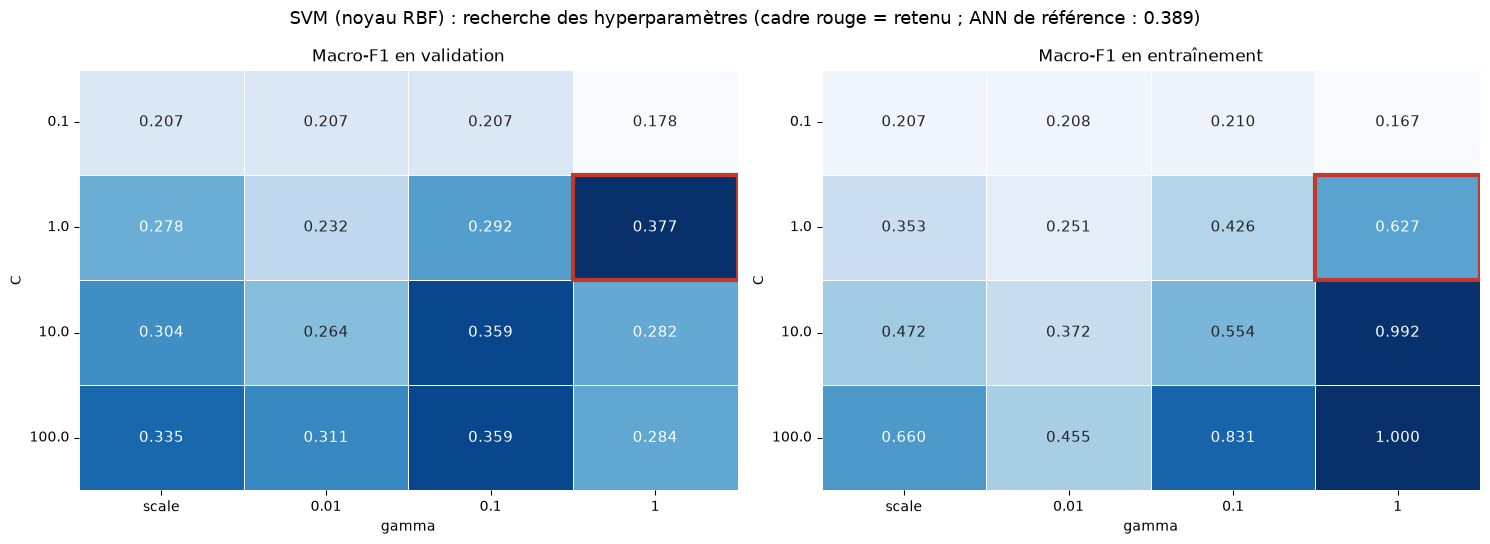

In [17]:
gammas = [str(g) for g in GRILLE_SVM["gamma"]]
carte_f1 = grille_svm.pivot(index="C", columns="gamma", values="val_f1_macro").loc[GRILLE_SVM["C"], gammas]
carte_train = grille_svm.pivot(index="C", columns="gamma", values="train_f1_macro").loc[GRILLE_SVM["C"], gammas]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, carte, titre in [(axes[0], carte_f1, "Macro-F1 en validation"), (axes[1], carte_train, "Macro-F1 en entraînement")]:
    sns.heatmap(carte, annot=True, fmt=".3f", cmap="Blues", cbar=False, linewidths=0.5, linecolor="white",
                annot_kws={"fontsize": 11}, ax=ax)
    i, j = GRILLE_SVM["C"].index(PARAMS_SVM["C"]), gammas.index(str(PARAMS_SVM["gamma"]))
    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, ec="#c0392b", lw=3))
    ax.set_xlabel("gamma")
    ax.set_ylabel("C")
    ax.tick_params(axis="y", rotation=0)
    ax.set_title(titre)
fig.suptitle(f"SVM (noyau RBF) : recherche des hyperparamètres (cadre rouge = retenu ; ANN de référence : "
             f"{ann['val_f1_macro'].mean():.3f})", fontsize=13)
plt.tight_layout()
plt.show()

La combinaison retenue (C = 1, gamma = 1) donne le meilleur Macro-F1 en validation (0,377). Son écart train − val (0,250) traduit un surapprentissage modéré, sans commune mesure avec celui des combinaisons à C et gamma élevés (jusqu’à 0,716, pour une validation de 0,284).

#### 3.4 Déséquilibre des classes

Mêmes méthodes que pour l'ANN et la forêt : sans correction, poids de classe, suréchantillonnage, SMOTE.

In [18]:
class SVMDeseq:
    """SVM + méthode de rééquilibrage, appliquée seulement aux données sur lesquelles on l'entraîne."""
    def __init__(self, methode, params, graine):
        self.methode, self.params, self.graine = methode, params, graine

    def fit(self, X, y):
        poids = None
        if self.methode == "Poids de classe":
            poids = "balanced"                                   # n / (K x n_k)
        elif self.methode == "Suréchantillonnage":
            X, y = RandomOverSampler(random_state=self.graine).fit_resample(X, y)
        elif self.methode == "SMOTE":
            effectifs = np.bincount(y)
            k = min(5, effectifs[effectifs > 0].min() - 1)         # k voisins : au plus la plus petite classe - 1
            echantillonneur = SMOTE(k_neighbors=k, random_state=self.graine) if k >= 1 else RandomOverSampler(random_state=self.graine)
            X, y = echantillonneur.fit_resample(X, y)
        self.svm_ = SVC(kernel="rbf", **self.params, class_weight=poids).fit(X, y)
        return self

    def predict(self, X):
        return self.svm_.predict(X)


resultats_deseq_svm, preds_deseq_svm, rappels_svm = [], {}, {}
for methode in METHODES_DESEQ:
    for graine in GRAINES:
        ligne, _, pred = evaluer(lambda g: SVMDeseq(methode, PARAMS_SVM, g), graine, methode)
        resultats_deseq_svm.append(ligne)
        preds_deseq_svm[(methode, graine)] = pred
        rappels_svm[(methode, graine)] = recall_score(y_val, pred, average=None, labels=range(N_CLASSES), zero_division=0)
resultats_deseq_svm = pd.DataFrame(resultats_deseq_svm)

# Incertitude due à la validation (bootstrap), utilisée quand l'écart-type entre graines est nul
ECARTS_SVM = {m: ecarts_bootstrap(preds_deseq_svm[(m, GRAINES[0])]) for m in METHODES_DESEQ}
for m in METHODES_DESEQ:
    f1s = resultats_deseq_svm.loc[resultats_deseq_svm["config"] == m, "val_f1_macro"]
    print(f"{m:20s} | Macro-F1 val = {f1s.mean():.3f} | écart-type graines = {f1s.std():.3f} | "
          f"écart-type bootstrap = {ECARTS_SVM[m]['val_f1_macro']:.3f}")

# Rappel par classe (moyenne sur 5 graines)
ordre_classes = np.argsort(np.bincount(y_train))[::-1]
rappel_classes_svm = pd.DataFrame({m: np.mean([rappels_svm[(m, g)] for g in GRAINES], axis=0)[ordre_classes]
                                   for m in METHODES_DESEQ}, index=[noms_courts[k] for k in ordre_classes]).T


Sans correction      | Macro-F1 val = 0.377 | écart-type graines = 0.000 | écart-type bootstrap = 0.058
Poids de classe      | Macro-F1 val = 0.364 | écart-type graines = 0.000 | écart-type bootstrap = 0.040
Suréchantillonnage   | Macro-F1 val = 0.300 | écart-type graines = 0.005 | écart-type bootstrap = 0.040
SMOTE                | Macro-F1 val = 0.335 | écart-type graines = 0.008 | écart-type bootstrap = 0.036


#### 3.5 Choix de la méthode de rééquilibrage


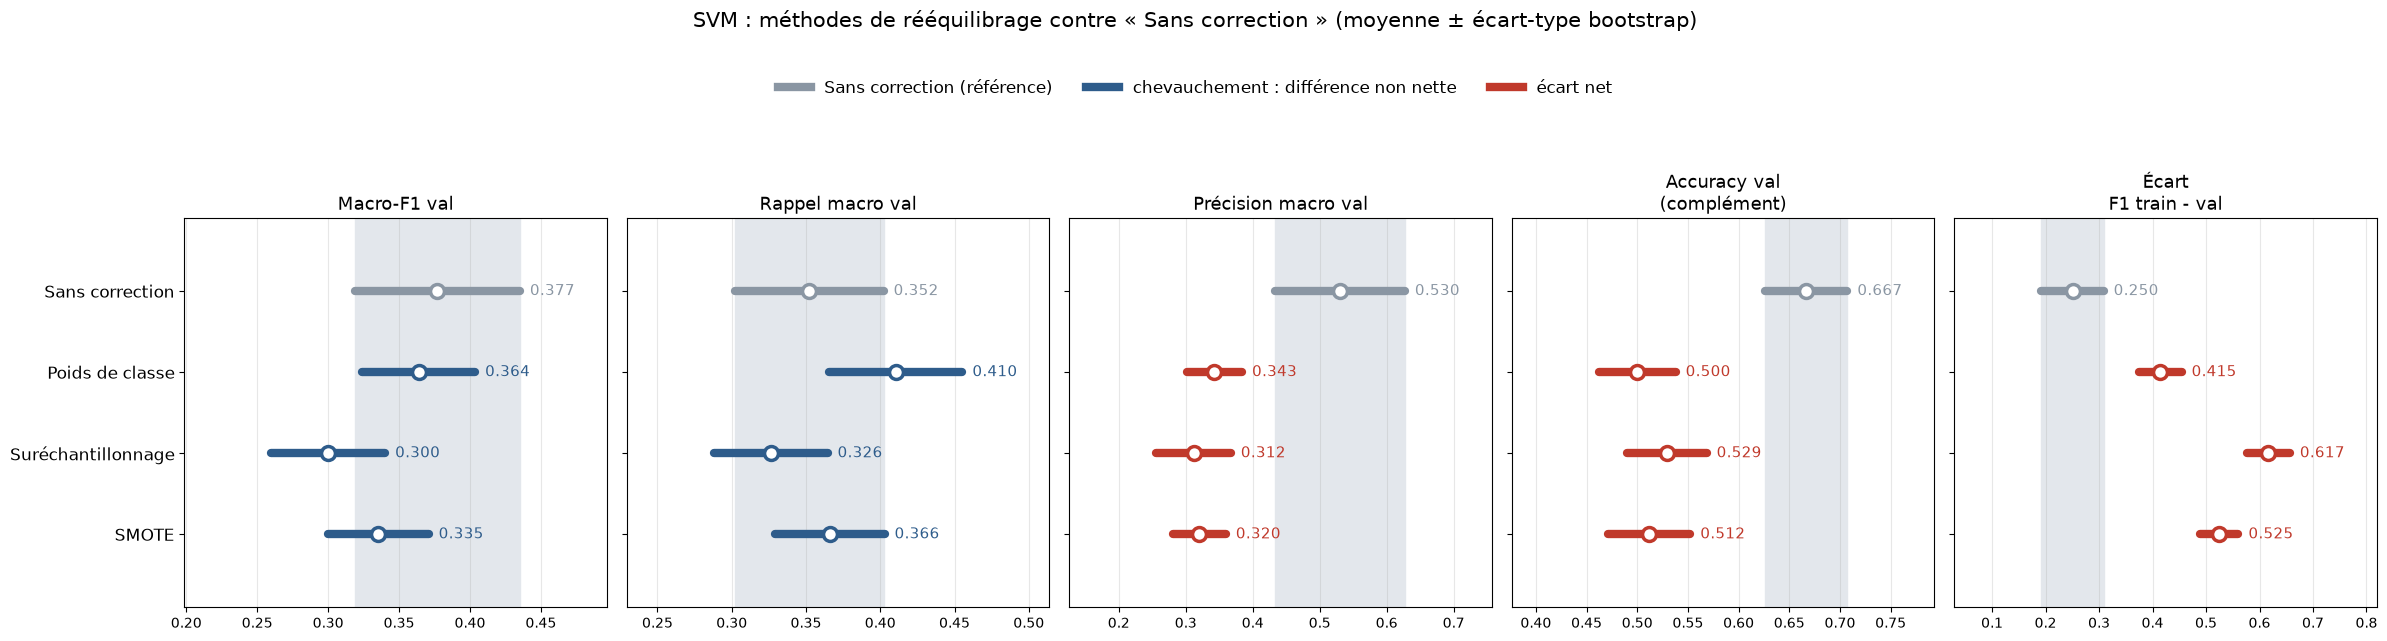

,Macro-F1,é.-t. graines,é.-t. bootstrap,bas,haut,comparaison
Sans correction,0.377,0.000,0.058,0.319,0.435,référence
Poids de classe,0.364,0.000,0.040,0.324,0.404,chevauchement
Suréchantillonnage,0.300,0.005,0.040,0.260,0.340,chevauchement
SMOTE,0.335,0.008,0.036,0.300,0.371,chevauchement


,Rubber,Savannas,Coffee,Forest,Human,Wetlands,Water,Bare
Sans correction,0.97,0.07,0.20,0.33,0.00,0.25,1.0,0.0
Poids de classe,0.53,0.33,0.67,0.42,0.33,0.00,1.0,0.0
Suréchantillonnage,0.70,0.16,0.56,0.08,0.11,0.00,1.0,0.0
SMOTE,0.62,0.17,0.56,0.33,0.24,0.00,1.0,0.0


Méthode retenue : Sans correction


In [19]:
# Bandes de chevauchement : incertitude = écart-type bootstrap (variation due au jeu de validation)
stats_d, ecarts_d = bandes_avec_ecarts(resultats_deseq_svm, METHODES_DESEQ, "Sans correction",
                                       "SVM : méthodes de rééquilibrage contre « Sans correction » (moyenne ± écart-type bootstrap)",
                                       "Sans correction (référence)", ecarts=ECARTS_SVM)

# Incertitude retenue : la plus grande des deux (graines ou bootstrap) ; pour le SVM, c'est le bootstrap
m_f1 = stats_d[("val_f1_macro", "mean")]
s_graines = resultats_deseq_svm.groupby("config")["val_f1_macro"].std()
s_f1 = {m: max(s_graines[m], ECARTS_SVM[m]["val_f1_macro"]) for m in METHODES_DESEQ}

# Tableau des intervalles et du chevauchement avec « Sans correction »
bas_ref, haut_ref = m_f1["Sans correction"] - s_f1["Sans correction"], m_f1["Sans correction"] + s_f1["Sans correction"]
intervalles = pd.DataFrame({
    "Macro-F1": [m_f1[m] for m in METHODES_DESEQ],
    "é.-t. graines": [s_graines[m] for m in METHODES_DESEQ],
    "é.-t. bootstrap": [ECARTS_SVM[m]["val_f1_macro"] for m in METHODES_DESEQ],
    "bas": [m_f1[m] - s_f1[m] for m in METHODES_DESEQ],
    "haut": [m_f1[m] + s_f1[m] for m in METHODES_DESEQ],
}, index=METHODES_DESEQ)
intervalles["comparaison"] = ["référence" if m == "Sans correction"
                              else ("gain net" if intervalles.loc[m, "bas"] > haut_ref
                                    else ("perte nette" if intervalles.loc[m, "haut"] < bas_ref else "chevauchement"))
                              for m in METHODES_DESEQ]
display(intervalles.round(3))

# Règle de l'ANN : on change seulement si le Macro-F1 progresse nettement
nettes = [m for m in METHODES_DESEQ[1:] if intervalles.loc[m, "comparaison"] == "gain net"]
METHODE_SVM = max(nettes, key=lambda m: m_f1[m]) if nettes else "Sans correction"
display(rappel_classes_svm.round(2))
print("Méthode retenue :", METHODE_SVM)

Comme pour l’ANN, aucune méthode de rééquilibrage n’améliore nettement le SVM : tous les intervalles (moyenne ± écart-type bootstrap) chevauchent celui de « Sans correction » (0,377 ± 0,058), qui reste la meilleure moyenne.Les poids de classe améliorent les classes minoritaires  mais font chuter Rubber (0,97 → 0,53). Le suréchantillonnage et SMOTE dégradent même Forest et Wetlands. L’eau reste parfaitement reconnue et Bare Soil jamais. Contrairement à la forêt, le SVM ne profite donc pas du rééquilibrage.

#### 3.6 SVM retenu

Comparé à l'ANN de référence et à la forêt retenue.

In [20]:
NOM_SVM = "SVM"
resultats_svm, f1_classes_svm, predictions_svm = [], {}, {}
for graine in GRAINES:
    ligne, f1c, pred = evaluer(lambda g: SVMDeseq(METHODE_SVM, PARAMS_SVM, g), graine, NOM_SVM)
    resultats_svm.append(ligne)
    f1_classes_svm[graine], predictions_svm[graine] = f1c, pred
resultats_svm = pd.DataFrame(resultats_svm)
ECARTS_SVM_FINAL = {NOM_SVM: ecarts_bootstrap(predictions_svm[GRAINES[0]])}

# Tableau récapitulatif : ANN, Random Forest et SVM (moyenne ± écart-type ; pour le SVM, écart-type bootstrap si nul)
comparaison_svm = pd.concat([ann, resultats_rf, resultats_svm], ignore_index=True)
cols = ["val_f1_macro", "val_recall_macro", "val_precision_macro", "val_mcc", "val_accuracy", "ecart_f1_train_val", "temps_s"]
recap_svm = comparaison_svm.groupby("config")[cols].agg(["mean", "std"]).loc[[REF_ANN, NOM_RF, NOM_SVM]]
for c in CRITERES_BOOT:
    recap_svm.loc[NOM_SVM, (c, "std")] = max(recap_svm.loc[NOM_SVM, (c, "std")], ECARTS_SVM_FINAL[NOM_SVM][c])
tableau_svm = pd.DataFrame(index=recap_svm.index)
for c in cols:
    dec = 1 if c == "temps_s" else 3
    tableau_svm[c] = [f"{m:.3f} ± {s:.3f}" if dec == 3 else f"{m:.1f} ± {s:.1f}"
                      for m, s in zip(recap_svm[(c, "mean")], recap_svm[(c, "std")])]
display(tableau_svm)

,val_f1_macro,val_recall_macro,val_precision_macro,val_mcc,val_accuracy,ecart_f1_train_val,temps_s
config,,,,,,,
ANN (référence),0.389 ± 0.041,0.377 ± 0.023,0.469 ± 0.097,0.330 ± 0.025,0.645 ± 0.011,0.054 ± 0.034,35.2 ± 3.4
Random Forest,0.450 ± 0.012,0.439 ± 0.014,0.487 ± 0.026,0.353 ± 0.013,0.623 ± 0.004,0.550 ± 0.012,3.4 ± 0.3
SVM,0.377 ± 0.058,0.352 ± 0.050,0.530 ± 0.097,0.355 ± 0.000,0.667 ± 0.041,0.250 ± 0.000,0.2 ± 0.1


#### 3.7 Comparaison avec l'ANN et la forêt

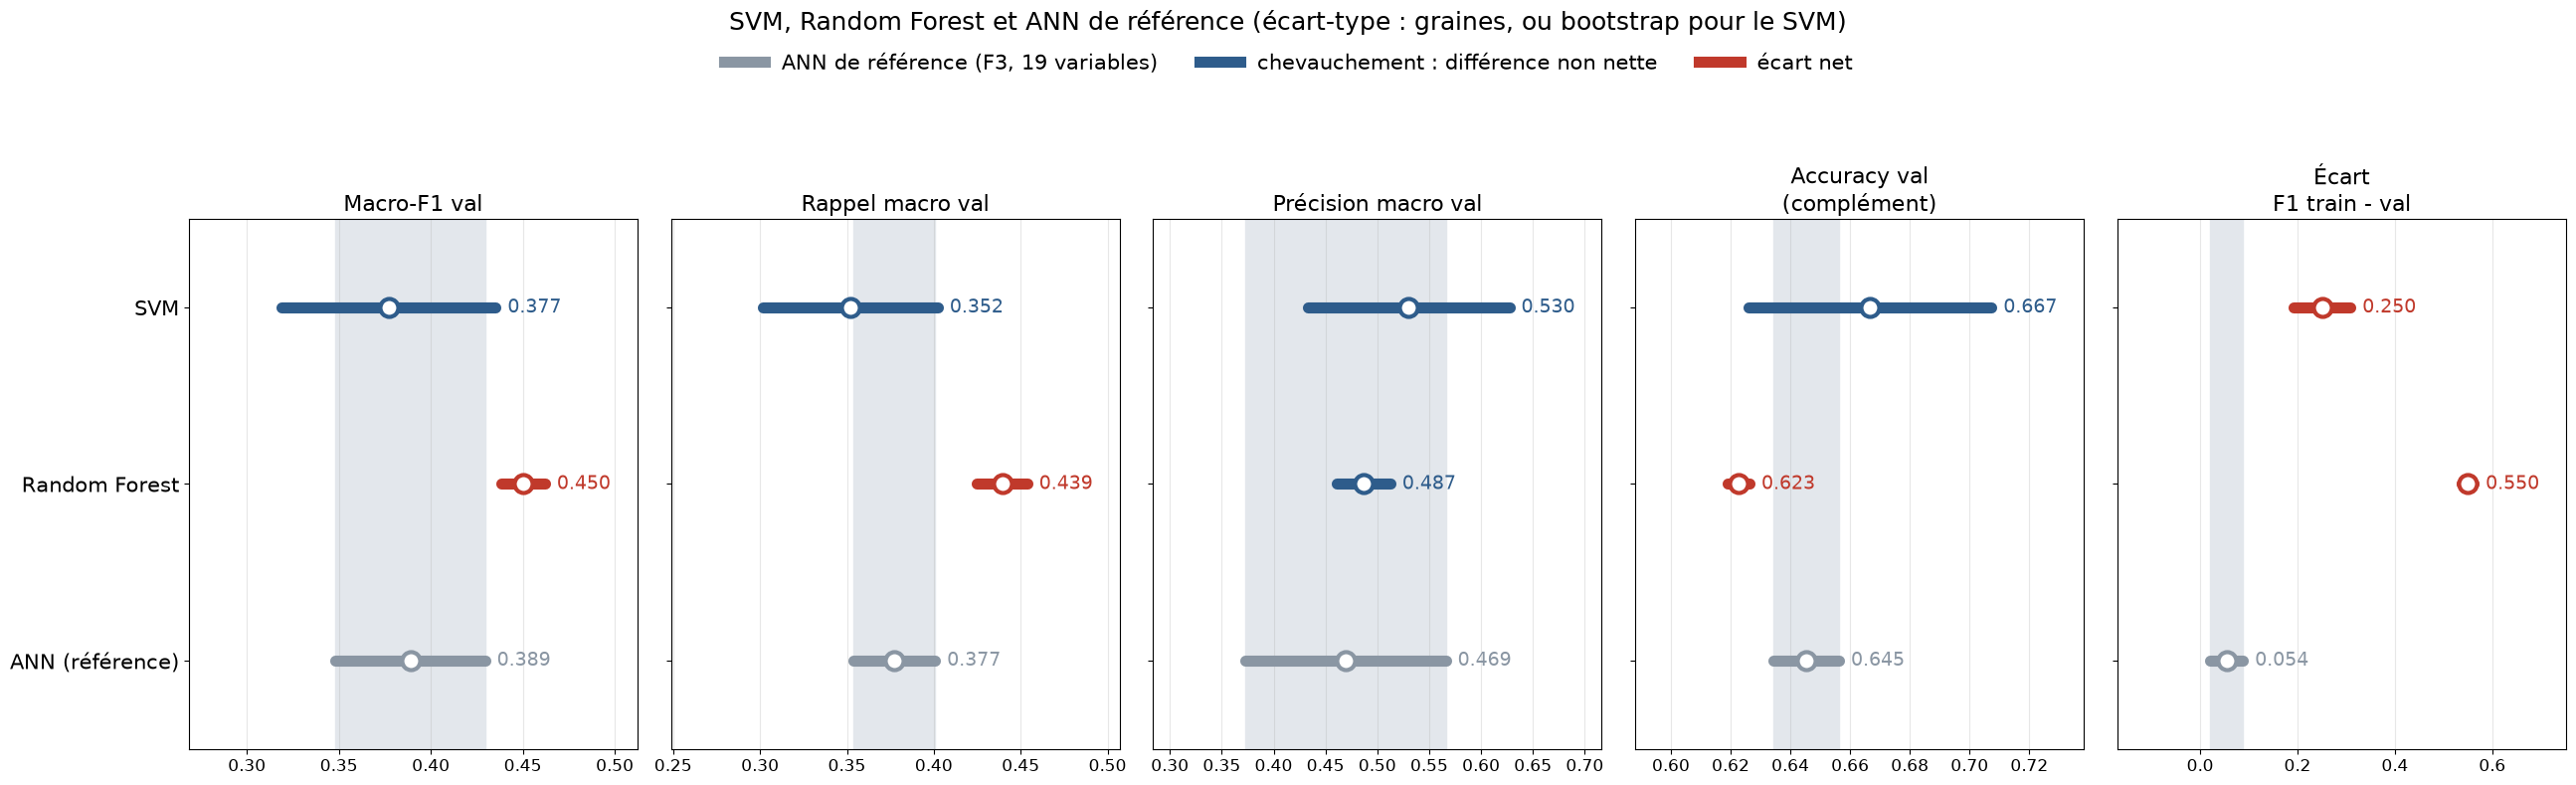

In [21]:
# Bandes de chevauchement : SVM et Random Forest contre l'ANN de référence

configs = [NOM_SVM, NOM_RF, REF_ANN]
criteres = [("val_f1_macro", "Macro-F1 val"), ("val_recall_macro", "Rappel macro val"),
            ("val_precision_macro", "Précision macro val"), ("val_accuracy", "Accuracy val\n(complément)"),
            ("ecart_f1_train_val", "Écart\nF1 train - val")]
stats = comparaison_svm.groupby("config")[[c for c, _ in criteres]].agg(["mean", "std"]).loc[configs]

fig, axes = plt.subplots(1, len(criteres), figsize=(26, 8), sharey=True)
y_pos = np.arange(len(configs))[::-1]
for ax, (col, titre) in zip(axes, criteres):
    m, s = stats[(col, "mean")], stats[(col, "std")].fillna(0).copy()
    cle = col if col != "ecart_f1_train_val" else "val_f1_macro"
    s[NOM_SVM] = max(s[NOM_SVM], ECARTS_SVM_FINAL[NOM_SVM][cle])          # incertitude bootstrap du SVM
    bas_ref, haut_ref = m[REF_ANN] - s[REF_ANN], m[REF_ANN] + s[REF_ANN]
    ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")
    for yi, cfg in zip(y_pos, configs):
        bas, haut = m[cfg] - s[cfg], m[cfg] + s[cfg]
        c = "#8a96a3" if cfg == REF_ANN else ("#2e5c8b" if bas <= haut_ref and haut >= bas_ref else "#c0392b")
        ax.plot([bas, haut], [yi, yi], color=c, lw=8, solid_capstyle="round")
        ax.plot(m[cfg], yi, "o", color="white", mec=c, mew=3, ms=13)
        ax.text(haut, yi, f"  {m[cfg]:.3f}", va="center", fontsize=14, color=c)
    ax.set_title(titre, fontsize=16)
    ax.margins(x=0.35, y=0.25)
    ax.grid(axis="x", alpha=0.3)
    ax.tick_params(axis="x", labelsize=12)
axes[0].set_yticks(y_pos, configs)
axes[0].tick_params(axis="y", labelsize=15)
legende = [Line2D([0], [0], color="#8a96a3", lw=8, label="ANN de référence (F3, 19 variables)"),
           Line2D([0], [0], color="#2e5c8b", lw=8, label="chevauchement : différence non nette"),
           Line2D([0], [0], color="#c0392b", lw=8, label="écart net")]
fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.95), frameon=False, fontsize=15)
fig.suptitle("SVM, Random Forest et ANN de référence (écart-type : graines, ou bootstrap pour le SVM)", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()

Le SVM ne se distingue nettement de l’ANN sur aucun critère : tous les intervalles se chevauchent. Il est en revanche nettement dépassé par la forêt aléatoire en Macro-F1 et en rappel macro  : il retrouve moins bien les classes, surtout les classes minoritaires. À l’inverse, il obtient en moyenne la meilleure précision (0,530) et la meilleure accuracy (0,667).il se trompe rarement quand il prédit une classe, mais passe à côté de beaucoup d’observations rares comme l'on l'a observé il y'a de cela peu.Enfin, son écart-type bootstrap élevé (0,058 sur le Macro-F1) montre que son score est fragile : il varierait sensiblement avec une autre validation de même taille.

#### 3.8 F1 par classe et matrice de confusion

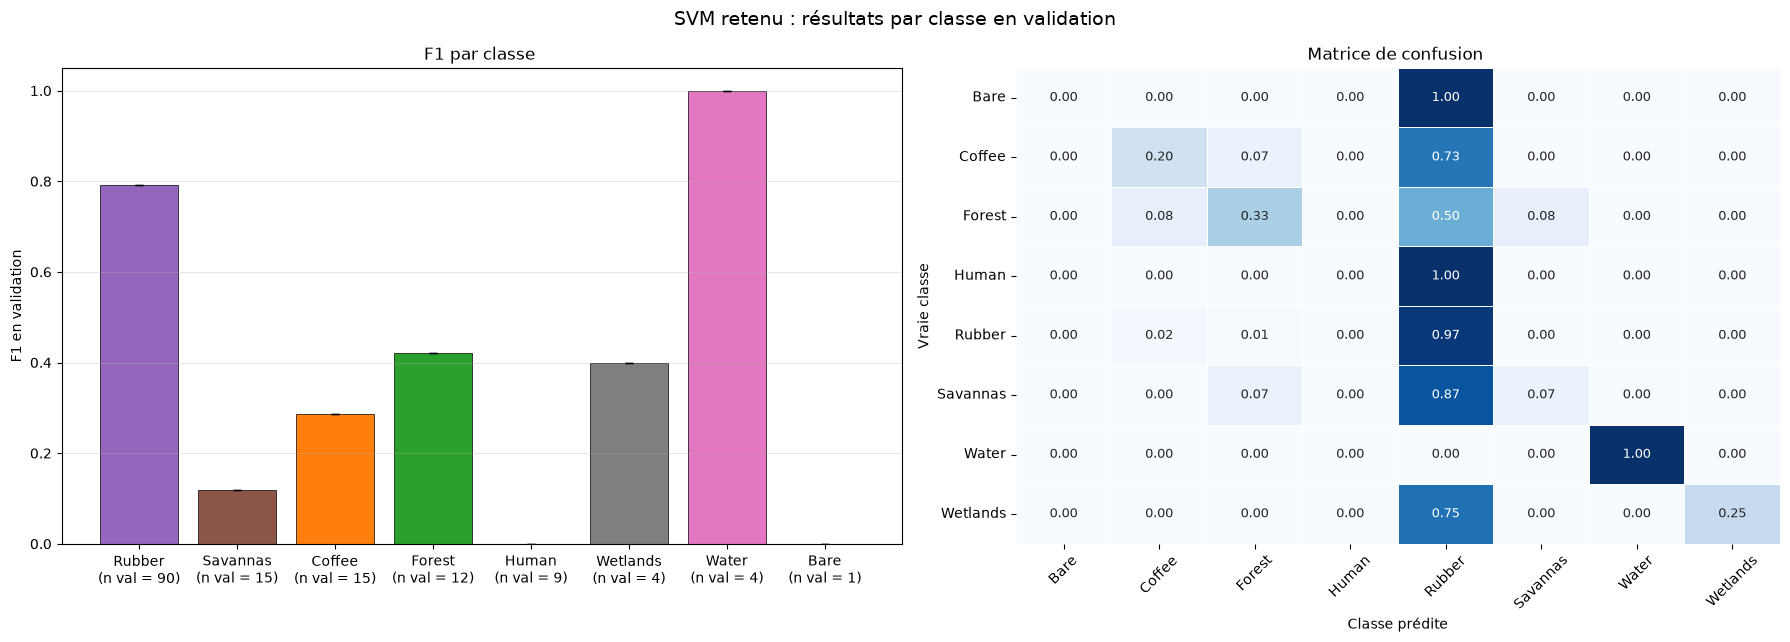

In [22]:
f1s = np.array([f1_classes_svm[g] for g in GRAINES])[:, ordre_classes]
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].bar(range(N_CLASSES), f1s.mean(axis=0), yerr=f1s.std(axis=0), capsize=3,
            color=[COULEURS_CLASSES[NOMS_CLASSES[k]] for k in ordre_classes], edgecolor="black", lw=0.5)
axes[0].set_xticks(range(N_CLASSES), [f"{noms_courts[k]}\n(n val = {np.sum(y_val == k)})" for k in ordre_classes])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("F1 en validation")
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_title("F1 par classe ")

cm = sum(confusion_matrix(y_val, predictions_svm[g], labels=range(N_CLASSES)) for g in GRAINES)
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=noms_courts, yticklabels=noms_courts, annot_kws={"fontsize": 9},
            linewidths=0.5, linecolor="white", ax=axes[1])
axes[1].set_xlabel("Classe prédite")
axes[1].set_ylabel("Vraie classe")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)
axes[1].set_title("Matrice de confusion ")
fig.suptitle("SVM retenu : résultats par classe en validation", fontsize=14)
plt.tight_layout()
plt.show()

La matrice de confusion confirme que le SVM classe la plupart des observations minoritaires comme Rubber : 87 % des Savannas, 75 % des Wetlands, 73 % des Coffee et la totalité des Human et Bare Soil. Ses F1 restent moyens pour Forest (0,42), Wetlands (0,40) et Coffee (0,29) parce qu’il prédit rarement ces classes, mais souvent à raison. Son rappel y est pourtant faible, au niveau de l’ANN et en dessous de la forêt. Seules Water (F1 = 1,00) et Rubber (0,79) sont bien reconnues. Le SVM est donc un modèle prudent : il se trompe peu quand il s’écarte de Rubber, mais il s’en écarte rarement.

#### 3.9 Validation aléatoire et spatiale

f1_macro   rappel_macro       accuracy
config          validation                                             
ANN (référence) aléatoire   0.361 ± 0.033  0.350 ± 0.026  0.641 ± 0.011
                spatiale    0.288 ± 0.070  0.291 ± 0.074  0.636 ± 0.103
Random Forest   aléatoire   0.416 ± 0.060  0.400 ± 0.055  0.604 ± 0.049
                spatiale    0.333 ± 0.104  0.329 ± 0.101  0.601 ± 0.051
SVM             aléatoire   0.284 ± 0.056  0.279 ± 0.053  0.631 ± 0.021
                spatiale    0.182 ± 0.086  0.193 ± 0.067  0.599 ± 0.115

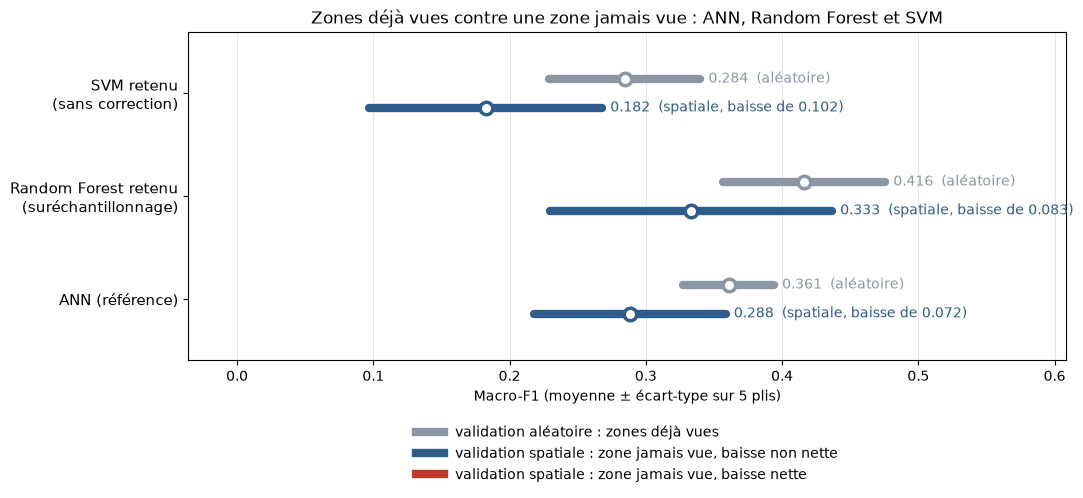

In [23]:
vc_svm = validation_croisee(lambda g: SVMDeseq(METHODE_SVM, PARAMS_SVM, g), NOM_SVM)
vc = pd.concat([ann_vc, vc_rf, vc_svm], ignore_index=True)
recap_vc = vc.groupby(["config", "validation"])[["f1_macro", "rappel_macro", "accuracy"]].agg(["mean", "std"])
tableau_vc = pd.DataFrame(index=recap_vc.index)
for c in ["f1_macro", "rappel_macro", "accuracy"]:
    tableau_vc[c] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(recap_vc[(c, "mean")], recap_vc[(c, "std")])]
display(tableau_vc)

modeles_vc = [NOM_SVM, NOM_RF, REF_ANN]                            # de haut en bas
etiquettes_vc = {NOM_SVM: f"SVM retenu\n({METHODE_SVM.lower()})", NOM_RF: f"Random Forest retenu\n({METHODE_RF.lower()})",
                 REF_ANN: "ANN (référence)"}
fig, ax = plt.subplots(figsize=(11, 5.2))
for yi, config in enumerate(modeles_vc[::-1]):
    m_a, s_a = recap_vc.loc[(config, "aléatoire"), ("f1_macro", "mean")], recap_vc.loc[(config, "aléatoire"), ("f1_macro", "std")]
    m_s, s_s = recap_vc.loc[(config, "spatiale"), ("f1_macro", "mean")], recap_vc.loc[(config, "spatiale"), ("f1_macro", "std")]
    c_s = "#c0392b" if (m_s + s_s < m_a - s_a) else "#2e5c8b"
    for m, s, c, dy, nom in [(m_a, s_a, "#8a96a3", 0.14, "aléatoire"), (m_s, s_s, c_s, -0.14, "spatiale")]:
        ax.plot([m - s, m + s], [yi + dy, yi + dy], color=c, lw=6, solid_capstyle="round")
        ax.plot(m, yi + dy, "o", color="white", mec=c, mew=2.5, ms=9)
        ax.text(m + s, yi + dy, f"  {m:.3f}  ({nom}, baisse de {m_a - m_s:.3f})" if nom == "spatiale" else f"  {m:.3f}  ({nom})",
                va="center", fontsize=10, color=c)
ax.set_yticks(range(len(modeles_vc)), [etiquettes_vc[c] for c in modeles_vc[::-1]], fontsize=11)
ax.set_xlabel("Macro-F1 (moyenne ± écart-type sur 5 plis)")
ax.margins(x=0.35, y=0.2)
ax.grid(axis="x", alpha=0.3)
ax.legend(handles=[Line2D([0], [0], color="#8a96a3", lw=6, label="validation aléatoire : zones déjà vues"),
                   Line2D([0], [0], color="#2e5c8b", lw=6, label="validation spatiale : zone jamais vue, baisse non nette"),
                   Line2D([0], [0], color="#c0392b", lw=6, label="validation spatiale : zone jamais vue, baisse nette")],
          loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=1, frameon=False, fontsize=10)
ax.set_title("Zones déjà vues contre une zone jamais vue : ANN, Random Forest et SVM")
plt.tight_layout()
plt.show()

Le SVM reste le moins performant des trois modèles, en zones connues (0,284) comme en zone nouvelle (0,182). Sa baisse en zone nouvelle (0,102) n’est pas nette, mais elle part du niveau le plus bas. Sans rééquilibrage, il abandonne les classes rares, qui deviennent presque absentes quand une zone est retirée.

#### 3.10 Synthese modele de SVM

Le SVM retenu (noyau RBF, C = 1, gamma = 1, sans correction du déséquilibre) obtient un Macro-F1 de 0,377 ± 0,058 en validation, au niveau de l’ANN (chevauchement) mais nettement derrière la forêt aléatoire (0,450). 
C’est un modèle prudent : il a la meilleure précision (0,530) et la meilleure accuracy (0,667), mais il classe la plupart des observations minoritaires comme Rubber et ne reconnaît jamais Human ni Bare Soil. Aucune méthode de rééquilibrage ne l’améliore. 

Limites : son score est fragile (pic isolé dans la grille, incertitude bootstrap élevée) et se généralise mal, puisqu’il chute à 0,284 en validation croisée aléatoire et à 0,182 en zone nouvelle, le niveau le plus bas des trois modèles. Sa configuration est figée dans config_svm.json pour la comparaison finale.

#### 3.11 Configuration finale

In [24]:
# Configuration finale du SVM, figée avant le test final
def moyenne_ecart(serie):
    return {"moyenne": round(float(serie.mean()), 3), "ecart_type": round(float(serie.std()), 3)}

# Résultats de la validation aléatoire et spatiale du SVM retenu (section 3.9)
vc_lu = vc_svm

CONFIG_SVM_FINAL = {
    "modele": "SVM",
    "noyau": "rbf",
    "hyperparametres": PARAMS_SVM,
    "choix_hyperparametres": "meilleur Macro-F1 en validation parmi la grille (SVM déterministe : une évaluation)",
    "grille": {k: [str(x) for x in v] for k, v in GRILLE_SVM.items()},
    "desequilibre": METHODE_SVM,
    "desequilibre_application": "entraînement seulement (validation et test intacts)",
    "desequilibre_regle": "changement seulement si gain net de Macro-F1 sur « Sans correction » (même règle que l'ANN)",
    "variables": VARIABLES,
    "n_variables": len(VARIABLES),
    "standardisation": "StandardScaler appris sur l'entraînement (indispensable pour le SVM)",
    "graines": GRAINES,
    "seed_partition": SEED_PARTITION,
    "validation_fixe": {                                  # 150 observations ; SVM déterministe
        "f1_macro": moyenne_ecart(resultats_svm["val_f1_macro"]),
        "rappel_macro": moyenne_ecart(resultats_svm["val_recall_macro"]),
        "precision_macro": moyenne_ecart(resultats_svm["val_precision_macro"]),
        "accuracy": moyenne_ecart(resultats_svm["val_accuracy"]),
        "f1_macro_ecart_type_bootstrap": round(float(ECARTS_SVM_FINAL[NOM_SVM]["val_f1_macro"]), 3),
    },
    "validation_croisee_dev": {                           # 5 plis, entraînement + validation
        schema: moyenne_ecart(vc_lu.loc[vc_lu["validation"] == schema, "f1_macro"])
        for schema in ["aléatoire", "spatiale"]},
}

print(json.dumps({k: v for k, v in CONFIG_SVM_FINAL.items() if k != "variables"}, ensure_ascii=False, indent=2, default=str))

{
  "modele": "SVM",
  "noyau": "rbf",
  "hyperparametres": {
    "C": 1,
    "gamma": 1
  },
  "choix_hyperparametres": "meilleur Macro-F1 en validation parmi la grille (SVM déterministe : une évaluation)",
  "grille": {
    "C": [
      "0.1",
      "1",
      "10",
      "100"
    ],
    "gamma": [
      "scale",
      "0.01",
      "0.1",
      "1"
    ]
  },
  "desequilibre": "Sans correction",
  "desequilibre_application": "entraînement seulement (validation et test intacts)",
  "desequilibre_regle": "changement seulement si gain net de Macro-F1 sur « Sans correction » (même règle que l'ANN)",
  "n_variables": 19,
  "standardisation": "StandardScaler appris sur l'entraînement (indispensable pour le SVM)",
  "graines": [
    0,
    1,
    2,
    3,
    4
  ],
  "seed_partition": 42,
  "validation_fixe": {
    "f1_macro": {
      "moyenne": 0.377,
      "ecart_type": 0.0
    },
    "rappel_macro": {
      "moyenne": 0.352,
      "ecart_type": 0.0
    },
    "precision_macro": {
   

### 4. XGBoost

#### 4.1 Préparation

Des arbres construits les uns après les autres, chacun corrigeant les erreurs des précédents. Comme la forêt, il dépend de la graine : 5 graines.

In [28]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight


# Réglages fixes : chaque arbre voit 80 % des observations et 80 % des variables (Chen & Guestrin, 2016)
FIXES_XGB = {"subsample": 0.8, "colsample_bytree": 0.8, "tree_method": "hist"}


class XGBDeseq:
    """XGBoost + méthode de rééquilibrage, appliquée seulement aux données sur lesquelles on l'entraîne."""
    def __init__(self, methode, params, graine):
        self.methode, self.params, self.graine = methode, params, graine

    def fit(self, X, y):
        poids = None
        if self.methode == "Poids de classe":
            poids = compute_sample_weight("balanced", y)              # n / (K x n_k) pour chaque observation
        elif self.methode == "Suréchantillonnage":
            X, y = RandomOverSampler(random_state=self.graine).fit_resample(X, y)
        elif self.methode == "SMOTE":
            effectifs = np.bincount(y)
            k = min(5, effectifs[effectifs > 0].min() - 1)
            echantillonneur = SMOTE(k_neighbors=k, random_state=self.graine) if k >= 1 else RandomOverSampler(random_state=self.graine)
            X, y = echantillonneur.fit_resample(X, y)
        self.classes_ = np.unique(y)                                  # XGBoost veut des classes 0, 1, 2... sans trou
        self.modele_ = XGBClassifier(**self.params, **FIXES_XGB, random_state=self.graine, n_jobs=-1)
        self.modele_.fit(X, np.searchsorted(self.classes_, y), sample_weight=poids)
        return self

    def predict(self, X):
        return self.classes_[self.modele_.predict(X)]

#### 4.2 Recherche des hyperparamètres

12 combinaisons × 5 graines, sans correction du déséquilibre. 

In [29]:
# learning_rate = part de correction apportée par chaque arbre ; max_depth = taille des arbres ; n_estimators = nombre d'arbres
GRILLE_XGB = {
    "n_estimators": [100, 300],
    "learning_rate": [0.05, 0.1, 0.3],
    "max_depth": [3, 6],
}
combinaisons_xgb = [dict(zip(GRILLE_XGB, v)) for v in product(*GRILLE_XGB.values())]
print(f"{len(combinaisons_xgb)} combinaisons x {len(GRAINES)} graines = {len(combinaisons_xgb) * len(GRAINES)} entraînements")

grille_xgb, PARAMS_GRILLE_XGB = [], {}
for params in combinaisons_xgb:
    nom = f"arbres={params['n_estimators']} | lr={params['learning_rate']} | depth={params['max_depth']}"
    PARAMS_GRILLE_XGB[nom] = params
    for graine in GRAINES:
        ligne, _, _ = evaluer(lambda g: XGBDeseq("Sans correction", params, g), graine, nom)
        grille_xgb.append(ligne)
grille_xgb = pd.DataFrame(grille_xgb)

recap_grille_xgb = (grille_xgb.groupby("config")
                    .agg(f1=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std"),
                         rappel=("val_recall_macro", "mean"), ecart=("ecart_f1_train_val", "mean"))
                    .sort_values("f1", ascending=False))
display(recap_grille_xgb.round(3))

MEILLEUR_XGB = recap_grille_xgb.index[0]
PARAMS_XGB = PARAMS_GRILLE_XGB[MEILLEUR_XGB]
print("Combinaison retenue :", MEILLEUR_XGB, "->", PARAMS_XGB)

12 combinaisons x 5 graines = 60 entraînements


,f1,f1_sd,rappel,ecart
config,,,,
arbres=100 | lr=0.1 | depth=6,0.342,0.012,0.346,0.656
arbres=300 | lr=0.05 | depth=3,0.338,0.016,0.342,0.631
arbres=300 | lr=0.3 | depth=6,0.337,0.014,0.345,0.663
arbres=100 | lr=0.3 | depth=6,0.334,0.012,0.341,0.666
arbres=100 | lr=0.05 | depth=3,0.334,0.022,0.334,0.289
arbres=100 | lr=0.1 | depth=3,0.333,0.013,0.337,0.554
arbres=100 | lr=0.05 | depth=6,0.331,0.014,0.334,0.582
arbres=300 | lr=0.05 | depth=6,0.331,0.007,0.337,0.669
arbres=300 | lr=0.1 | depth=6,0.330,0.003,0.337,0.670


Combinaison retenue : arbres=100 | lr=0.1 | depth=6 -> {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 6}


#### 4.3 Résultats de la recherche

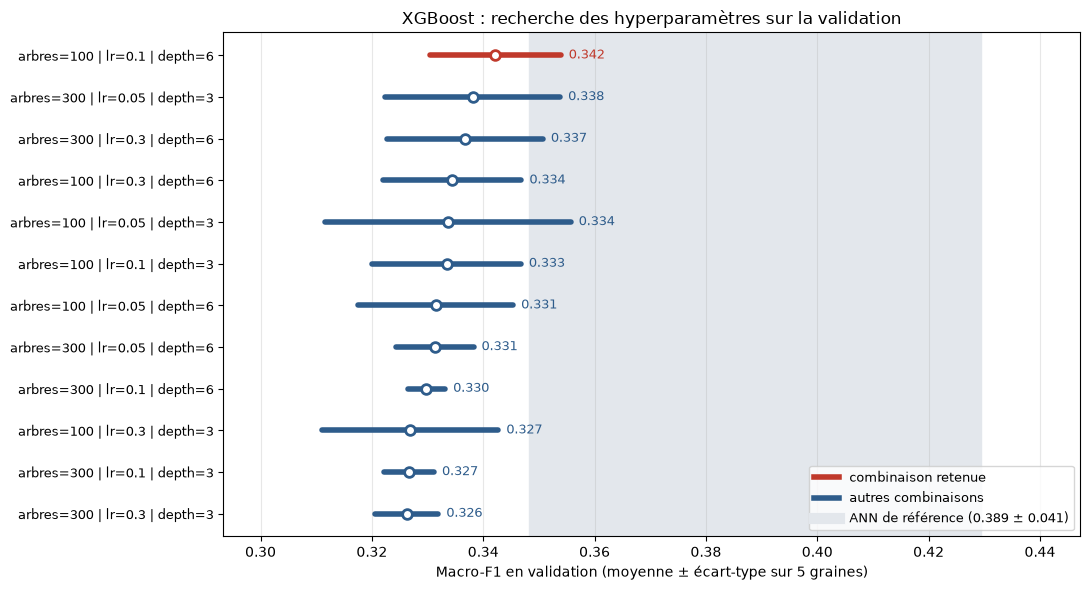

In [30]:
fig, ax = plt.subplots(figsize=(11, 6))
ordre = recap_grille_xgb.index[::-1]
for yi, cfg in enumerate(ordre):
    m, s = recap_grille_xgb.loc[cfg, "f1"], recap_grille_xgb.loc[cfg, "f1_sd"]
    c = "#c0392b" if cfg == MEILLEUR_XGB else "#2e5c8b"
    ax.plot([m - s, m + s], [yi, yi], color=c, lw=4, solid_capstyle="round")
    ax.plot(m, yi, "o", color="white", mec=c, mew=2, ms=7)
    ax.text(m + s, yi, f"  {m:.3f}", va="center", fontsize=9, color=c)
m_ann, s_ann = ann["val_f1_macro"].mean(), ann["val_f1_macro"].std()
ax.axvspan(m_ann - s_ann, m_ann + s_ann, color="#e3e7ec", zorder=0)
ax.set_yticks(range(len(ordre)), ordre, fontsize=9)
ax.set_xlabel("Macro-F1 en validation (moyenne ± écart-type sur 5 graines)")
ax.margins(x=0.15)
ax.grid(axis="x", alpha=0.3)
ax.legend(handles=[Line2D([0], [0], color="#c0392b", lw=4, label="combinaison retenue"),
                   Line2D([0], [0], color="#2e5c8b", lw=4, label="autres combinaisons"),
                   Line2D([0], [0], color="#e3e7ec", lw=8, label=f"ANN de référence ({m_ann:.3f} ± {s_ann:.3f})")],
          loc="lower right", fontsize=9)
ax.set_title("XGBoost : recherche des hyperparamètres sur la validation")
plt.tight_layout()
plt.show()

La meilleure combinaison retenue est un XGBoost de 100 arbres, avec un taux d'apprentissage de 0,1 et une profondeur maximale de 6 (Macro-F1 de 0,342 en validation).

Les écarts entre combinaisons restent faibles (de 0,326 à 0,342) et leurs intervalles se chevauchent. Sans correction du déséquilibre, XGBoost reste en dessous de l'ANN en moyenne, mais les intervalles se chevauchent.

#### 4.4 Déséquilibre des classes

Mêmes méthodes que pour l'ANN, la forêt et le SVM : sans correction, poids de classe, suréchantillonnage, SMOTE.

In [31]:
resultats_deseq_xgb, rappels_deseq_xgb = [], {}
for methode in METHODES_DESEQ:
    for graine in GRAINES:
        ligne, _, pred = evaluer(lambda g: XGBDeseq(methode, PARAMS_XGB, g), graine, methode)
        resultats_deseq_xgb.append(ligne)
        rappels_deseq_xgb[(methode, graine)] = recall_score(y_val, pred, average=None, labels=range(N_CLASSES), zero_division=0)
    f1s = [r["val_f1_macro"] for r in resultats_deseq_xgb if r["config"] == methode]
    print(f"{methode:20s} | Macro-F1 val = {np.mean(f1s):.3f} ± {np.std(f1s, ddof=1):.3f}")
resultats_deseq_xgb = pd.DataFrame(resultats_deseq_xgb)

# Rappel par classe (moyenne sur 5 graines)
rappel_classes_xgb = pd.DataFrame({m: np.mean([rappels_deseq_xgb[(m, g)] for g in GRAINES], axis=0)[ordre_classes]
                                   for m in METHODES_DESEQ}, index=[noms_courts[k] for k in ordre_classes]).T

Sans correction      | Macro-F1 val = 0.342 ± 0.012
Poids de classe      | Macro-F1 val = 0.376 ± 0.020
Suréchantillonnage   | Macro-F1 val = 0.375 ± 0.006
SMOTE                | Macro-F1 val = 0.388 ± 0.013


La correction du déséquilibre a un effet net : les trois méthodes dépassent nettement « Sans correction » (0,342 ± 0,012).

SMOTE obtient le meilleur Macro-F1 moyen (0,388 ± 0,013) et est retenu selon la règle. Le risque de surapprentissage lié aux observations synthétiques sera vérifié par la validation spatiale.

#### 4.5 Choix de la méthode de rééquilibrage


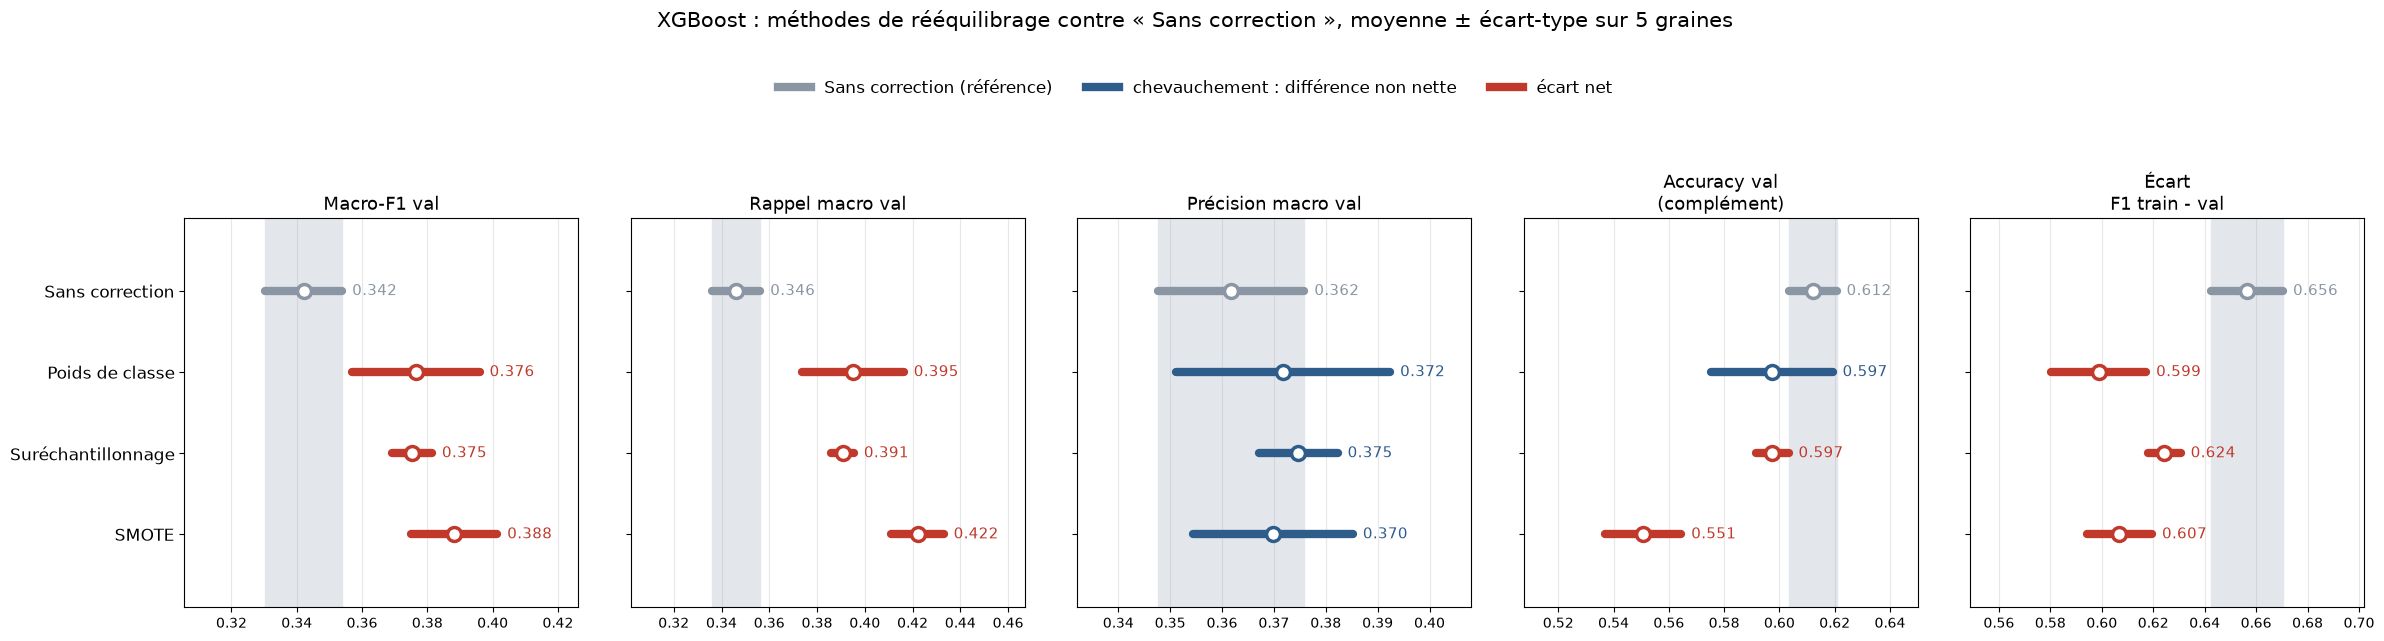

Méthodes avec un gain net de Macro-F1 : ['Poids de classe', 'Suréchantillonnage', 'SMOTE']
Méthode retenue : SMOTE

Rappel par classe (moyenne sur 5 graines) :


,Rubber,Savannas,Coffee,Forest,Human,Wetlands,Water,Bare
Sans correction,0.85,0.07,0.39,0.13,0.33,0.0,1.0,0.0
Poids de classe,0.76,0.13,0.55,0.23,0.49,0.0,1.0,0.0
Suréchantillonnage,0.76,0.13,0.53,0.18,0.51,0.0,1.0,0.0
SMOTE,0.64,0.17,0.53,0.48,0.44,0.1,1.0,0.0


In [32]:
bandes_chevauchement(resultats_deseq_xgb, METHODES_DESEQ, "Sans correction",
                     "XGBoost : méthodes de rééquilibrage contre « Sans correction », moyenne ± écart-type sur 5 graines",
                     "Sans correction (référence)")

# Règle de l'ANN : on change seulement si le Macro-F1 progresse nettement
st = resultats_deseq_xgb.groupby("config")["val_f1_macro"].agg(["mean", "std"])
haut_ref = st.loc["Sans correction", "mean"] + st.loc["Sans correction", "std"]
nettes = [m for m in METHODES_DESEQ[1:] if st.loc[m, "mean"] - st.loc[m, "std"] > haut_ref]
METHODE_XGB = max(nettes, key=lambda m: st.loc[m, "mean"]) if nettes else "Sans correction"
print("Méthodes avec un gain net de Macro-F1 :", nettes if nettes else "aucune")
print("Méthode retenue :", METHODE_XGB)
print("\nRappel par classe (moyenne sur 5 graines) :")
display(rappel_classes_xgb.round(2))

Avec SMOTE, les classes minoritaires sont mieux reconnues, surtout Forest, Coffee  et Savannas. Wetlands commence à être reconnue (0,10), mais très faiblement. Bare Soil n'est toujours jamais reconnue, et Water reste parfaitement reconnue.

Ce gain se fait au détriment de Rubber, dont le rappel passe de 0,85 à 0,64 : le modèle prédit moins souvent la classe majoritaire.

#### 4.6 XGBoost retenu

Comparé à l'ANN de référence.

In [33]:
NOM_XGB = "XGBoost"
resultats_xgb, f1_classes_xgb, predictions_xgb = [], {}, {}
for graine in GRAINES:
    ligne, f1c, pred = evaluer(lambda g: XGBDeseq(METHODE_XGB, PARAMS_XGB, g), graine, NOM_XGB)
    resultats_xgb.append(ligne)
    f1_classes_xgb[graine], predictions_xgb[graine] = f1c, pred
resultats_xgb = pd.DataFrame(resultats_xgb)

# Tableau récapitulatif : ANN de référence contre XGBoost (moyenne ± écart-type sur 5 graines)
comparaison_xgb = pd.concat([ann, resultats_xgb], ignore_index=True)
cols = ["val_f1_macro", "val_recall_macro", "val_precision_macro", "val_mcc", "val_accuracy", "ecart_f1_train_val", "temps_s"]
recap_xgb = comparaison_xgb.groupby("config")[cols].agg(["mean", "std"]).loc[[REF_ANN, NOM_XGB]]
tableau_xgb = pd.DataFrame(index=recap_xgb.index)
for c in cols:
    dec = 1 if c == "temps_s" else 3
    tableau_xgb[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap_xgb[(c, "mean")], recap_xgb[(c, "std")])]

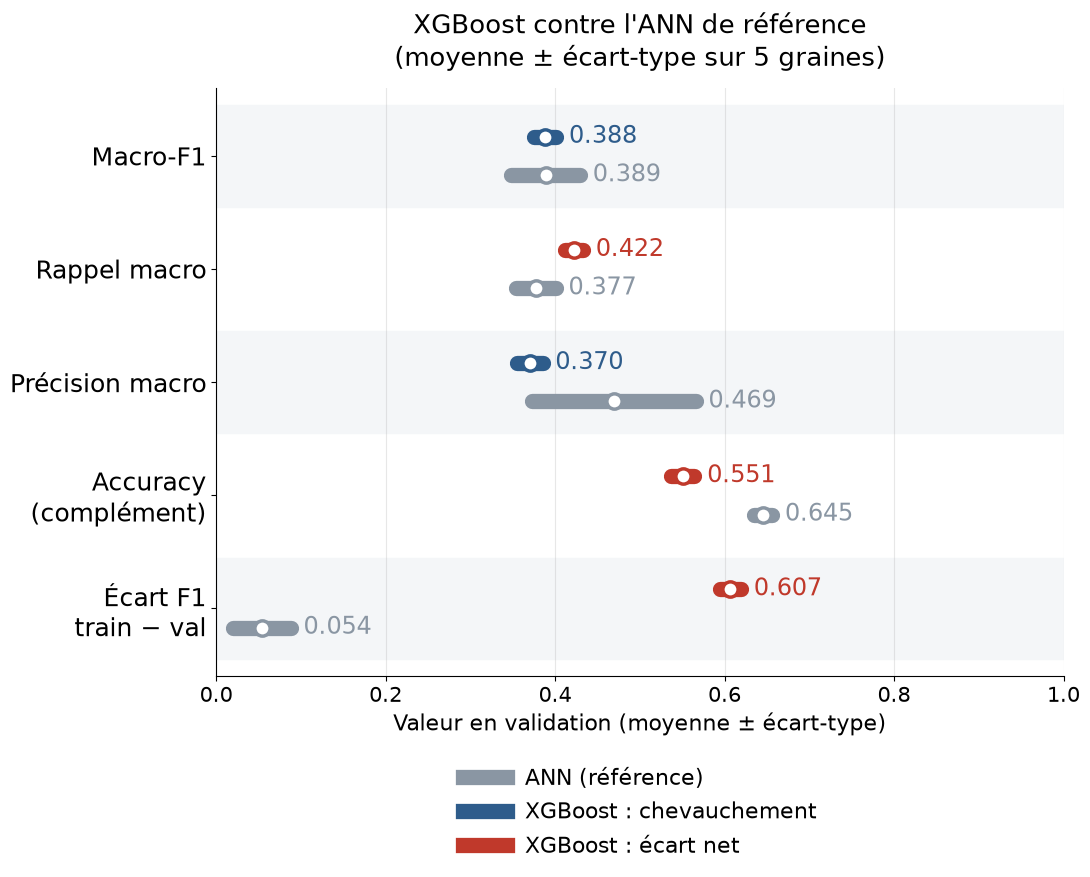

In [45]:
def comparaison_criteres(df, modele, reference, titre, etiquettes, ecarts=None):
    """Un seul graphique : une ligne par critère, le modèle et la référence l'un sous l'autre (moyenne ± écart-type)."""
    criteres = [("val_f1_macro", "Macro-F1"), ("val_recall_macro", "Rappel macro"), ("val_precision_macro", "Précision macro"),
                ("val_accuracy", "Accuracy\n(complément)"), ("ecart_f1_train_val", "Écart F1\ntrain − val")]
    stats = df.groupby("config")[[c for c, _ in criteres]].agg(["mean", "std"])
    fig, ax = plt.subplots(figsize=(11, 9))
    for i, (col, nom) in enumerate(criteres):
        y0 = len(criteres) - 1 - i
        m_r, s_r = stats.loc[reference, (col, "mean")], stats.loc[reference, (col, "std")]
        m_m, s_m = stats.loc[modele, (col, "mean")], stats.loc[modele, (col, "std")]
        if ecarts is not None and modele in ecarts:                     # SVM : écart-type bootstrap
            s_m = max(s_m, ecarts[modele].get(col if col != "ecart_f1_train_val" else "val_f1_macro", 0))
        net = m_m + s_m < m_r - s_r or m_m - s_m > m_r + s_r
        c_m = "#c0392b" if net else "#2e5c8b"
        ax.axhspan(y0 - 0.45, y0 + 0.45, color="#f4f6f8" if i % 2 == 0 else "white", zorder=0)
        for m, s, c, dy in [(m_m, s_m, c_m, 0.17), (m_r, s_r, "#8a96a3", -0.17)]:
            ax.plot([m - s, m + s], [y0 + dy, y0 + dy], color=c, lw=11, solid_capstyle="round")
            ax.plot(m, y0 + dy, "o", color="white", mec=c, mew=2.5, ms=11)
            ax.text(m + s + 0.015, y0 + dy, f"{m:.3f}", va="center", fontsize=17, color=c)
    ax.set_yticks(range(len(criteres)), [nom for _, nom in criteres[::-1]], fontsize=18)
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.6, len(criteres) - 0.4)
    ax.tick_params(axis="x", labelsize=15)
    ax.set_xlabel("Valeur en validation (moyenne ± écart-type)", fontsize=16)
    ax.grid(axis="x", alpha=0.3)
    for cote in ["top", "right"]:
        ax.spines[cote].set_visible(False)
    ax.legend(handles=[Line2D([0], [0], color="#8a96a3", lw=11, label=etiquettes[reference]),
                       Line2D([0], [0], color="#2e5c8b", lw=11, label=f"{etiquettes[modele]} : chevauchement"),
                       Line2D([0], [0], color="#c0392b", lw=11, label=f"{etiquettes[modele]} : écart net")],
              loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1, frameon=False, fontsize=16)
    ax.set_title(titre, fontsize=19, pad=16)
    plt.tight_layout()
    plt.show()


comparaison_criteres(comparaison_xgb, NOM_XGB, REF_ANN,
                     "XGBoost contre l'ANN de référence\n(moyenne ± écart-type sur 5 graines)",
                     {NOM_XGB: "XGBoost", REF_ANN: "ANN (référence)"})


XGBoost fait jeu égal avec l'ANN en Macro-F1 (0,388 contre 0,389). Il retrouve nettement mieux les classes (rappel de 0,422 contre 0,377), mais au prix d'une accuracy nettement plus basse (0,551 contre 0,645), car il prédit moins souvent Rubber. Son écart train − val très élevé (0,607) montre qu'il colle fortement à l'entraînement ; la validation spatiale dira si cela nuit à sa généralisation.

#### 4.7 F1 par classe et matrice de confusion

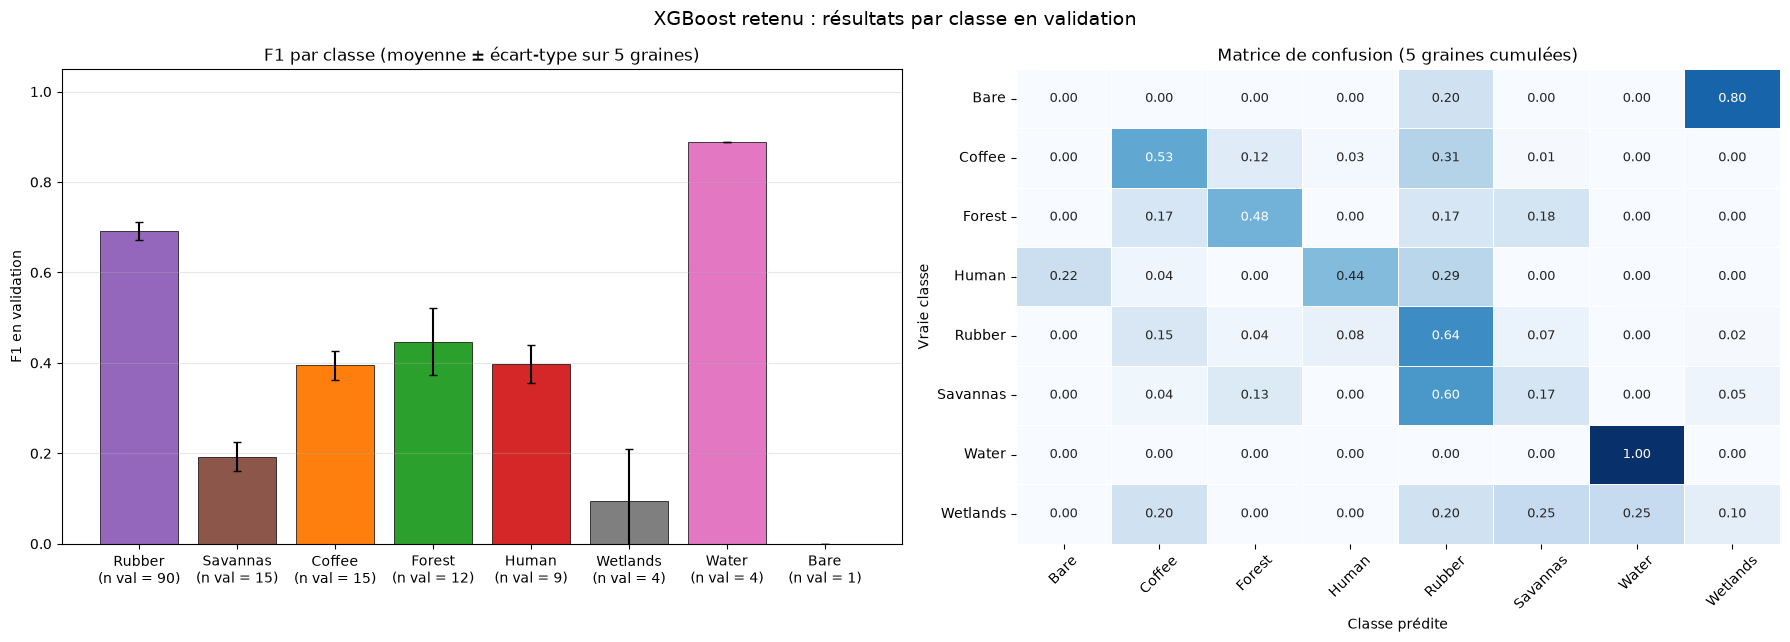

In [35]:
f1s = np.array([f1_classes_xgb[g] for g in GRAINES])[:, ordre_classes]
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].bar(range(N_CLASSES), f1s.mean(axis=0), yerr=f1s.std(axis=0), capsize=3,
            color=[COULEURS_CLASSES[NOMS_CLASSES[k]] for k in ordre_classes], edgecolor="black", lw=0.5)
axes[0].set_xticks(range(N_CLASSES), [f"{noms_courts[k]}\n(n val = {np.sum(y_val == k)})" for k in ordre_classes])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("F1 en validation")
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_title("F1 par classe (moyenne ± écart-type sur 5 graines)")

cm = sum(confusion_matrix(y_val, predictions_xgb[g], labels=range(N_CLASSES)) for g in GRAINES)
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=noms_courts, yticklabels=noms_courts, annot_kws={"fontsize": 9},
            linewidths=0.5, linecolor="white", ax=axes[1])
axes[1].set_xlabel("Classe prédite")
axes[1].set_ylabel("Vraie classe")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)
axes[1].set_title("Matrice de confusion (5 graines cumulées)")
fig.suptitle("XGBoost retenu : résultats par classe en validation", fontsize=14)
plt.tight_layout()
plt.show()

 Les erreurs vont surtout vers Rubber, la classe majoritaire : 60 % des Savannas, 31 % des Coffee et 29 % des Human y sont classées. Forest se disperse entre les autres végétations (Savannas 18 %, Coffee 17 %, Rubber 17 %).

Avec SMOTE apparaissent aussi des erreurs entre classes proches. Human est confondue avec Bare Soil (22 %), deux surfaces peu végétalisées. Wetlands est confondue avec Water (25 %), deux milieux humides, ce qui fait baisser le F1 de Water (0,89) malgré un rappel parfait. Enfin, Rubber perd surtout des observations au profit de Coffee (15 %), deux cultures arborées.

Ces confusions ne viennent pas seulement du déséquilibre : certaines classes se ressemblent elles-mêmes spectralement (cultures arborées, végétations, surfaces peu végétalisées, milieux humides), comme le montrait déjà l'analyse exploratoire.

#### 4.8 Validation aléatoire et spatiale

In [36]:
vc_xgb = validation_croisee(lambda g: XGBDeseq(METHODE_XGB, PARAMS_XGB, g), NOM_XGB)
recap_vc_xgb = (pd.concat([ann_vc, vc_xgb]).groupby(["config", "validation"])[["f1_macro", "rappel_macro", "accuracy"]]
                .agg(["mean", "std"]))
tableau_vc_xgb = pd.DataFrame(index=recap_vc_xgb.index)
for c in ["f1_macro", "rappel_macro", "accuracy"]:
    tableau_vc_xgb[c] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(recap_vc_xgb[(c, "mean")], recap_vc_xgb[(c, "std")])]
display(tableau_vc_xgb)
for config in [NOM_XGB, REF_ANN]:
    baisse = recap_vc_xgb.loc[(config, "aléatoire"), ("f1_macro", "mean")] - recap_vc_xgb.loc[(config, "spatiale"), ("f1_macro", "mean")]
    print(f"{config:16s} | baisse du Macro-F1 en zone jamais vue : {baisse:.3f}")

f1_macro   rappel_macro       accuracy
config          validation                                             
ANN (référence) aléatoire   0.361 ± 0.033  0.350 ± 0.026  0.641 ± 0.011
                spatiale    0.288 ± 0.070  0.291 ± 0.074  0.636 ± 0.103
XGBoost         aléatoire   0.419 ± 0.053  0.446 ± 0.048  0.536 ± 0.055
                spatiale    0.317 ± 0.060  0.371 ± 0.081  0.531 ± 0.042

XGBoost          | baisse du Macro-F1 en zone jamais vue : 0.102
ANN (référence)  | baisse du Macro-F1 en zone jamais vue : 0.072


XGBoost reste en tête en moyenne, en validation aléatoire (0,419 contre 0,361) comme en validation spatiale (0,317 contre 0,288), mais les intervalles se chevauchent avec ceux de l'ANN. En zone jamais vue, il perd davantage que l'ANN (baisse de 0,102 contre 0,073), sans que cette baisse soit nette. Son fort écart train − val ne l'empêche donc pas de généraliser, mais l'ANN reste le plus stable d'une zone à l'autre.

#### 4.9 Configuration finale

In [37]:
def moyenne_ecart(serie):
    return {"moyenne": round(float(serie.mean()), 3), "ecart_type": round(float(serie.std()), 3)}

CONFIG_XGB_FINAL = {
    "modele": "XGBoost",
    "hyperparametres": PARAMS_XGB,
    "reglages_fixes": FIXES_XGB,
    "choix_hyperparametres": "meilleur Macro-F1 moyen en validation (5 graines) parmi la grille",
    "grille": {k: [str(x) for x in v] for k, v in GRILLE_XGB.items()},
    "desequilibre": METHODE_XGB,
    "desequilibre_application": "entraînement seulement (validation et test intacts)",
    "desequilibre_regle": "changement seulement si gain net de Macro-F1 sur « Sans correction » (même règle que l'ANN)",
    "variables": VARIABLES,
    "n_variables": len(VARIABLES),
    "standardisation": "StandardScaler appris sur l'entraînement (sans effet sur les arbres)",
    "graines": GRAINES,
    "seed_partition": SEED_PARTITION,
    "validation_fixe": {                                  # 5 graines, validation de 150 observations
        "f1_macro": moyenne_ecart(resultats_xgb["val_f1_macro"]),
        "rappel_macro": moyenne_ecart(resultats_xgb["val_recall_macro"]),
        "precision_macro": moyenne_ecart(resultats_xgb["val_precision_macro"]),
        "accuracy": moyenne_ecart(resultats_xgb["val_accuracy"]),
    },
    "validation_croisee_dev": {                           # 5 plis, entraînement + validation
        schema: moyenne_ecart(vc_xgb.loc[vc_xgb["validation"] == schema, "f1_macro"])
        for schema in ["aléatoire", "spatiale"]},
}

print(json.dumps({k: v for k, v in CONFIG_XGB_FINAL.items() if k != "variables"}, ensure_ascii=False, indent=2, default=str))

{
  "modele": "XGBoost",
  "hyperparametres": {
    "n_estimators": 100,
    "learning_rate": 0.1,
    "max_depth": 6
  },
  "reglages_fixes": {
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist"
  },
  "choix_hyperparametres": "meilleur Macro-F1 moyen en validation (5 graines) parmi la grille",
  "grille": {
    "n_estimators": [
      "100",
      "300"
    ],
    "learning_rate": [
      "0.05",
      "0.1",
      "0.3"
    ],
    "max_depth": [
      "3",
      "6"
    ]
  },
  "desequilibre": "SMOTE",
  "desequilibre_application": "entraînement seulement (validation et test intacts)",
  "desequilibre_regle": "changement seulement si gain net de Macro-F1 sur « Sans correction » (même règle que l'ANN)",
  "n_variables": 19,
  "standardisation": "StandardScaler appris sur l'entraînement (sans effet sur les arbres)",
  "graines": [
    0,
    1,
    2,
    3,
    4
  ],
  "seed_partition": 42,
  "validation_fixe": {
    "f1_macro": {
      "moyenne": 0.388,
 

### 5. Comparaison finale : ANN, Random Forest, SVM et XGBoost

Les quatre modèles retenus, chacun avec sa configuration finale, sur les mêmes données et les mêmes critères. Le test n'est toujours pas utilisé.

In [38]:

MODELES = [REF_ANN, NOM_RF, NOM_SVM, NOM_XGB]
ETIQUETTES = {REF_ANN: "ANN", NOM_RF: "Random Forest", NOM_SVM: "SVM", NOM_XGB: "XGBoost"}
COULEURS_MODELES = {REF_ANN: "#8a96a3", NOM_RF: "#2e7d32", NOM_SVM: "#c86a1e", NOM_XGB: "#2e5c8b"}

resultats_tous = pd.concat([ann, resultats_rf, resultats_svm, resultats_xgb], ignore_index=True)
vc_tous = pd.concat([ann_vc, vc_rf, vc_svm, vc_xgb], ignore_index=True)

# Validation fixe : moyenne ± écart-type sur 5 graines (SVM déterministe : écart-type bootstrap)
cols = ["val_f1_macro", "val_recall_macro", "val_precision_macro", "val_f1_pondere", "val_mcc", "val_accuracy",
        "ecart_f1_train_val", "temps_s"]
recap_tous = resultats_tous.groupby("config")[cols].agg(["mean", "std"]).loc[MODELES]
for c in CRITERES_BOOT:
    recap_tous.loc[NOM_SVM, (c, "std")] = max(recap_tous.loc[NOM_SVM, (c, "std")], ECARTS_SVM_FINAL[NOM_SVM][c])

# Validation croisée : moyenne ± écart-type sur 5 plis
recap_vc_tous = vc_tous.groupby(["config", "validation"])["f1_macro"].agg(["mean", "std"])

tableau_final = pd.DataFrame(index=[ETIQUETTES[m] for m in MODELES])
for c in cols:
    dec = 1 if c == "temps_s" else 3
    tableau_final[c] = [f"{recap_tous.loc[m, (c, 'mean')]:.{dec}f} ± {recap_tous.loc[m, (c, 'std')]:.{dec}f}" for m in MODELES]
for schema in ["aléatoire", "spatiale"]:
    tableau_final[f"vc_{schema}_f1_macro"] = [f"{recap_vc_tous.loc[(m, schema), 'mean']:.3f} ± {recap_vc_tous.loc[(m, schema), 'std']:.3f}"
                                              for m in MODELES]
tableau_final["baisse_spatiale"] = [f"{recap_vc_tous.loc[(m, 'aléatoire'), 'mean'] - recap_vc_tous.loc[(m, 'spatiale'), 'mean']:.3f}"
                                    for m in MODELES]
display(tableau_final)

,val_f1_macro,val_recall_macro,val_precision_macro,val_f1_pondere,val_mcc,val_accuracy,ecart_f1_train_val,temps_s,vc_aléatoire_f1_macro,vc_spatiale_f1_macro,baisse_spatiale
ANN,0.389 ± 0.041,0.377 ± 0.023,0.469 ± 0.097,0.586 ± 0.016,0.330 ± 0.025,0.645 ± 0.011,0.054 ± 0.034,35.2 ± 3.4,0.361 ± 0.033,0.288 ± 0.070,0.072
Random Forest,0.450 ± 0.012,0.439 ± 0.014,0.487 ± 0.026,0.607 ± 0.006,0.353 ± 0.013,0.623 ± 0.004,0.550 ± 0.012,3.4 ± 0.3,0.416 ± 0.060,0.333 ± 0.104,0.083
SVM,0.377 ± 0.058,0.352 ± 0.050,0.530 ± 0.097,0.586 ± 0.000,0.355 ± 0.000,0.667 ± 0.041,0.250 ± 0.000,0.2 ± 0.1,0.284 ± 0.056,0.182 ± 0.086,0.102
XGBoost,0.388 ± 0.013,0.422 ± 0.011,0.370 ± 0.015,0.560 ± 0.013,0.317 ± 0.011,0.551 ± 0.014,0.607 ± 0.013,2.2 ± 0.4,0.419 ± 0.053,0.317 ± 0.060,0.102


#### 5.1 ANN, Random Forest, SVM et XGBoost en validation

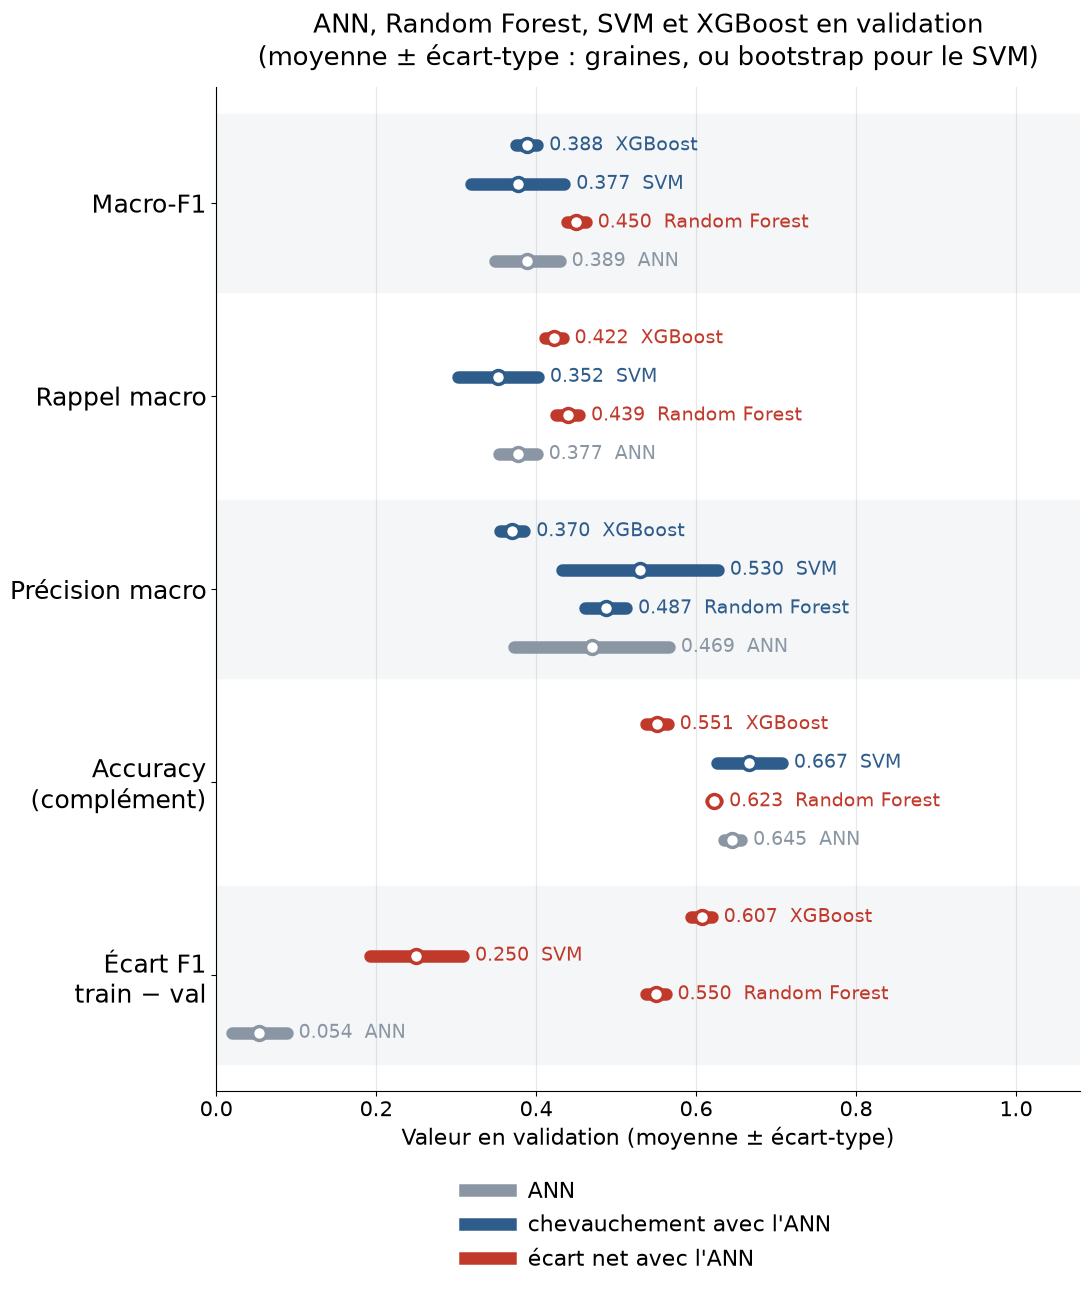

In [46]:
def comparaison_modeles(df, modeles, reference, titre, etiquettes, ecarts=None):
    """Un seul graphique : une ligne par critère, les modèles les uns sous les autres, comparés à la référence."""
    criteres = [("val_f1_macro", "Macro-F1"), ("val_recall_macro", "Rappel macro"), ("val_precision_macro", "Précision macro"),
                ("val_accuracy", "Accuracy\n(complément)"), ("ecart_f1_train_val", "Écart F1\ntrain − val")]
    stats = df.groupby("config")[[c for c, _ in criteres]].agg(["mean", "std"])
    decalages = np.linspace(0.3, -0.3, len(modeles))                     # position de chaque modèle dans la ligne
    fig, ax = plt.subplots(figsize=(11, 13))
    for i, (col, nom) in enumerate(criteres):
        y0 = len(criteres) - 1 - i
        ax.axhspan(y0 - 0.46, y0 + 0.46, color="#f4f6f8" if i % 2 == 0 else "white", zorder=0)
        m_r, s_r = stats.loc[reference, (col, "mean")], stats.loc[reference, (col, "std")]
        for modele, dy in zip(modeles, decalages):
            m, s = stats.loc[modele, (col, "mean")], stats.loc[modele, (col, "std")]
            if ecarts is not None and modele in ecarts:                  # SVM : écart-type bootstrap
                s = max(s, ecarts[modele].get(col if col != "ecart_f1_train_val" else "val_f1_macro", 0))
            if modele == reference:
                c = "#8a96a3"
            else:
                c = "#c0392b" if (m + s < m_r - s_r or m - s > m_r + s_r) else "#2e5c8b"
            ax.plot([m - s, m + s], [y0 + dy, y0 + dy], color=c, lw=9, solid_capstyle="round")
            ax.plot(m, y0 + dy, "o", color="white", mec=c, mew=2.5, ms=10)
            ax.text(m + s + 0.015, y0 + dy, f"{m:.3f}  {etiquettes[modele]}", va="center", fontsize=14, color=c)
    ax.set_yticks(range(len(criteres)), [nom for _, nom in criteres[::-1]], fontsize=18)
    ax.set_xlim(0, 1.08)
    ax.set_ylim(-0.6, len(criteres) - 0.4)
    ax.tick_params(axis="x", labelsize=15)
    ax.set_xlabel("Valeur en validation (moyenne ± écart-type)", fontsize=16)
    ax.grid(axis="x", alpha=0.3)
    for cote in ["top", "right"]:
        ax.spines[cote].set_visible(False)
    ax.legend(handles=[Line2D([0], [0], color="#8a96a3", lw=9, label=etiquettes[reference]),
                       Line2D([0], [0], color="#2e5c8b", lw=9, label="chevauchement avec l'ANN"),
                       Line2D([0], [0], color="#c0392b", lw=9, label="écart net avec l'ANN")],
              loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=1, frameon=False, fontsize=16)
    ax.set_title(titre, fontsize=19, pad=16)
    plt.tight_layout()
    plt.show()


comparaison_modeles(resultats_tous, [NOM_XGB, NOM_SVM, NOM_RF, REF_ANN], REF_ANN,
                    "ANN, Random Forest, SVM et XGBoost en validation\n(moyenne ± écart-type : graines, ou bootstrap pour le SVM)",
                    {REF_ANN: "ANN", NOM_RF: "Random Forest", NOM_SVM: "SVM", NOM_XGB: "XGBoost"},
                    ecarts=ECARTS_SVM_FINAL)

Random Forest arrive en tête : c'est le seul modèle dont le Macro-F1 dépasse nettement celui de l'ANN (0,450 contre 0,389), et son avance est aussi nette sur XGBoost (0,388) et sur le SVM (0,377). Avec XGBoost, il retrouve nettement mieux les classes que l'ANN (rappel de 0,439 et 0,422 contre 0,377). Les précisions se chevauchent toutes. L'accuracy de la forêt et de XGBoost est en revanche nettement plus basse que celle de l'ANN, car ils prédisent moins souvent Rubber.

#### 5.2 F1 par classe des modèles classiques

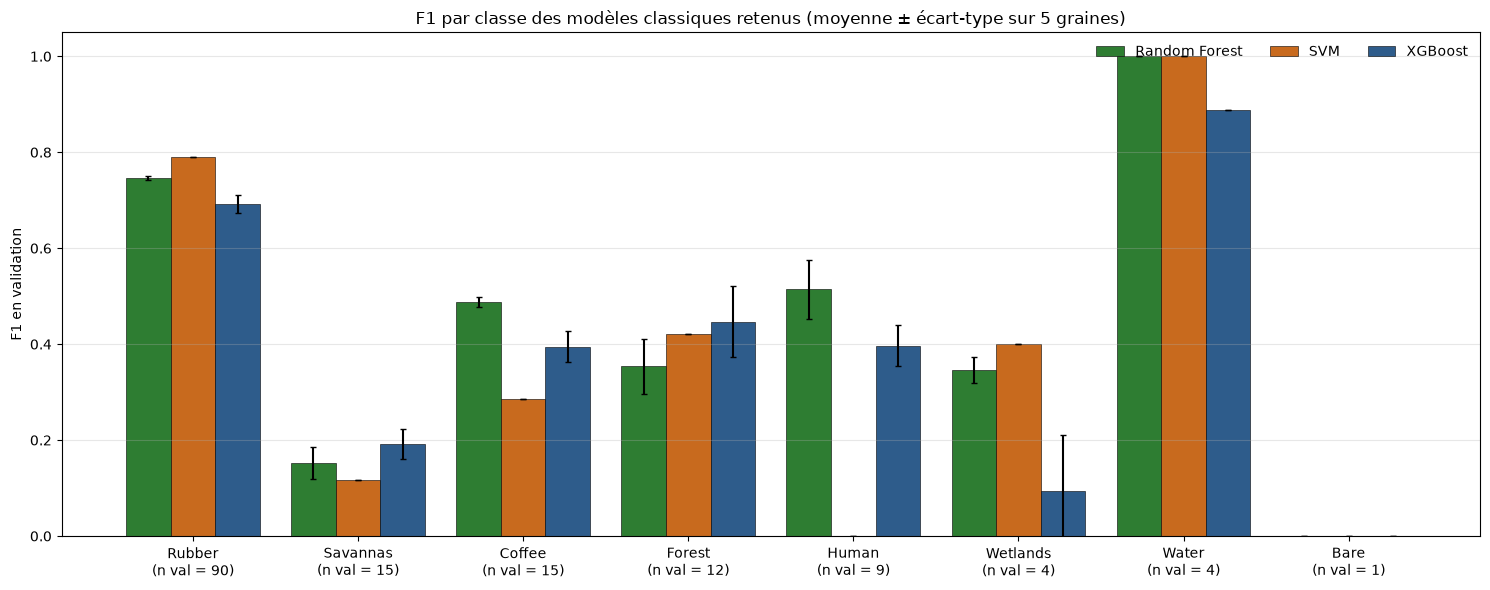

,Rubber,Savannas,Coffee,Forest,Human,Wetlands,Water,Bare
Random Forest,0.75,0.15,0.49,0.35,0.51,0.35,1.00,0.0
SVM,0.79,0.12,0.29,0.42,0.00,0.40,1.00,0.0
XGBoost,0.69,0.19,0.39,0.45,0.40,0.09,0.89,0.0


In [40]:
f1_par_modele = {NOM_RF: np.array([f1_classes_rf[g] for g in GRAINES])[:, ordre_classes],
                 NOM_SVM: np.array([f1_classes_svm[g] for g in GRAINES])[:, ordre_classes],
                 NOM_XGB: np.array([f1_classes_xgb[g] for g in GRAINES])[:, ordre_classes]}
fig, ax = plt.subplots(figsize=(15, 6))
largeur = 0.27
for j, (nom, f1s) in enumerate(f1_par_modele.items()):
    ax.bar(np.arange(N_CLASSES) + (j - 1) * largeur, f1s.mean(axis=0), largeur, yerr=f1s.std(axis=0), capsize=2,
           color=COULEURS_MODELES[nom], edgecolor="black", lw=0.4, label=ETIQUETTES[nom])
ax.set_xticks(range(N_CLASSES), [f"{noms_courts[k]}\n(n val = {np.sum(y_val == k)})" for k in ordre_classes])
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1 en validation")
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, ncol=3, loc="upper right")
ax.set_title("F1 par classe des modèles classiques retenus (moyenne ± écart-type sur 5 graines)")
plt.tight_layout()
plt.show()

f1_classes_table = pd.DataFrame({ETIQUETTES[nom]: f1s.mean(axis=0) for nom, f1s in f1_par_modele.items()},
                                index=[noms_courts[k] for k in ordre_classes]).T
display(f1_classes_table.round(2))

Le SVM est exclu par l'analyse par classe : il ne reconnaît jamais Human (F1 = 0,00) et reste faible sur Coffee (0,29). Son bon score repose surtout sur Rubber (0,79), Forest (0,42) et Wetlands (0,40). XGBoost est le meilleur sur Forest (0,45) et Savannas (0,19), mais il reconnaît mal Wetlands (0,09) et perd en précision sur Water (0,89). Random Forest est le plus équilibré : il est le meilleur sur Coffee (0,49) et Human (0,51), sans s'effondrer sur aucune classe sauf Bare Soil, qu'aucun modèle ne reconnaît.

#### 5.3 Validation aléatoire et spatiale des quatre modèles

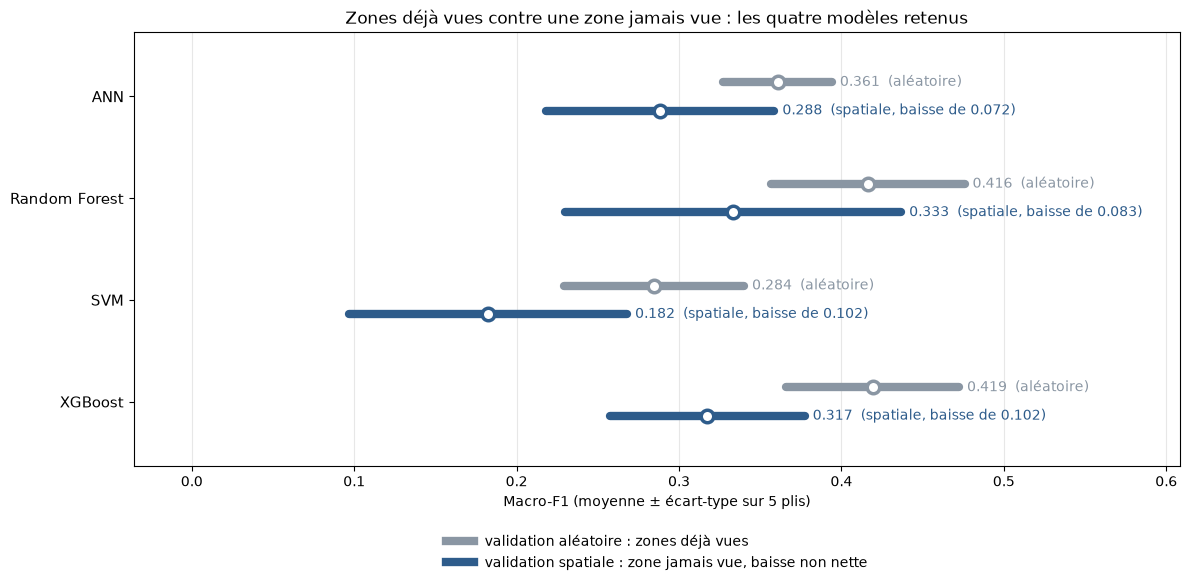

In [41]:
# Une ligne par modèle : validation aléatoire (gris) puis spatiale (bleu, ou rouge si la baisse est nette)
fig, ax = plt.subplots(figsize=(12, 6))
baisse_nette = False
for yi, config in enumerate(MODELES[::-1]):
    m_a, s_a = recap_vc_tous.loc[(config, "aléatoire"), "mean"], recap_vc_tous.loc[(config, "aléatoire"), "std"]
    m_s, s_s = recap_vc_tous.loc[(config, "spatiale"), "mean"], recap_vc_tous.loc[(config, "spatiale"), "std"]
    nette = m_s + s_s < m_a - s_a
    baisse_nette = baisse_nette or nette
    c_s = "#c0392b" if nette else "#2e5c8b"
    for m, s, c, dy, nom in [(m_a, s_a, "#8a96a3", 0.14, "aléatoire"), (m_s, s_s, c_s, -0.14, "spatiale")]:
        ax.plot([m - s, m + s], [yi + dy, yi + dy], color=c, lw=6, solid_capstyle="round")
        ax.plot(m, yi + dy, "o", color="white", mec=c, mew=2.5, ms=9)
        ax.text(m + s, yi + dy, f"  {m:.3f}  ({nom}, baisse de {m_a - m_s:.3f})" if nom == "spatiale" else f"  {m:.3f}  ({nom})",
                va="center", fontsize=10, color=c)
ax.set_yticks(range(len(MODELES)), [ETIQUETTES[m] for m in MODELES[::-1]], fontsize=11)
ax.set_xlabel("Macro-F1 (moyenne ± écart-type sur 5 plis)")
ax.margins(x=0.35, y=0.15)
ax.grid(axis="x", alpha=0.3)

# Légende : seulement les couleurs présentes sur le graphique
legende = [Line2D([0], [0], color="#8a96a3", lw=6, label="validation aléatoire : zones déjà vues"),
           Line2D([0], [0], color="#2e5c8b", lw=6, label="validation spatiale : zone jamais vue, baisse non nette")]
if baisse_nette:
    legende.append(Line2D([0], [0], color="#c0392b", lw=6, label="validation spatiale : zone jamais vue, baisse nette"))
ax.legend(handles=legende, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=1, frameon=False, fontsize=10)
ax.set_title("Zones déjà vues contre une zone jamais vue : les quatre modèles retenus")
plt.tight_layout()
plt.show()

En zone jamais vue, tous les modèles perdent en Macro-F1, sans qu'aucune baisse soit nette. L'ANN reste le plus stable (baisse de 0,072), devant la forêt (0,083) ; 

le SVM et XGBoost perdent le plus (0,102). 

Random Forest garde le meilleur score en validation spatiale (0,333), devant XGBoost (0,317), l'ANN (0,288) et le SVM (0,182), mais les intervalles se chevauchent tous : en zone nouvelle, la variabilité d'un bloc à l'autre est trop forte pour départager les modèles. Comme pour les modèles précédents, cette baisse vient en partie des classes concentrées dans une seule zone, comme l'eau dans le bloc 2.

#### 5.4 Positionnement des modèles

Pour chaque validation, chaque modèle est comparé au meilleur sur le Macro-F1 

In [42]:
def comparer(m, s, m_ref, s_ref):
    if m == m_ref and s == s_ref:
        return "référence"
    return "écart net" if (m + s < m_ref - s_ref or m - s > m_ref + s_ref) else "chevauchement"

scores = {"validation fixe": {mod: (recap_tous.loc[mod, ("val_f1_macro", "mean")], recap_tous.loc[mod, ("val_f1_macro", "std")])
                              for mod in MODELES}}
for schema in ["aléatoire", "spatiale"]:
    scores[f"validation {schema}"] = {mod: (recap_vc_tous.loc[(mod, schema), "mean"], recap_vc_tous.loc[(mod, schema), "std"])
                                      for mod in MODELES}

positionnement = pd.DataFrame(index=[ETIQUETTES[m] for m in MODELES])
for validation, sc in scores.items():
    meilleur = max(sc, key=lambda mod: sc[mod][0])
    positionnement[validation] = [f"{sc[mod][0]:.3f} ({comparer(*sc[mod], *sc[meilleur])})" for mod in MODELES]
    print(f"{validation:22s} | meilleur Macro-F1 : {ETIQUETTES[meilleur]}")
display(positionnement)

validation fixe        | meilleur Macro-F1 : Random Forest
validation aléatoire   | meilleur Macro-F1 : XGBoost
validation spatiale    | meilleur Macro-F1 : Random Forest


,validation fixe,validation aléatoire,validation spatiale
ANN,0.389 (écart net),0.361 (chevauchement),0.288 (chevauchement)
Random Forest,0.450 (référence),0.416 (chevauchement),0.333 (référence)
SVM,0.377 (écart net),0.284 (écart net),0.182 (chevauchement)
XGBoost,0.388 (écart net),0.419 (référence),0.317 (chevauchement)


Random Forest est le seul modèle qui n'est jamais nettement battu. En validation fixe, il dépasse nettement les trois autres (0,450). En validation aléatoire, XGBoost le devance de peu (0,419 contre 0,416), mais leurs intervalles se chevauchent. En validation spatiale, il obtient le meilleur score (0,333), sans écart net avec les autres modèles. Le SVM est le plus faible, nettement battu en validation fixe et en validation aléatoire. L'ANN est nettement battu en validation fixe et à égalité ailleurs, avec l'avantage d'être le plus stable d'une zone à l'autre.

Random Forest est donc retenu comme modèle final. Sur ce jeu de données, l'ANN ne fait pas mieux que les méthodes classiques, ce qui rejoint la littérature selon laquelle les modèles à base d'arbres restent très compétitifs sur les données tabulaires.

### 6. Modèle final : Random Forest

SHAP sur la validation, puis évaluation unique sur le test et sauvegarde du modèle avec son pipeline.

#### 6.1 Pipeline du modèle final

Standardisation, suréchantillonnage (entraînement seulement) et forêt réunis ensemble, avec les réglages de la configuration finale du Random Forest (2.10).

In [50]:

assert METHODE_RF == "Suréchantillonnage"


def pipeline_rf(graine):
    """Le suréchantillonnage n'agit qu'à l'entraînement, jamais à la prédiction."""
    return Pipeline([("standardisation", StandardScaler()),
                     ("reequilibrage", RandomOverSampler(random_state=graine)),
                     ("foret", RandomForestClassifier(**PARAMS_RF, random_state=graine, n_jobs=-1))])


# Données brutes : la standardisation est faite par le pipeline
Xb_train, Xb_val = X[idx_train], X[idx_val]
modeles_rf = {g: pipeline_rf(g).fit(Xb_train, y_train) for g in GRAINES}
pred_val_rf = {g: modeles_rf[g].predict(Xb_val) for g in GRAINES}
f1_val = [f1_score(y_val, pred_val_rf[g], average="macro") for g in GRAINES]
print(f"Macro-F1 en validation : {np.mean(f1_val):.3f} ± {np.std(f1_val, ddof=1):.3f} (Random Forest retenu : "
      f"{resultats_rf['val_f1_macro'].mean():.3f})")

Macro-F1 en validation : 0.450 ± 0.012 (Random Forest retenu : 0.450)


#### 6.2 Importance globale (SHAP)


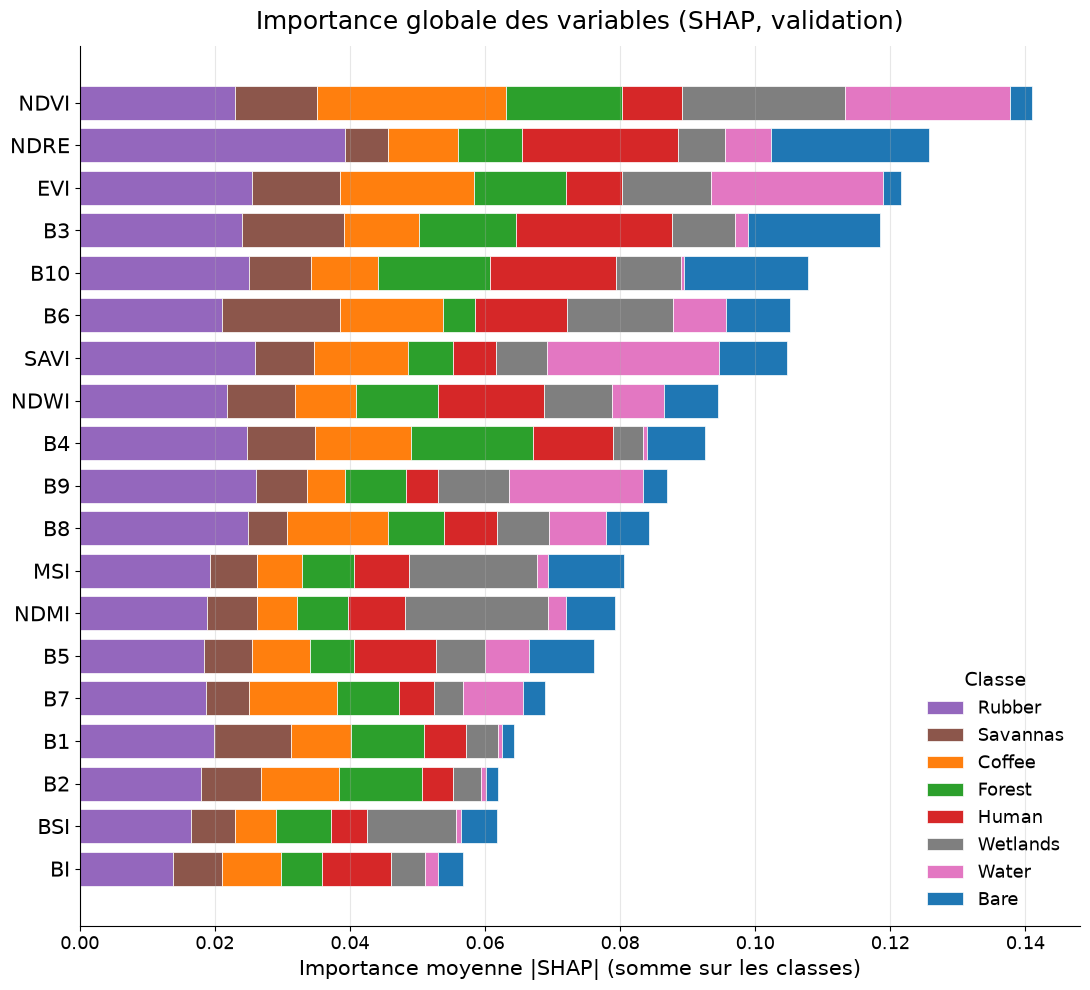

,variable,importance
10,NDVI,0.1410
12,NDRE,0.1257
11,EVI,0.1216
2,B3,0.1185
9,B10,0.1079
5,B6,0.1052
13,SAVI,0.1047
15,NDWI,0.0945


In [51]:
foret_mf = modeles_rf[GRAINES[0]].named_steps["foret"]
Xs_val = modeles_rf[GRAINES[0]].named_steps["standardisation"].transform(Xb_val)
valeurs_shap = np.asarray(shap.TreeExplainer(foret_mf).shap_values(Xs_val))
if valeurs_shap.shape[0] == N_CLASSES:                           # anciennes versions de shap : (classes, obs, variables)
    valeurs_shap = np.transpose(valeurs_shap, (1, 2, 0))
importance = np.abs(valeurs_shap).mean(axis=0)                   # (variables, classes)

ordre_var = np.argsort(importance.sum(axis=1))
fig, ax = plt.subplots(figsize=(11, 10))
gauche = np.zeros(len(VARIABLES))
for k in ordre_classes:
    ax.barh(range(len(VARIABLES)), importance[ordre_var, k], left=gauche, color=COULEURS_CLASSES[NOMS_CLASSES[k]],
            edgecolor="white", lw=0.5, label=noms_courts[k])
    gauche += importance[ordre_var, k]
ax.set_yticks(range(len(VARIABLES)), [VARIABLES[j] for j in ordre_var], fontsize=15)
ax.tick_params(axis="x", labelsize=13)
ax.set_xlabel("Importance moyenne |SHAP| (somme sur les classes)", fontsize=15)
ax.grid(axis="x", alpha=0.3)
for cote in ["top", "right"]:
    ax.spines[cote].set_visible(False)
ax.legend(title="Classe", fontsize=13, title_fontsize=14, loc="lower right", frameon=False)
ax.set_title("Importance globale des variables (SHAP, validation)", fontsize=18, pad=12)
plt.tight_layout()
plt.show()

classement_shap = (pd.DataFrame({"variable": VARIABLES, "importance": importance.sum(axis=1)})
                   .sort_values("importance", ascending=False))
display(classement_shap.head(8).round(4))

Quelle que soit la variable, Rubber occupe une part importante de la barre : chaque variable sert d'abord à décider si une observation est ou non de la classe majoritaire.

Les indices de végétation arrivent en tête : NDVI (0,141), NDRE (0,126) et EVI (0,122), suivis de bandes du visible et du proche infrarouge (B3, B10, B6) et de SAVI. Les indices d'humidité (MSI, NDMI, BSI) et BI sont parmi les moins importants. L'importance reste cependant répartie : aucune variable ne domine, la moins utile (BI, 0,057) pèse encore environ deux fois moins que la plus utile.

Chaque classe s'appuie sur ses propres variables :
- NDRE porte surtout Rubber et Bare Soil ;
- NDVI, EVI et SAVI portent surtout Water et Coffee ;
- B3, B10 et NDRE portent Human et Bare Soil ;
- NDMI, MSI et BSI servent presque uniquement à Wetlands ;
- B6 ressort pour Savannas, B4 et NDVI pour Forest.

#### 6.3 Sens de l'effet pour les classes végétales


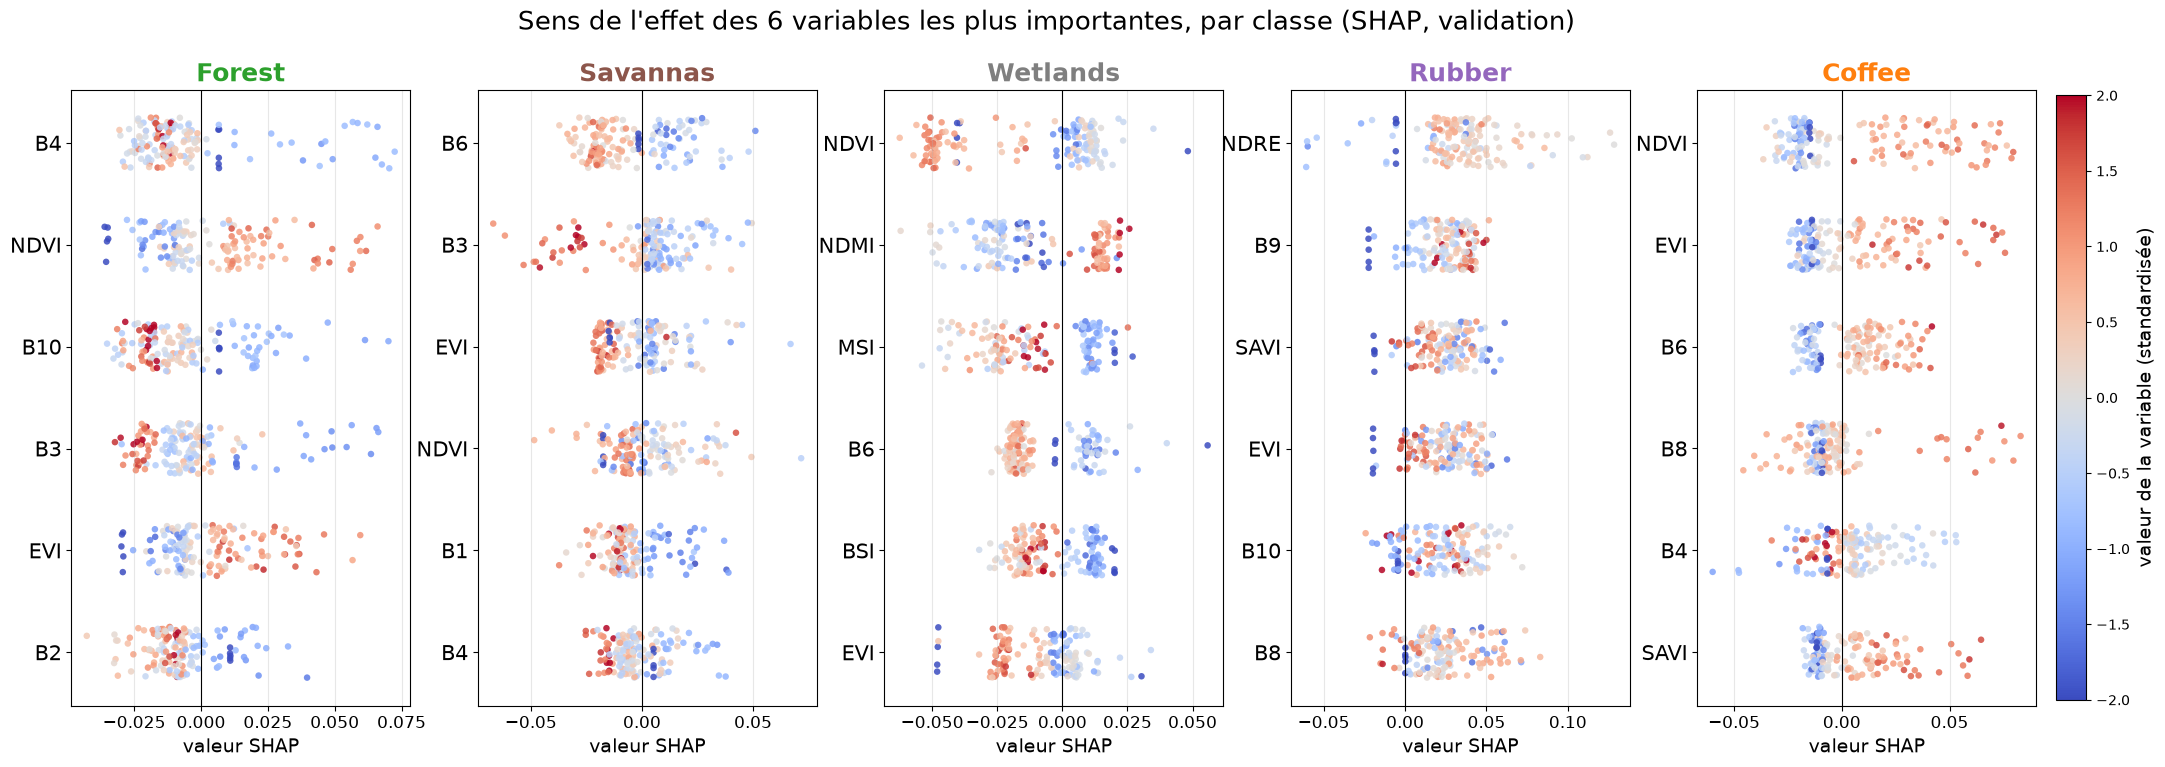

In [53]:
CLASSES_ETUDIEES = ["Forest", "Savannas", "Wetlands", "Rubber", "Coffee"]
k_etudiees = [next(k for k, n in enumerate(NOMS_CLASSES) if n.startswith(c)) for c in CLASSES_ETUDIEES]
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, len(k_etudiees), figsize=(26, 8))
for ax, k in zip(axes, k_etudiees):
    top = np.argsort(importance[:, k])[::-1][:6][::-1]          # 6 variables les plus importantes pour la classe
    for yi, j in enumerate(top):
        ax.scatter(valeurs_shap[:, j, k], yi + rng.uniform(-0.25, 0.25, len(Xs_val)), c=np.clip(Xs_val[:, j], -2, 2),
                   cmap="coolwarm", vmin=-2, vmax=2, s=22, edgecolor="none", alpha=0.85)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(range(len(top)), [VARIABLES[j] for j in top], fontsize=15)
    ax.tick_params(axis="x", labelsize=12)
    ax.set_xlabel("valeur SHAP", fontsize=14)
    ax.set_title(noms_courts[k], fontsize=18, color=COULEURS_CLASSES[NOMS_CLASSES[k]], fontweight="bold")
    ax.grid(axis="x", alpha=0.3)
barre = fig.colorbar(plt.cm.ScalarMappable(cmap="coolwarm", norm=plt.Normalize(-2, 2)), ax=axes, fraction=0.015, pad=0.01)
barre.set_label("valeur de la variable (standardisée)", fontsize=14)
fig.suptitle("Sens de l'effet des 6 variables les plus importantes, par classe (SHAP, validation)", fontsize=19)
plt.show()

Ce graphique montre dans quel sens chaque variable agit : un point à droite pousse vers la classe, et sa couleur indique si la valeur de la variable est élevée (rouge) ou faible (bleu).

- **Forest** est reconnue par des indices de végétation élevés (NDVI, EVI) et de faibles réflectances dans les bandes B2, B3, B4 et B10 : un couvert dense qui absorbe la lumière visible.
- **Coffee** est aussi reconnue par des NDVI, EVI et SAVI élevés, mais se distingue de Forest par des valeurs élevées de B6 et B8. Ce point commun sur les indices de végétation explique leurs confusions.
- **Wetlands** est reconnue par un NDMI élevé et des MSI, BSI et NDVI faibles : une surface humide et peu végétalisée.
- **Rubber** est favorisée par un NDRE élevé, tandis que des indices de végétation faibles (NDRE, SAVI, EVI) l'excluent nettement. La plupart des points sont à droite : par défaut, le modèle penche vers la classe majoritaire.
- **Savannas** est favorisée par des valeurs faibles de B6, B3 et EVI, une végétation moins vigoureuse, mais avec des effets faibles et dispersés. Le modèle n'a pas de signal net pour cette classe, ce qui explique son faible rappel.

57 erreurs sur 150 observations de validation (graine 0)


,confusion,observations
0,Savannas → Rubber,10
1,Rubber → Coffee,8
2,Coffee → Rubber,6
3,Human → Rubber,5
4,Rubber → Forest,5
5,Rubber → Savannas,4


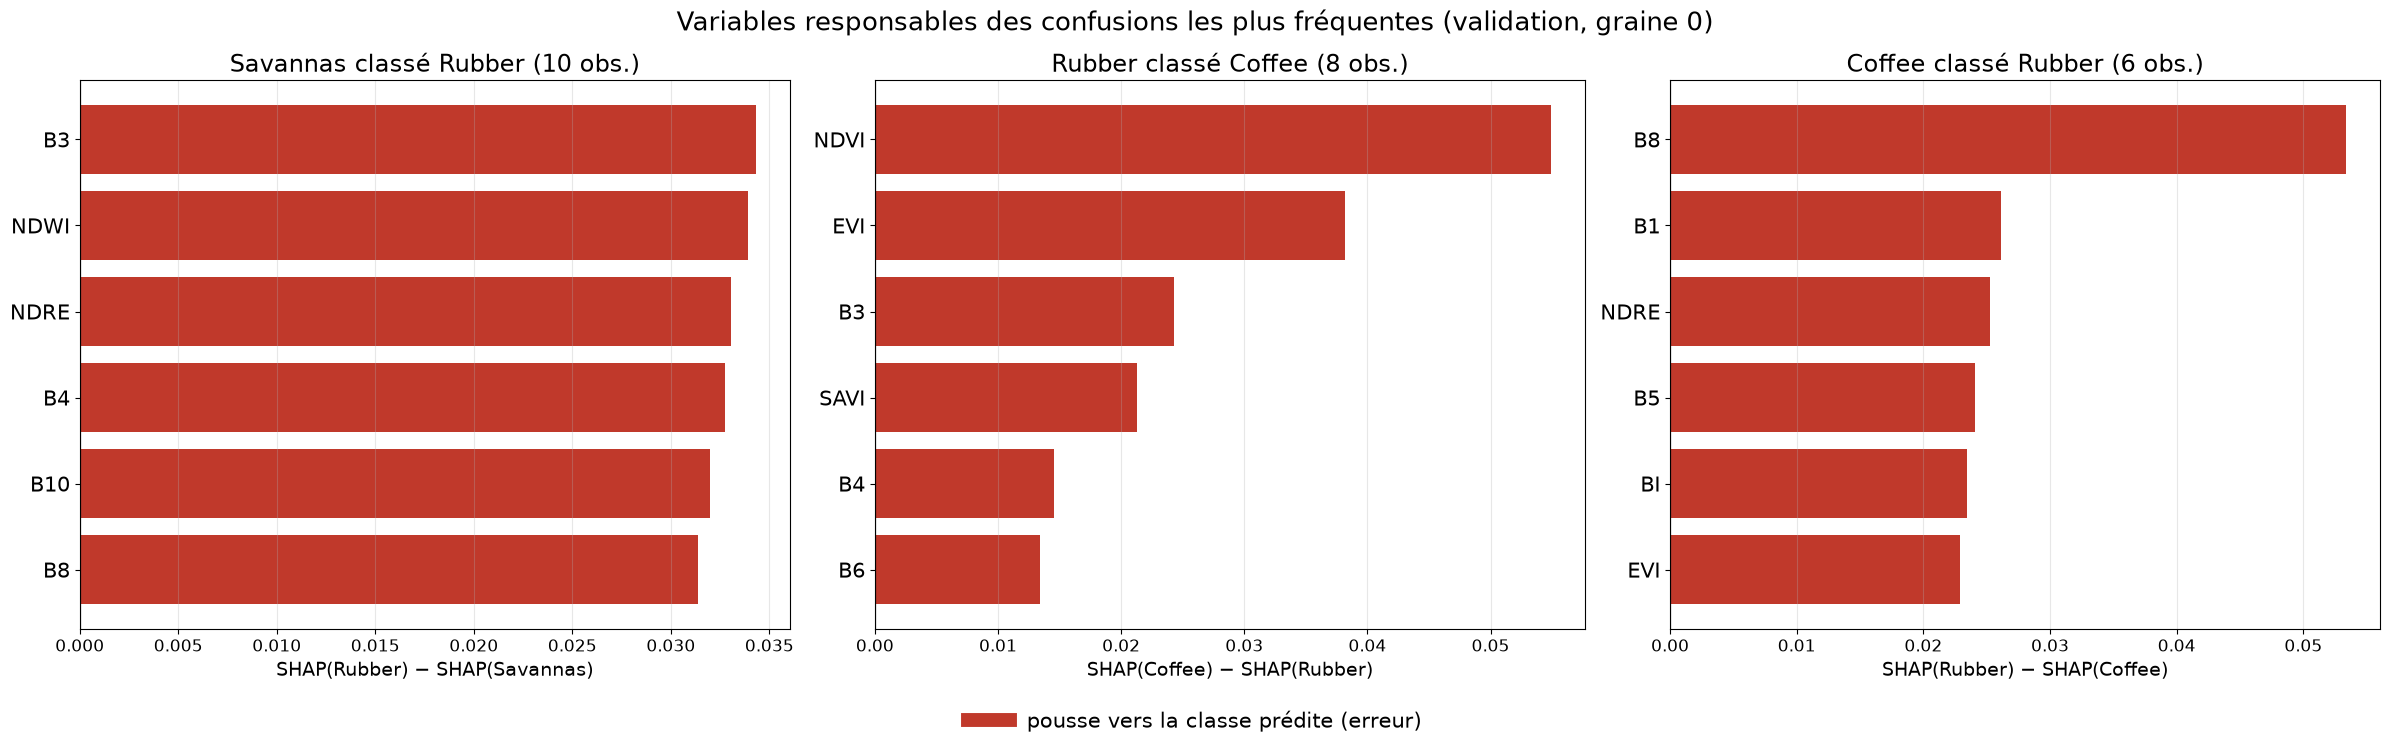

In [54]:
pred0 = pred_val_rf[GRAINES[0]]
erreurs = pd.Series([(v, p) for v, p in zip(y_val, pred0) if v != p]).value_counts()
print(f"{(pred0 != y_val).sum()} erreurs sur {len(y_val)} observations de validation (graine 0)")
display(pd.DataFrame({"confusion": [f"{noms_courts[v]} → {noms_courts[p]}" for v, p in erreurs.index],
                      "observations": erreurs.values}).head(6))

paires = list(erreurs.index[:3])
fig, axes = plt.subplots(1, len(paires), figsize=(8 * len(paires), 7))
lignes_erreurs = []
for ax, (v, p) in zip(np.atleast_1d(axes), paires):
    sel = (y_val == v) & (pred0 == p)
    poussee = (valeurs_shap[sel, :, p] - valeurs_shap[sel, :, v]).mean(axis=0)
    top = np.argsort(np.abs(poussee))[::-1][:6][::-1]
    ax.barh(range(len(top)), poussee[top], color=["#c0392b" if poussee[j] > 0 else "#2e5c8b" for j in top])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(range(len(top)), [VARIABLES[j] for j in top], fontsize=15)
    ax.tick_params(axis="x", labelsize=12)
    ax.set_xlabel(f"SHAP({noms_courts[p]}) − SHAP({noms_courts[v]})", fontsize=14)
    ax.set_title(f"{noms_courts[v]} classé {noms_courts[p]} ({sel.sum()} obs.)", fontsize=17)
    ax.grid(axis="x", alpha=0.3)
    lignes_erreurs += [{"confusion": f"{noms_courts[v]} → {noms_courts[p]}", "variable": VARIABLES[j], "poussee": poussee[j]}
                       for j in top[::-1]]
legende = [Line2D([0], [0], color="#c0392b", lw=10, label="pousse vers la classe prédite (erreur)")]
if any(l["poussee"] < 0 for l in lignes_erreurs):
    legende.append(Line2D([0], [0], color="#2e5c8b", lw=10, label="pousse vers la vraie classe"))
fig.legend(handles=legende, loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False, fontsize=15)
fig.suptitle("Variables responsables des confusions les plus fréquentes (validation, graine 0)", fontsize=19)
plt.tight_layout()
plt.show()


- **Savannas classée Rubber (10 observations) :** la poussée est répartie presque à égalité entre six variables (B3, NDWI, NDRE, B4, B10, B8, de 0,031 à 0,034). Aucune variable n'est seule en cause : c'est l'ensemble de la signature spectrale de ces savanes qui ressemble à celle de Rubber.
- **Rubber classée Coffee (8 observations) :** NDVI (0,055) et EVI (0,038) dominent. Ces parcelles de Rubber ont une végétation aussi vigoureuse que celle du café, or des indices de végétation élevés sont justement ce qui caractérise Coffee.
- **Coffee classée Rubber (6 observations) :** B8 domine nettement (0,053). La variable qui distingue habituellement Coffee de Rubber joue ici en faveur de Rubber.

Ces erreurs confirment la ressemblance spectrale entre classes végétales, en particulier entre les deux cultures arborées.

### 7. Évaluation finale sur le jeu de test

Test utilisé une seule fois, standardisé par le pipeline avec les paramètres de l'entraînement. Métriques de l'énoncé, avec la validation pour comparaison.

In [55]:
Xb_test, y_test = X[idx_test], y[idx_test]
pred_test_rf = {g: modeles_rf[g].predict(Xb_test) for g in GRAINES}

lignes = []
for g in GRAINES:
    for ensemble_eval, y_vrai, pred in [("validation", y_val, pred_val_rf[g]), ("test", y_test, pred_test_rf[g])]:
        lignes.append({"ensemble": ensemble_eval, "graine": g, **calculer_metriques(y_vrai, pred),
                       "kappa": cohen_kappa_score(y_vrai, pred)})
resultats_test = pd.DataFrame(lignes)

cols_test = ["f1_macro", "recall_macro", "precision_macro", "f1_pondere", "kappa", "mcc", "accuracy"]
st_test = resultats_test.groupby("ensemble")[cols_test].agg(["mean", "std"]).loc[["validation", "test"]]
tableau_test = pd.DataFrame({c: [f"{st_test.loc[e, (c, 'mean')]:.3f} ± {st_test.loc[e, (c, 'std')]:.3f}" for e in st_test.index]
                             for c in cols_test}, index=st_test.index)
display(tableau_test)

,f1_macro,recall_macro,precision_macro,f1_pondere,kappa,mcc,accuracy
ensemble,,,,,,,
validation,0.450 ± 0.012,0.439 ± 0.014,0.487 ± 0.026,0.607 ± 0.006,0.351 ± 0.014,0.353 ± 0.013,0.623 ± 0.004
test,0.309 ± 0.014,0.308 ± 0.023,0.356 ± 0.023,0.536 ± 0.008,0.225 ± 0.014,0.228 ± 0.014,0.563 ± 0.008


Sur le test, toutes les métriques baissent nettement par rapport à la validation : le Macro-F1 passe de 0,450 ± 0,012 à 0,309 ± 0,014, le rappel de 0,439 à 0,308 et la précision de 0,487 à 0,356. L'accuracy baisse moins (0,623 à 0,563), car Rubber reste bien reconnue. Le Kappa (0,225) et le MCC (0,228) indiquent un accord faible au-delà du hasard.

Le test, utilisé une seule fois, donne l'estimation honnête.il ne contient que 2 observations de Bare Soil, 3 de Water et 4 de Wetlands : chaque erreur sur ces classes pèse lourd dans le Macro-F1.

#### 7.1 Matrice de confusion normalisée et métriques par classe

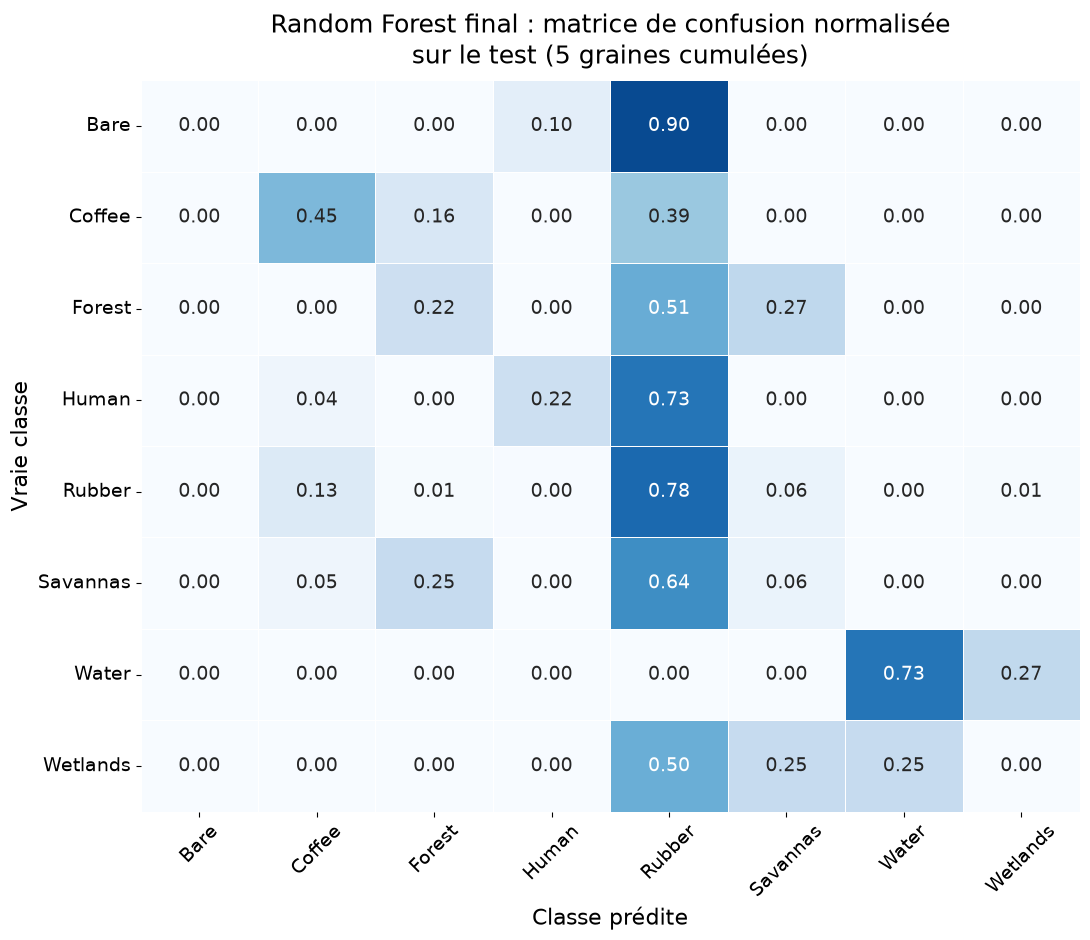

,précision,rappel,F1,n test
Rubber,0.69,0.78,0.73,90
Savannas,0.09,0.06,0.07,16
Coffee,0.34,0.45,0.39,15
Forest,0.25,0.22,0.23,11
Human,0.80,0.22,0.35,9
Wetlands,0.00,0.00,0.00,4
Water,0.68,0.73,0.70,3
Bare,0.00,0.00,0.00,2


In [56]:
cm_test = sum(confusion_matrix(y_test, pred_test_rf[g], labels=range(N_CLASSES)) for g in GRAINES)
fig, ax = plt.subplots(figsize=(11, 9.5))
sns.heatmap(cm_test / cm_test.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=noms_courts, yticklabels=noms_courts, annot_kws={"fontsize": 14},
            linewidths=0.5, linecolor="white", ax=ax)
ax.set_xlabel("Classe prédite", fontsize=16)
ax.set_ylabel("Vraie classe", fontsize=16)
ax.tick_params(axis="x", labelsize=14, rotation=45)
ax.tick_params(axis="y", labelsize=14, rotation=0)
ax.set_title("Random Forest final : matrice de confusion normalisée\nsur le test (5 graines cumulées)", fontsize=18, pad=12)
plt.tight_layout()
plt.show()

# Moyenne sur les 5 graines
par_classe = np.mean([precision_recall_fscore_support(y_test, pred_test_rf[g], labels=range(N_CLASSES), zero_division=0)[:3]
                      for g in GRAINES], axis=0)
tableau_classes = pd.DataFrame({"précision": par_classe[0], "rappel": par_classe[1], "F1": par_classe[2],
                                "n test": np.bincount(y_test, minlength=N_CLASSES)}, index=noms_courts).iloc[ordre_classes]
display(tableau_classes.round(2))

Sur le test, les erreurs suivent le même schéma qu'en validation. Rubber absorbe la plupart des observations mal classées : 90 % de Bare Soil, 73 % de Human, 64 % de Savannas, 51 % de Forest, 50 % de Wetlands et 39 % de Coffee. Seules Rubber (78 %) et Water (73 %) sont bien reconnues ; Coffee l'est à moitié (45 %), Forest et Human rarement (22 %), Savannas presque jamais (6 %), et Wetlands et Bare Soil jamais.

Les autres erreurs se font entre classes proches. Ces pourcentages portent sur très peu d'observations pour les classes rares (2 Bare Soil, 3 Water, 4 Wetlands) donc une seule observation peut les faire varier fortement.

### 8. Sauvegarde du modèle final

Pipeline de la graine 0, avec les variables attendues et les noms des classes. Enregistré dans `resultats/modeles_finaux/random_forest_final.joblib`.

In [57]:
os.makedirs(DOSSIER_FINAL, exist_ok=True)
chemin_modele = os.path.join(DOSSIER_FINAL, "random_forest_final.joblib")
joblib.dump({"pipeline": modeles_rf[GRAINES[0]], "variables": VARIABLES, "classes": NOMS_CLASSES}, chemin_modele)

fiche = {
    "modele": "Random Forest",
    "fichier": "random_forest_final.joblib",
    "pipeline": ["StandardScaler", "RandomOverSampler (entraînement seulement)", "RandomForestClassifier"],
    "hyperparametres": PARAMS_RF,
    "graine": GRAINES[0],
    "entrainement": f"{len(idx_train)} observations (ensemble d'entraînement)",
    "variables": VARIABLES,
    "classes": NOMS_CLASSES,
    "test_5_graines": {c: {"moyenne": round(float(st_test.loc["test", (c, "mean")]), 3),
                           "ecart_type": round(float(st_test.loc["test", (c, "std")]), 3)} for c in cols_test},
}
with open(os.path.join(DOSSIER_FINAL, "fiche_modele_final.json"), "w", encoding="utf-8") as f:
    json.dump(fiche, f, ensure_ascii=False, indent=2, default=str)
print(f"Modèle sauvegardé : {chemin_modele} ({os.path.getsize(chemin_modele) / 1e6:.1f} Mo)")

Modèle sauvegardé : resultats\modeles_finaux\random_forest_final.joblib (30.3 Mo)


## 9. Conclusion générale

Ce projet visait à classer l'occupation du sol autour de Yamoussoukro en 8 classes à partir de 10 bandes Sentinel-2 et de 9 indices spectraux, avec un réseau de neurones comparé à trois méthodes classiques.

Le meilleur ANN (3 couches cachées, SGD avec momentum, GELU, 19 variables) atteint un Macro-F1 de 0,389 ± 0,041 en validation. Mis en concurrence sur le même protocole, Random Forest fait nettement mieux (0,450 ± 0,012), devant XGBoost (0,388) et le SVM (0,377) ; il n'est jamais nettement battu, ni en validation aléatoire ni en validation spatiale. Sur ces données tabulaires, l'ANN ne surpasse donc pas les méthodes classiques.

L'analyse SHAP montre que la forêt s'appuie surtout sur les indices de végétation (NDVI, NDRE, EVI), chaque classe mobilisant ses propres variables : l'humidité (NDMI, MSI) pour Wetlands, le proche infrarouge pour distinguer Coffee de Forest. Ses erreurs viennent de deux sources : l'attraction de la classe majoritaire Rubber et la ressemblance spectrale entre classes végétales.

Sur le test, utilisé une seule fois, le modèle final obtient un Macro-F1 de 0,309 ± 0,014 et une accuracy de 0,563. Ce score, proche de l'estimation de la validation spatiale (0,333), est l'estimation honnête de ses performances : il reconnaît bien Rubber et Water, mais reste faible sur les classes minoritaires.

### 9.1 Limites

**Limites du jeu de données.** Le jeu de données est réduit (1 000 observations) et très déséquilibré : Rubber représente 60 % des observations. La validation et le test ne comptent que 150 observations chacun, dont 1 à 4 seulement pour Bare Soil, Water et Wetlands ; une seule observation suffit à faire varier fortement leurs métriques. Les images proviennent d'une seule date, ce qui ne permet pas de suivre l'évolution saisonnière de la végétation. Enfin, certaines classes sont concentrées dans une seule zone, comme l'eau, ce qui pénalise les modèles en validation spatiale.

**Limites des modèles.** Tous les modèles penchent vers la classe majoritaire, et le rééquilibrage ne corrige ce biais qu'en sacrifiant une partie du rappel de Rubber. Les modèles à arbres collent fortement à l'entraînement ; le SVM a un score fragile et ne reconnaît jamais Human ; l'ANN varie sensiblement d'une graine à l'autre. Le choix des réglages sur la validation a rendu son score optimiste, comme le montre la baisse sur le test (0,450 à 0,309). Enfin, SHAP décrit ce que le modèle utilise, pas les causes de l'occupation du sol.

**Limites des classes.** Plusieurs classes se ressemblent spectralement : les cultures arborées (Rubber, Coffee), les végétations (Forest, Savannas), les surfaces peu végétalisées (Human, Bare Soil) et les milieux humides (Water, Wetlands). La classe « Rubber and Other Crops » est composite et regroupe des cultures différentes, ce qui brouille sa frontière avec les autres végétations. Wetlands mêle eau et végétation, et Bare Soil, trop peu représentée, n'est jamais reconnue.

Perspectives : enrichir l'échantillonnage des classes rares, utiliser des séries temporelles d'images pour exploiter la phénologie des cultures, et ajouter des variables de texture ou de contexte spatial.